In [76]:
# Import packages
from pathlib import Path
import re
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.colors import LinearSegmentedColormap
import numpy as np
import pandas as pd
import warnings
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
import random
import copy
from scipy import signal
import matplotlib.pylab as pl
import matplotlib.transforms as mtransforms
from scipy.optimize import curve_fit
import matplotlib.gridspec as gridspec
from scipy.stats import pearsonr
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
import matplotlib.dates as mdates
import os
%config InlineBackend.figure_format = "retina"

In [4]:
DATA = Path("../Data")

cameras = pd.DataFrame(
    {
        "Site": [
            "Boquillas", "CharlestonMesquite", "Contention", "Fairbank",
            "Hereford", "Hunter", "Moson", "St.David",
        ],
        "Camera": [8, 2, 6, 1, 5, 4, 3, 7],
    }
)

SEASONS = ["CSR", "PMD", "MON", "PMR"]
SEASON_NAMES = {"CSR": "Cool-Season Recharge", "PMD": "Pre-Monsoon Dry", "MON": "Monsoon", "PMR": "Post-Monsoon Recession"}

def water_year(dates):
    return dates.dt.year + (dates.dt.month >= 10).astype(int)

def season(dates):
    month = dates.dt.month
    return np.select(
        [month.isin([12, 1, 2, 3]), month.isin([4, 5, 6]), month.isin([7, 8, 9]), month.isin([10, 11])],
        SEASONS,
        default="",
    )

def load_nagler():
    raw = pd.read_csv(DATA / "ET" / "NaglerET.csv", header=None, skiprows=7)
    site_columns = {
        "Hereford": (3, 6),
        "Hunter": (3, 12),
        "Moson": (3, 18),
        "CharlestonMesquite": (3, 24),
        "Boquillas": (3, 30),
        "Fairbank": (3, 36),
        "Contention": (54, 57),
        "St.David": (54, 63),
    }
    series_list = []
    for site, (date_col, avg_col) in site_columns.items():
        series = raw[[date_col, avg_col]].dropna().copy()
        series.columns = ["date", "ET"]
        series["date"] = pd.to_datetime(series["date"], format="mixed")
        series["ET"] = pd.to_numeric(series["ET"], errors="coerce")
        series["Site"] = site
        series_list.append(series.dropna())
    return pd.concat(series_list, ignore_index=True).merge(cameras, on="Site", validate="many_to_one")

def nagler_to_daily(data):
    """Give each day the rate (mm/day) of the nearest 16-day composite; composite dates drift between years, so no fixed grid."""
    days = pd.DataFrame({"date": pd.date_range(data["date"].min() - pd.Timedelta(days=8), data["date"].max() + pd.Timedelta(days=8))})
    return pd.concat(
        [
            pd.merge_asof(days, group.sort_values("date"), on="date", direction="nearest", tolerance=pd.Timedelta(days=12))
            for _, group in data.groupby("Camera")
        ],
        ignore_index=True,
    ).dropna(subset=["ET"])

et_composites = load_nagler().sort_values(["Camera", "date"]).reset_index(drop=True)
et_daily = nagler_to_daily(et_composites)
et_daily["Water_Year"] = water_year(et_daily["date"])
et_daily["Season"] = season(et_daily["date"])

calendar = pd.DataFrame({
    "date": pd.date_range(f"{et_daily['Water_Year'].min() - 1}-10-01", f"{et_daily['Water_Year'].max()}-09-30")
})
season_lengths = (
    calendar.assign(Water_Year=water_year(calendar["date"]), Season=season(calendar["date"]))
    .groupby(["Water_Year", "Season"]).size().rename("season_days").reset_index()
)
et_seasonal = (
    et_daily.groupby(["Camera", "Water_Year", "Season"], as_index=False)["ET"]
    .agg(ET="sum", n_days="size")
    .merge(season_lengths, on=["Water_Year", "Season"])
    .query("n_days == season_days")
)

et_climatology = (
    et_daily.assign(doy=lambda d: d["date"].dt.dayofyear)
    .query("doy <= 365")
    .groupby(["Camera", "doy"])["ET"]
    .agg(["mean", "std"])
    .reset_index()
    .assign(calendar_date=lambda d: pd.Timestamp("2001-01-01") + pd.to_timedelta(d["doy"] - 1, unit="D"))
)

In [9]:
cameradata = pd.read_csv(DATA / "SPRNCAPredFP.csv", parse_dates=["date"]).rename(columns={"site": "Site"}).merge(cameras, on="Site", validate="many_to_one")

In [16]:
cameradata['season'] = np.where(cameradata.date.dt.month.isin([1,2,3]),
                               'CSR','PMD')
cameradata['season'] = np.where(cameradata.date.dt.month.isin([7,8,9]),
                               'MSN',cameradata.season)
cameradata['season'] = np.where(cameradata.date.dt.month.isin([10,11,12]),
                               'PMR',cameradata.season)

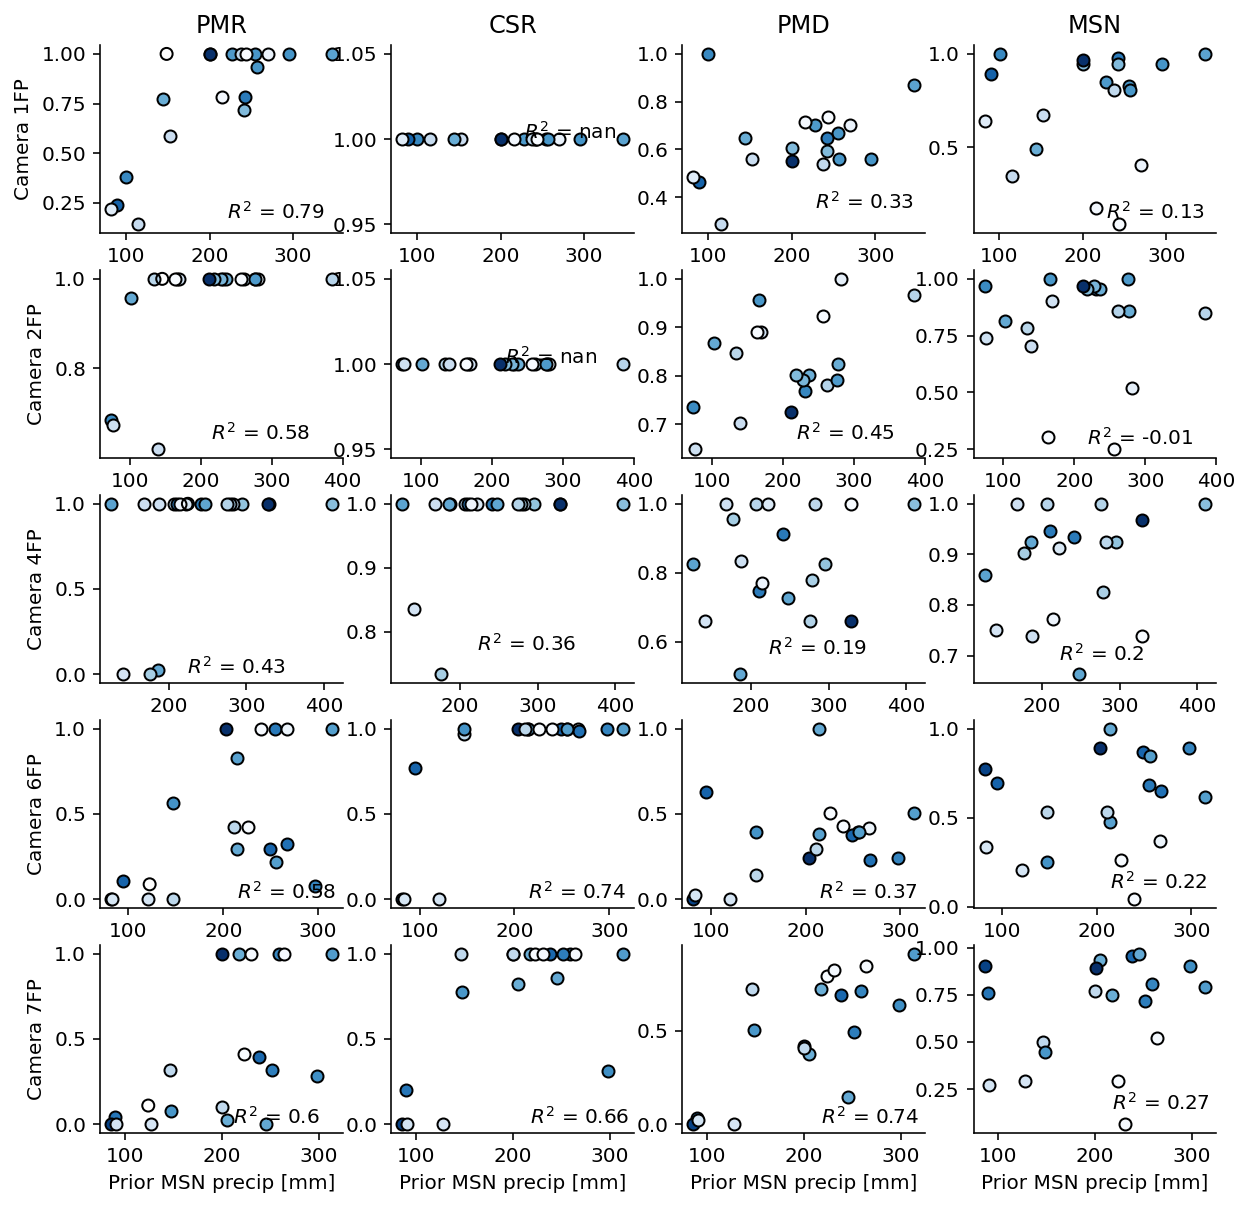

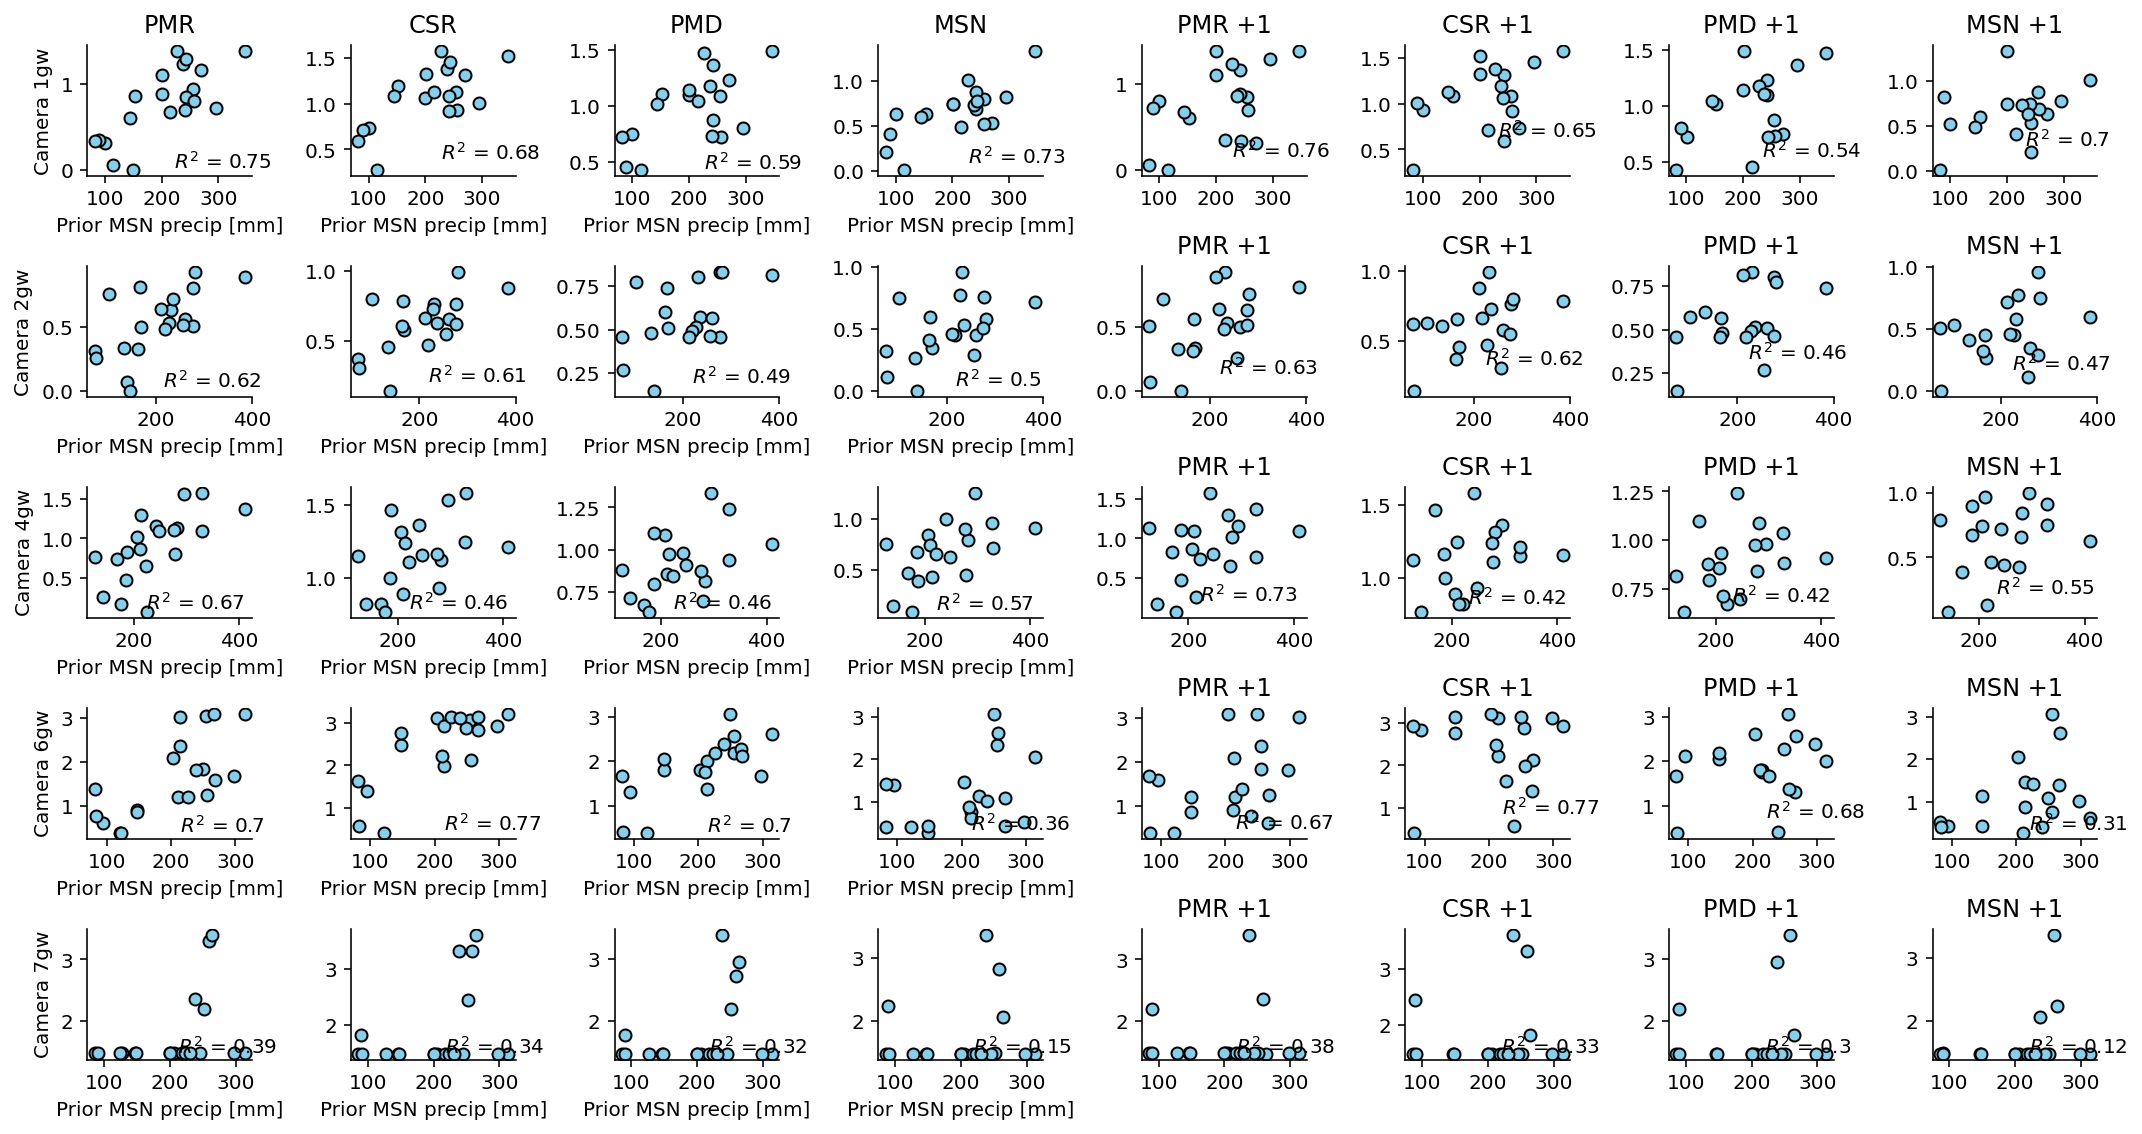

In [111]:
seasonmeans = cameradata.drop(columns=['Site','date','split','source','fp']).groupby(['Camera','wy','season']).mean()
for col in ['prcp','et']:
    seasonmeans[col] = cameradata.drop(columns=['Site','date','split','source','fp']).groupby(['Camera','wy','season']).sum()[col]
seasonmeans.reset_index(inplace=True)
monsoonmedian = seasonmeans[seasonmeans.season=='MSN'].groupby('Camera').prcp.quantile(.75)
# check seasonal relationships
# check if high monsoon precipitation sustains flows in future seasons
fig,axs = plt.subplots(5,4,figsize = (10,10),)#sharey=True)
fig1,axs1 = plt.subplots(5,8,figsize = (15,8),)#sharey=True)
k = 0
for camera in monsoonmedian.index:
    if camera not in [3,5,8]:
        camerasub = seasonmeans[seasonmeans.Camera==camera]
        goodmonsoon = camerasub[(camerasub.season=='MSN')&(camerasub.prcp>monsoonmedian.loc[camera])]
        
        for i,season in enumerate(['PMR','CSR','PMD','MSN']):
            ax = axs[k,i]
            ax1 = axs1[k,i]
            mdata = []
            sdata = []
            gdata = []
            for wy in camerasub[camerasub.season=='MSN'].wy.unique():
                try:
                    gmax = camerasub.gw.max()
                    if camera==7:
                        gmax = 1.5
                    
                    ax.scatter(camerasub[(camerasub.season=='MSN')&(camerasub.wy==wy)].prcp,
                                   camerasub[(camerasub.season==season)&(camerasub.wy==wy+1)].fp_final,
                                   edgecolor = 'k',
                              cmap = 'Blues',
                              c = camerasub[(camerasub.season=='MSN')&(camerasub.wy==wy+1)].prcp,
                              vmin = camerasub[camerasub.season=='MSN'].prcp.min(),
                               vmax = camerasub[camerasub.season=='MSN'].prcp.max())
                    ax1.scatter(camerasub[(camerasub.season=='MSN')&(camerasub.wy==wy)].prcp,
                                   camerasub[(camerasub.season==season)&(camerasub.wy==wy+1)].gw,
                                   edgecolor = 'k',c='skyblue')
                    mdata.append(float(camerasub[(camerasub.season=='MSN')&(camerasub.wy==wy)].prcp))
                    sdata.append(float(camerasub[(camerasub.season==season)&(camerasub.wy==wy+1)].fp_final))
                    gdata.append(float(camerasub[(camerasub.season==season)&(camerasub.wy==wy+1)].gw))
                except:
                    ''
            r2dat = pd.DataFrame.from_dict({'M':mdata,'S':sdata,'G':gdata}).dropna()
            ax.text(np.nanmedian(mdata),
                    np.percentile(sdata,2),
                    '$R^2$ = '+str(round(pearsonr(r2dat.M,r2dat.S)[0],2)))
            ax1.text(np.nanmedian(mdata),
                     np.percentile(gdata,2),
                     '$R^2$ = '+str(round(pearsonr(r2dat.M,r2dat.G)[0],2)))
            ax.set_xlabel('Prior MSN precip [mm]')
            ax1.set_xlabel('Prior MSN precip [mm]')
            if i==0:
                ax.set_ylabel('Camera '+str(camera)+'FP')
                ax1.set_ylabel('Camera '+str(camera)+'gw')
            if k==0:
                ax.set_title(season)
                ax1.set_title(season)
            ax.spines[['top','right']].set_visible(False)
            ax1.spines[['top','right']].set_visible(False)
        for i,season in enumerate(['PMR','CSR','PMD','MSN']):
            mdata1 = []
            gdata1 = []
            ax1 = axs1[k,i+4]
            for wy in camerasub[camerasub.season=='MSN'].wy.unique():
                try:
                    gmax = camerasub.gw.max()
                    if camera==7:
                        gmax = 1.5
                    
                    ax1.scatter(camerasub[(camerasub.season=='MSN')&(camerasub.wy==wy)].prcp,
                                   camerasub[(camerasub.season==season)&(camerasub.wy==wy+2)].gw,
                                   edgecolor = 'k',
                              c = 'skyblue')
                    mdata1.append(float(camerasub[(camerasub.season=='MSN')&(camerasub.wy==wy)].prcp))
                    gdata1.append(float(camerasub[(camerasub.season==season)&(camerasub.wy==wy+1)].gw))
                except:
                    ''
            r2dat1 = pd.DataFrame.from_dict({'M':mdata1,'G':gdata1}).dropna()
            ax1.spines[['top','right']].set_visible(False)
            ax1.set_title(season+' +1')
            ax1.text(np.nanmedian(mdata1),
                     np.percentile(gdata1,2),
                     '$R^2$ = '+str(round(pearsonr(r2dat1.M,r2dat1.G)[0],2)))
#         fig.suptitle(camera)
        fig1.tight_layout()
        k+=1
    

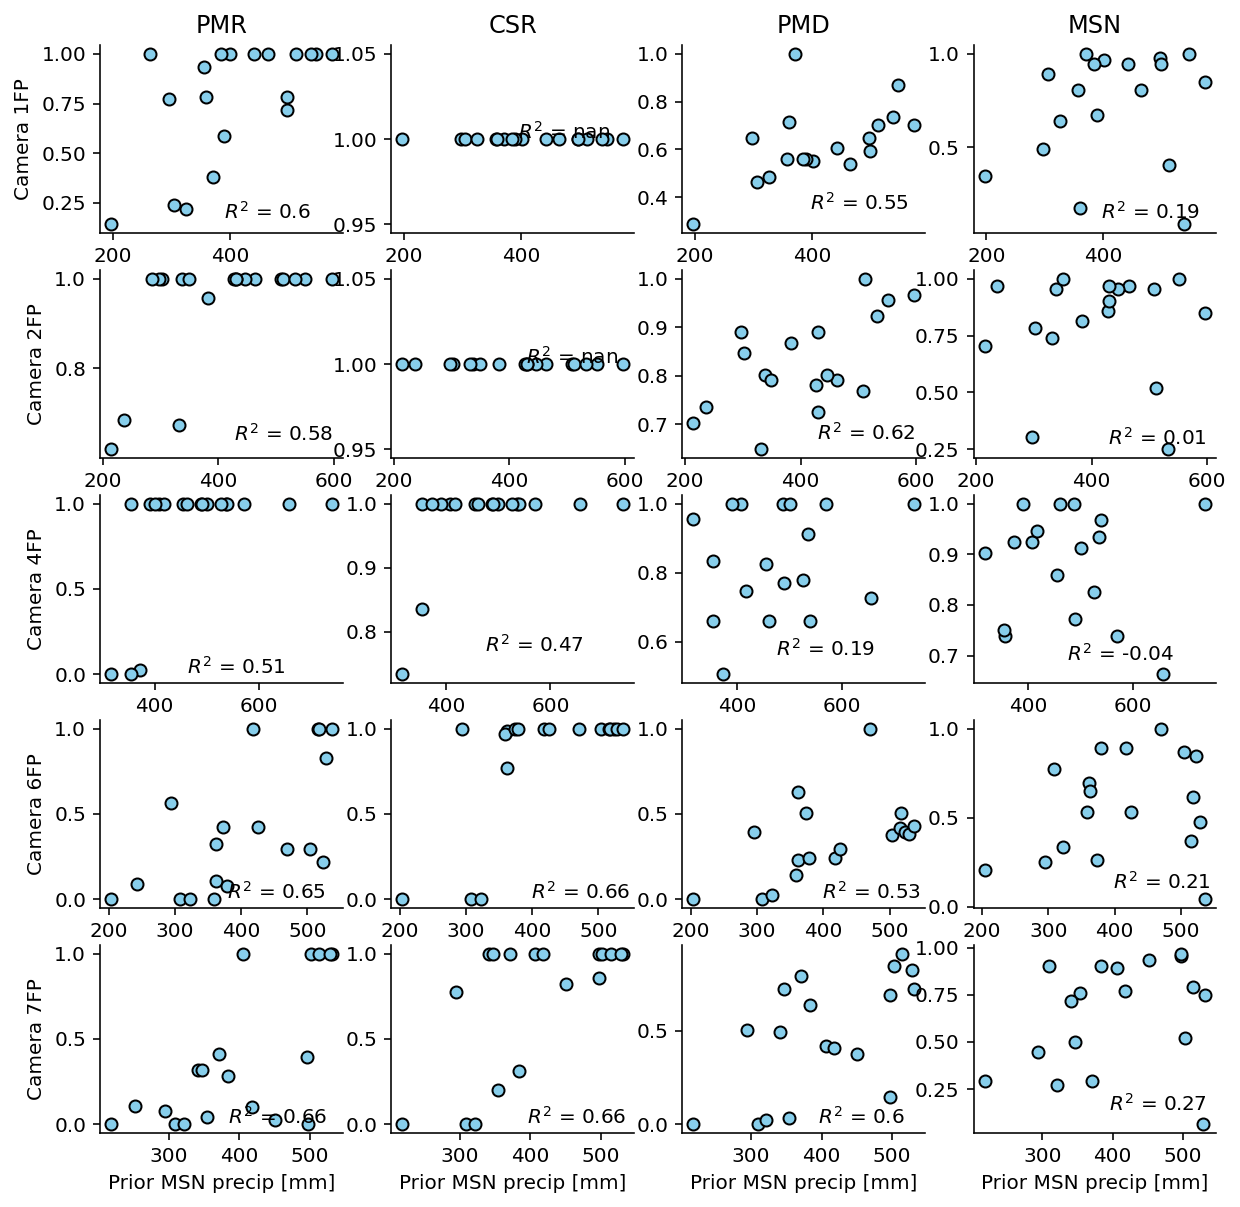

In [117]:
seasonmeans = cameradata.drop(columns=['Site','date','split','source','fp']).groupby(['Camera','wy','season']).mean()
for col in ['prcp','et']:
    seasonmeans[col] = cameradata.drop(columns=['Site','date','split','source','fp']).groupby(['Camera','wy','season']).sum()[col]
seasonmeans.reset_index(inplace=True)
monsoonmedian = seasonmeans[seasonmeans.season=='MSN'].groupby('Camera').prcp.quantile(.75)
# check seasonal relationships
# check if high monsoon precipitation sustains flows in future seasons
fig,axs = plt.subplots(5,4,figsize = (10,10),)
k = 0
for camera in monsoonmedian.index:
    if camera not in [3,5,8]:
        camerasub = seasonmeans[seasonmeans.Camera==camera]
        goodmonsoon = camerasub[(camerasub.season=='MSN')&(camerasub.prcp>monsoonmedian.loc[camera])]
        
        for i,season in enumerate(['PMR','CSR','PMD','MSN']):
            ax = axs[k,i]
            ax1 = axs1[k,i]
            mdata = []
            sdata = []
            for wy in camerasub[camerasub.season=='MSN'].wy.unique()[1:]:
                try:
                    md = camerasub[(camerasub.season=='MSN')&
                                         ((camerasub.wy==wy)|(camerasub.wy==wy-1))].prcp.sum()
                    fp1 = camerasub[(camerasub.season==season)&(camerasub.wy==wy+1)].fp_final
                    ax.scatter(md,
                                   fp1,
                                   edgecolor = 'k',
                              c = 'skyblue')
                    mdata.append(float(md))
                    sdata.append(float(fp1))
                except:
                    ''
            r2dat = pd.DataFrame.from_dict({'M':mdata,'S':sdata,}).dropna()
            ax.text(np.nanmedian(mdata),
                    np.percentile(sdata,2),
                    '$R^2$ = '+str(round(pearsonr(r2dat.M,r2dat.S)[0],2)))
            ax.set_xlabel('Prior MSN precip [mm]')
            if i==0:
                ax.set_ylabel('Camera '+str(camera)+'FP')
            if k==0:
                ax.set_title(season)
            ax.spines[['top','right']].set_visible(False)

        k+=1
    

In [313]:
r2vals = []
ssns = []
comparison = []
wycompare = []
cameras = []
for camera in monsoonmedian.index[:]:
    if camera not in [3,5,8]:
        camerasub = seasonmeans[seasonmeans.Camera==camera]
        for ssn in ['PMR','CSR','PMD','MSN']:
            for seasoncompare in ['CSR','MSN','PMD','PMR']:
                for wylag in [0,1,2]:
                    if (seasoncompare=='CSR') & (ssn=='PMR'):
                        wylag1 = wylag + 1
                    elif (seasoncompare=='MSN'):
                        wylag1 = wylag + 1
                        if ssn=='MSN':
                            wylag1 = wylag
                    elif (seasoncompare=='PMD') & (ssn in ['CSR','PMR']):
                        wylag1 = wylag + 1
                    else:
                        wylag1 = wylag

                    pcomp = camerasub[camerasub.season==ssn].set_index('wy')
                    mcomp = camerasub[camerasub.season==seasoncompare]
                    if wylag>=1:
                        mcomp1 = mcomp.copy()
                        mcomp1['wy'] = mcomp1.wy+wylag1-wylag
                        mcomp1.set_index('wy',inplace=True)
                    mcomp['wy'] = mcomp.wy+wylag1
                    mcomp.set_index('wy',inplace=True)
                    if wylag>=1:
                        mcomp = mcomp[['prcp']].merge(mcomp1[['prcp']].rename(columns={'prcp':'prcp1'}),
                                                      left_index=True,right_index=True)
                        mcomp['prcp'] = mcomp.prcp+mcomp.prcp1
                    if wylag==2:
                        mcomp2 = mcomp1.reset_index()
                        mcomp2['wy'] = mcomp2.wy+wylag-1
                        mcomp2.set_index('wy',inplace=True)
                        mcomp = mcomp[['prcp']].merge(mcomp2[['prcp']].rename(columns={'prcp':'prcp2'}),
                                                      left_index=True,right_index=True)
                        mcomp['prcp'] = mcomp.prcp+mcomp.prcp2
                    
                    r2d = pcomp[['fp_final']].merge(mcomp[['prcp']],
                                                   left_index=True,right_index=True).dropna()
            
                    ssns.append(ssn)
                    comparison.append(seasoncompare)
                    wycompare.append(wylag)
                    r2vals.append(pearsonr(r2d.fp_final,r2d.prcp)[0])
                    cameras.append(camera)
                    
            wylagm = 1
            wylagc = 0
            if ssn=='MSN':
                wylagm = 0
            if ssn=='PMR':
                wylagc = 1
            pcomp = camerasub[camerasub.season==ssn].set_index('wy')
            mcompm = camerasub[camerasub.season=='MSN']
            mcompm['wy'] = mcompm.wy+wylagm
            mcompm.set_index('wy',inplace=True)
            mcompc = camerasub[camerasub.season=='CSR']
            mcompc['wy'] = mcompc.wy+wylagc
            mcompc.set_index('wy',inplace=True)
            mcomp = mcompm[['prcp']].merge(mcompc[['prcp']],left_index=True,right_index=True)
            mcomp['prcp'] = mcomp.prcp_x+mcomp.prcp_y
            r2d = mcomp[['prcp']].merge(pcomp[['fp_final']],left_index=True,right_index=True)
            
            ssns.append(ssn)
            comparison.append('MSN+CSR')
            wycompare.append(0)
            r2vals.append(pearsonr(r2d.fp_final,r2d.prcp)[0])
            cameras.append(camera)
lagdata = pd.DataFrame.from_dict({'Camera':cameras,
                    'Season':ssns,
                       'SeasonCompare':comparison,
                       'Lag':wycompare,
                       'r2':r2vals})

In [315]:
# for season in lagdata.Season.unique():
#     for camera in lagdata.Camera.unique():
    
#         lsub = (lagdata[(lagdata.Camera==camera)&
#                      (lagdata.Season==season)])
#         print(lsub[lsub.r2>=lsub.r2.max()-.1])

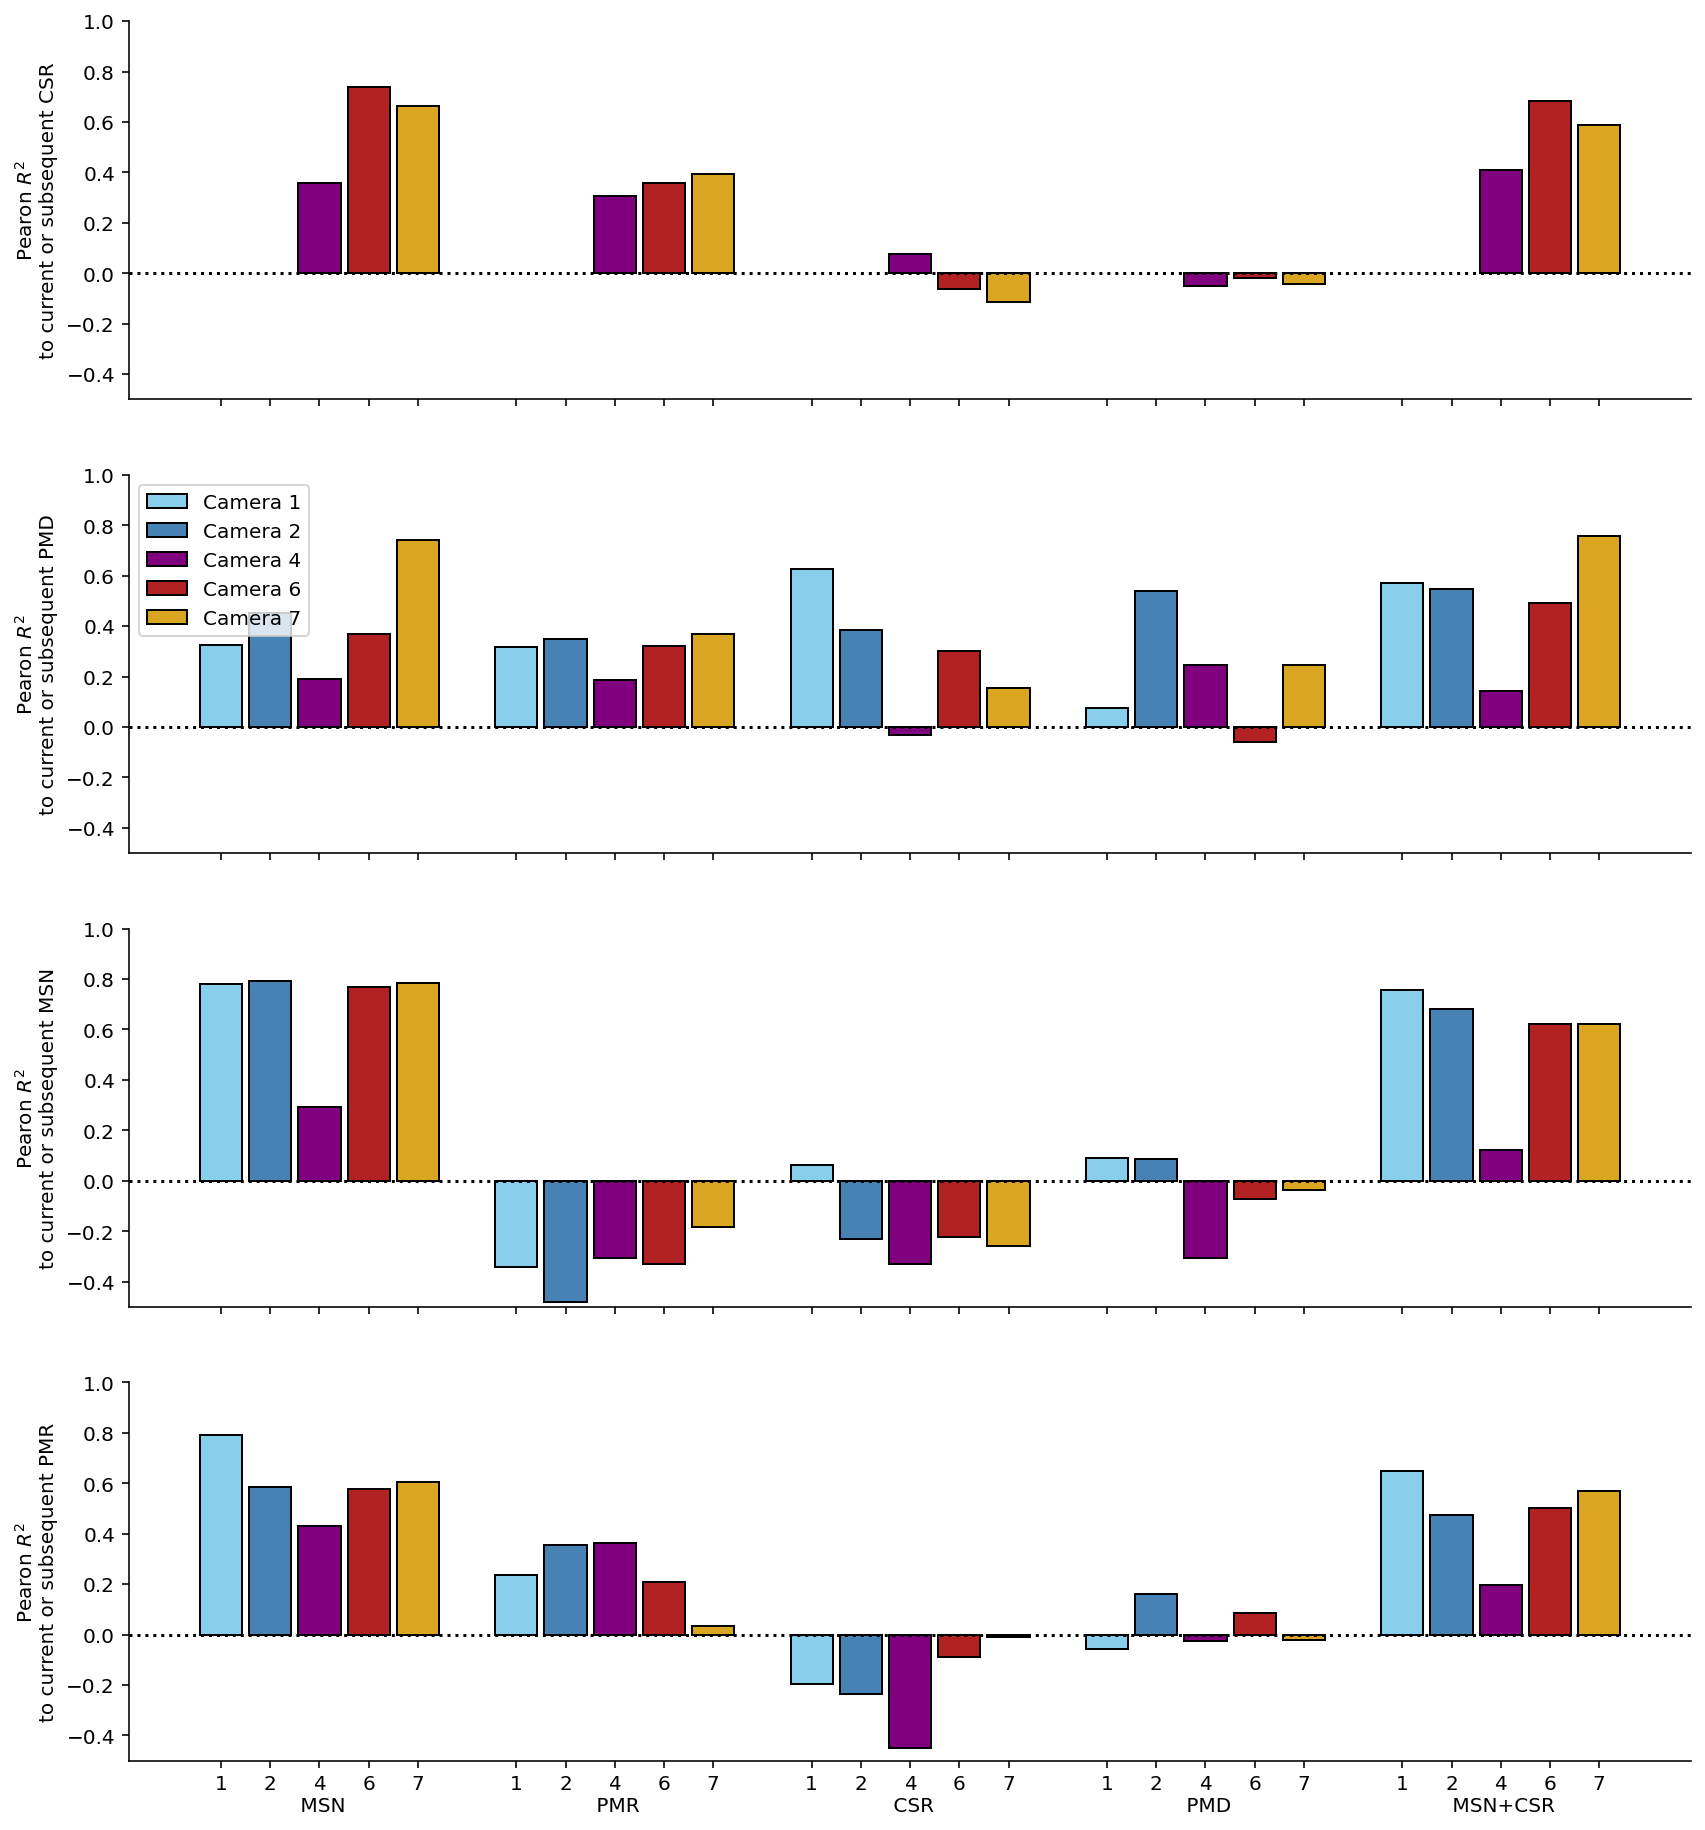

In [334]:
fig, axs = plt.subplots(4,figsize = (14,16),sharex=True,sharey=True)

xtickle = {'MSN':0, 'CSR':2,'MSN+CSR':4,'PMD':3,'PMR':1}

for i,season in enumerate(['CSR','PMD','MSN','PMR',]):
    ax = axs[i]
    
    camcolors = ['skyblue','steelblue','purple','firebrick','goldenrod']
    for p,camera in enumerate(lagdata.Camera.unique()):
    
        lsub = (lagdata[(lagdata.Camera==camera)&
                     (lagdata.Season==season)&(lagdata.Lag==0)])
#         lsub = (lsub[lsub.r2>=lsub.r2.max()-.1])
        for j in range(len(lsub)):
            if j==0:
                lab = 'Camera '+str(camera)
            else:
                lab = None
            ax.bar([xtickle[lsub.SeasonCompare.values[j]]+p/6],
                  [lsub.r2.values[j]],width = 1/7,edgecolor = 'k',
                  facecolor = camcolors[p],label=lab)
        
    if i==1:
        ax.legend()
    
    ax.spines[['top','right']].set_visible(False)
#     ax.set_title(season)
    ax.axhline(0,c='k',ls=':')
    ax.set_xticks([0+p/6 for p in range(5)]+
                 [1+p/6 for p in range(5)]+
                 [2+p/6 for p in range(5)]+
                 [3+p/6 for p in range(5)]+
                 [4+p/6 for p in range(5)])
    camlist = list(lagdata.Camera.unique())
    camlist = [str(t) for t in camlist]
    ax.set_ylabel('Pearon $R^2$\nto current or subsequent '+season)
    camlabs = camlist[:2]+[str(camlist[2])+'\n MSN']+camlist[3:]+camlist[:2]+[str(camlist[2])+'\n PMR']
    camlabs = camlabs + camlist[3:]+camlist[:2]+[str(camlist[2])+'\n CSR']
    camlabs = camlabs + camlist[3:]+camlist[:2]+[str(camlist[2])+'\n PMD']
    camlabs = camlabs + camlist[3:]+camlist[:2]+[str(camlist[2])+'\n MSN+CSR']+camlist[3:]
    ax.set_xticklabels(camlabs)
    ax.set_ylim(-.5,1)

In [332]:
camlabs

['1',
 '2',
 '4\n MSN',
 '6',
 '7',
 '1',
 '2',
 '4\n PMR',
 '6',
 '7',
 '1',
 '2',
 '4\n CSR',
 '6',
 '7',
 '6',
 '7',
 '1',
 '2',
 '4\n PMD',
 '6',
 '7']

In [307]:
r2valset = []
r2valsvpd = []
r2valstmax = []
ssns = []
comparison = []
wycompare = []
cameras = []
for camera in monsoonmedian.index[:]:
    if camera not in [3,5,8]:
        camerasub = seasonmeans[seasonmeans.Camera==camera]
        for ssn in ['PMR','CSR','PMD','MSN']:
            for seasoncompare in ['CSR','MSN','PMD','PMR']:
                for wylag in [0,]:#1,2]:
                    if (seasoncompare=='CSR') & (ssn=='PMR'):
                        wylag1 = wylag + 1
                    elif (seasoncompare=='MSN'):
                        wylag1 = wylag + 1
                        if ssn=='MSN':
                            wylag1 = wylag
                    else:
                        wylag1 = wylag

                    pcomp = camerasub[camerasub.season==ssn].set_index('wy')
                    mcomp = camerasub[camerasub.season==seasoncompare]
#                     if wylag>=1:
#                         mcomp1 = mcomp.copy()
#                         mcomp1['wy'] = mcomp1.wy+wylag1-wylag
#                         mcomp1.set_index('wy',inplace=True)
                    mcomp['wy'] = mcomp.wy+wylag1
                    mcomp.set_index('wy',inplace=True)
#                     if wylag>=1:
#                         mcomp = mcomp[['prcp']].merge(mcomp1[['prcp']].rename(columns={'prcp':'prcp1'}),
#                                                       left_index=True,right_index=True)
#                         mcomp['prcp'] = mcomp.prcp+mcomp.prcp1
#                     if wylag==2:
#                         mcomp2 = mcomp1.reset_index()
#                         mcomp2['wy'] = mcomp2.wy+wylag-1
#                         mcomp2.set_index('wy',inplace=True)
#                         mcomp = mcomp[['prcp']].merge(mcomp2[['prcp']].rename(columns={'prcp':'prcp2'}),
#                                                       left_index=True,right_index=True)
#                         mcomp['prcp'] = mcomp.prcp+mcomp.prcp2
                    
                    r2d = pcomp[['fp_final']].merge(mcomp[['et','vpd','tmax']],
                                                   left_index=True,right_index=True).dropna()
                    
            
            
                    ssns.append(ssn)
                    comparison.append(seasoncompare)
                    wycompare.append(0)
                    r2valset.append(pearsonr(r2d.fp_final,r2d.et)[0])
                    r2valsvpd.append(pearsonr(r2d.fp_final,r2d.vpd)[0])
                    r2valstmax.append(pearsonr(r2d.fp_final,r2d.tmax)[0])
                    cameras.append(camera)
lagdataET = pd.DataFrame.from_dict({'Camera':cameras,
                    'Season':ssns,
                       'SeasonCompare':comparison,
                       'Lag':wycompare,
                       'r2_ET':r2valset,
                       'r2_vpd':r2valsvpd,
                       'r2_tmax':r2valstmax})

In [348]:
seasonmeans['seasonum'] = np.where(season)

,Camera,wy,season,prcp,tmax,tmin,vpd,et,gw,q,prob,prob_all,fp_final
0,1,2006,CSR,6.11,20.722000,1.251889,1.347442,80.003580,0.614642,9.417333,0.999783,0.999619,1.000000
1,1,2006,MSN,254.84,31.876196,17.513152,1.902486,373.834732,0.707125,306.939130,0.754364,0.772387,0.717391
2,1,2006,PMD,8.03,32.473736,12.470989,2.694566,256.730886,0.576018,1.430220,0.570983,0.582326,0.527473
3,1,2007,CSR,60.35,18.707889,0.943111,1.008678,72.808798,1.130902,11.945222,0.999855,0.999682,1.000000
4,1,2007,MSN,242.24,33.232500,18.568261,1.914711,372.862624,0.796296,113.133478,0.806623,0.814843,0.826087
...,...,...,...,...,...,...,...,...,...,...,...,...,...
75,1,2025,CSR,2.34,21.195333,1.272111,1.351691,94.550457,0.276173,0.000000,0.996221,0.986528,1.000000
76,1,2025,MSN,148.61,34.745000,18.889891,2.586429,394.938078,0.008149,24.138696,0.368562,0.407098,0.347826
77,1,2025,PMD,14.91,31.740879,12.275824,2.640731,257.890387,0.427339,0.000000,0.712329,0.424884,0.285714
78,1,2025,PMR,10.92,25.478533,4.787609,1.622109,194.317446,0.066048,0.000000,0.283617,0.193350,0.141304


In [387]:
import pingouin as pg
ssub = seasonmeans[(seasonmeans.season=='MSN')&(seasonmeans.Camera==1)]
pg.partial_corr(data=ssub, x="fp_final", y="prcp", covar=["vpd",'gw','tmax','et'],
               method='spearman').round(3)

,n,r,CI95%,p-val
spearman,20,0.463,"[-0.04, 0.78]",0.071


In [668]:
st = cameradata.drop(columns=['Site','split','source','fp','season'])
stcam = []
for camera in st.Camera.unique():
    st1 = st[st.Camera==camera].set_index('date')
    st2 = st1.resample('3MS',).mean()
    for col in ['prcp','et']:
        st2[col] = st1.resample('3MS').sum()[col]
    for col in ['gw']:
        st2[col+'_min'] = st1.resample('3MS').min()[col] 
        st2[col+'_max'] = st1.resample('3MS').max()[col] 
        st2[col+'_first'] = st1.resample('3MS').first()[col] 
    stcam.append(st2)
stcam = pd.concat(stcam)
for col in['tmax','et','vpd','prcp','gw','gw_min','gw_max']:
    stcam[col+'_prev1'] = stcam[col].shift()
for col in ['prcp']:
    for shift in [2,3,4]:
        stcam[col+'_prev'+str(shift)] = stcam[col].shift(shift)
stcam['season'] = np.where(stcam.index.month==1,'CSR','PMD')
stcam['season'] = np.where(stcam.index.month==7,'MSN',stcam.season)
stcam['season'] = np.where(stcam.index.month==10,'PMR',stcam.season)

In [669]:
stcam[stcam.season=='CSR']

,wy,prcp,tmax,tmin,vpd,et,gw,q,prob,prob_all,...,et_prev1,vpd_prev1,prcp_prev1,gw_prev1,gw_min_prev1,gw_max_prev1,prcp_prev2,prcp_prev3,prcp_prev4,season
date,,,,,,,,,,,,,,,,,,,,,
2006-01-01,2006.0,6.11,20.722000,1.251889,1.347442,80.003580,0.614642,9.417333,0.999783,0.999619,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,CSR
2007-01-01,2007.0,60.35,18.707889,0.943111,1.008678,72.808798,1.130902,11.945222,0.999855,0.999682,...,165.696739,1.087553,18.10,0.946658,0.658368,1.200912,254.84,8.03,6.11,CSR
2008-01-01,2008.0,19.13,19.408901,1.819560,1.240439,57.172013,1.089317,11.461978,0.999859,0.999689,...,145.122336,1.086465,64.52,0.855117,0.682752,0.990425,242.24,19.49,60.35,CSR
2009-01-01,2009.0,19.97,21.404667,2.728333,1.409264,68.148282,1.321711,14.636667,0.999911,0.999776,...,119.465099,1.208405,21.32,1.170273,1.153668,1.229996,270.01,12.36,19.13,CSR
2010-01-01,2010.0,95.40,17.710556,1.256000,0.880582,74.191337,0.730203,10.627667,0.999557,0.998301,...,147.973947,1.270104,21.58,0.313439,0.185928,0.525962,100.19,48.25,19.97,CSR
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2021-01-01,2021.0,39.16,19.889889,0.836333,1.224288,79.593610,0.419070,0.105333,0.999375,0.999836,...,192.763150,1.689828,20.28,0.135962,0.000000,0.292320,83.85,4.03,79.75,CSR
2022-01-01,2022.0,18.45,19.978889,0.439556,1.252713,60.313561,0.526380,6.267333,0.999891,0.999958,...,189.085231,1.332834,21.45,0.369835,0.267636,0.462578,296.80,7.10,39.16,CSR
2023-01-01,2023.0,39.42,18.265333,0.751778,1.018565,45.231794,0.781640,12.869667,0.999936,0.999968,...,127.596108,0.944902,59.07,0.731691,0.688335,0.763422,248.46,42.93,18.45,CSR


In [670]:
testvars = ['prcp','prcp_prev1','prcp_prev2','prcp_prev3','prcp_prev4',]
#            'et','vpd','tmax','gw','gw_prev1','tmax_prev1','et_prev1','vpd_prev1']
partials = []
cameranum = []
testvar = []
season = []
for Camera in stcam.Camera.unique():
    if (Camera not in [3,5,8]):
        for ssn in stcam.season.unique():
            for i in range(len(testvars)):
                ssub = stcam[(stcam.Camera==Camera)&(stcam.season==ssn)]
                if i==0:
                    test = testvars[1:]
                elif i==len(testvars)-1:
                    test = testvars[:-1]
                else:
                    test = testvars[:i]+testvars[i+1:]
                pgout = pg.partial_corr(data=ssub, x="fp_final", 
                                        y=testvars[i], covar=test,
                   method='spearman').round(3)
                cameranum.append(Camera)
                testvar.append(testvars[i])
                season.append(ssn)
                partials.append(pgout.r.values[0])
partial = pd.DataFrame.from_dict({'camera':cameranum,
                                 'season':season,
                                 'variable':testvar,
                                 'r':partials}).dropna()

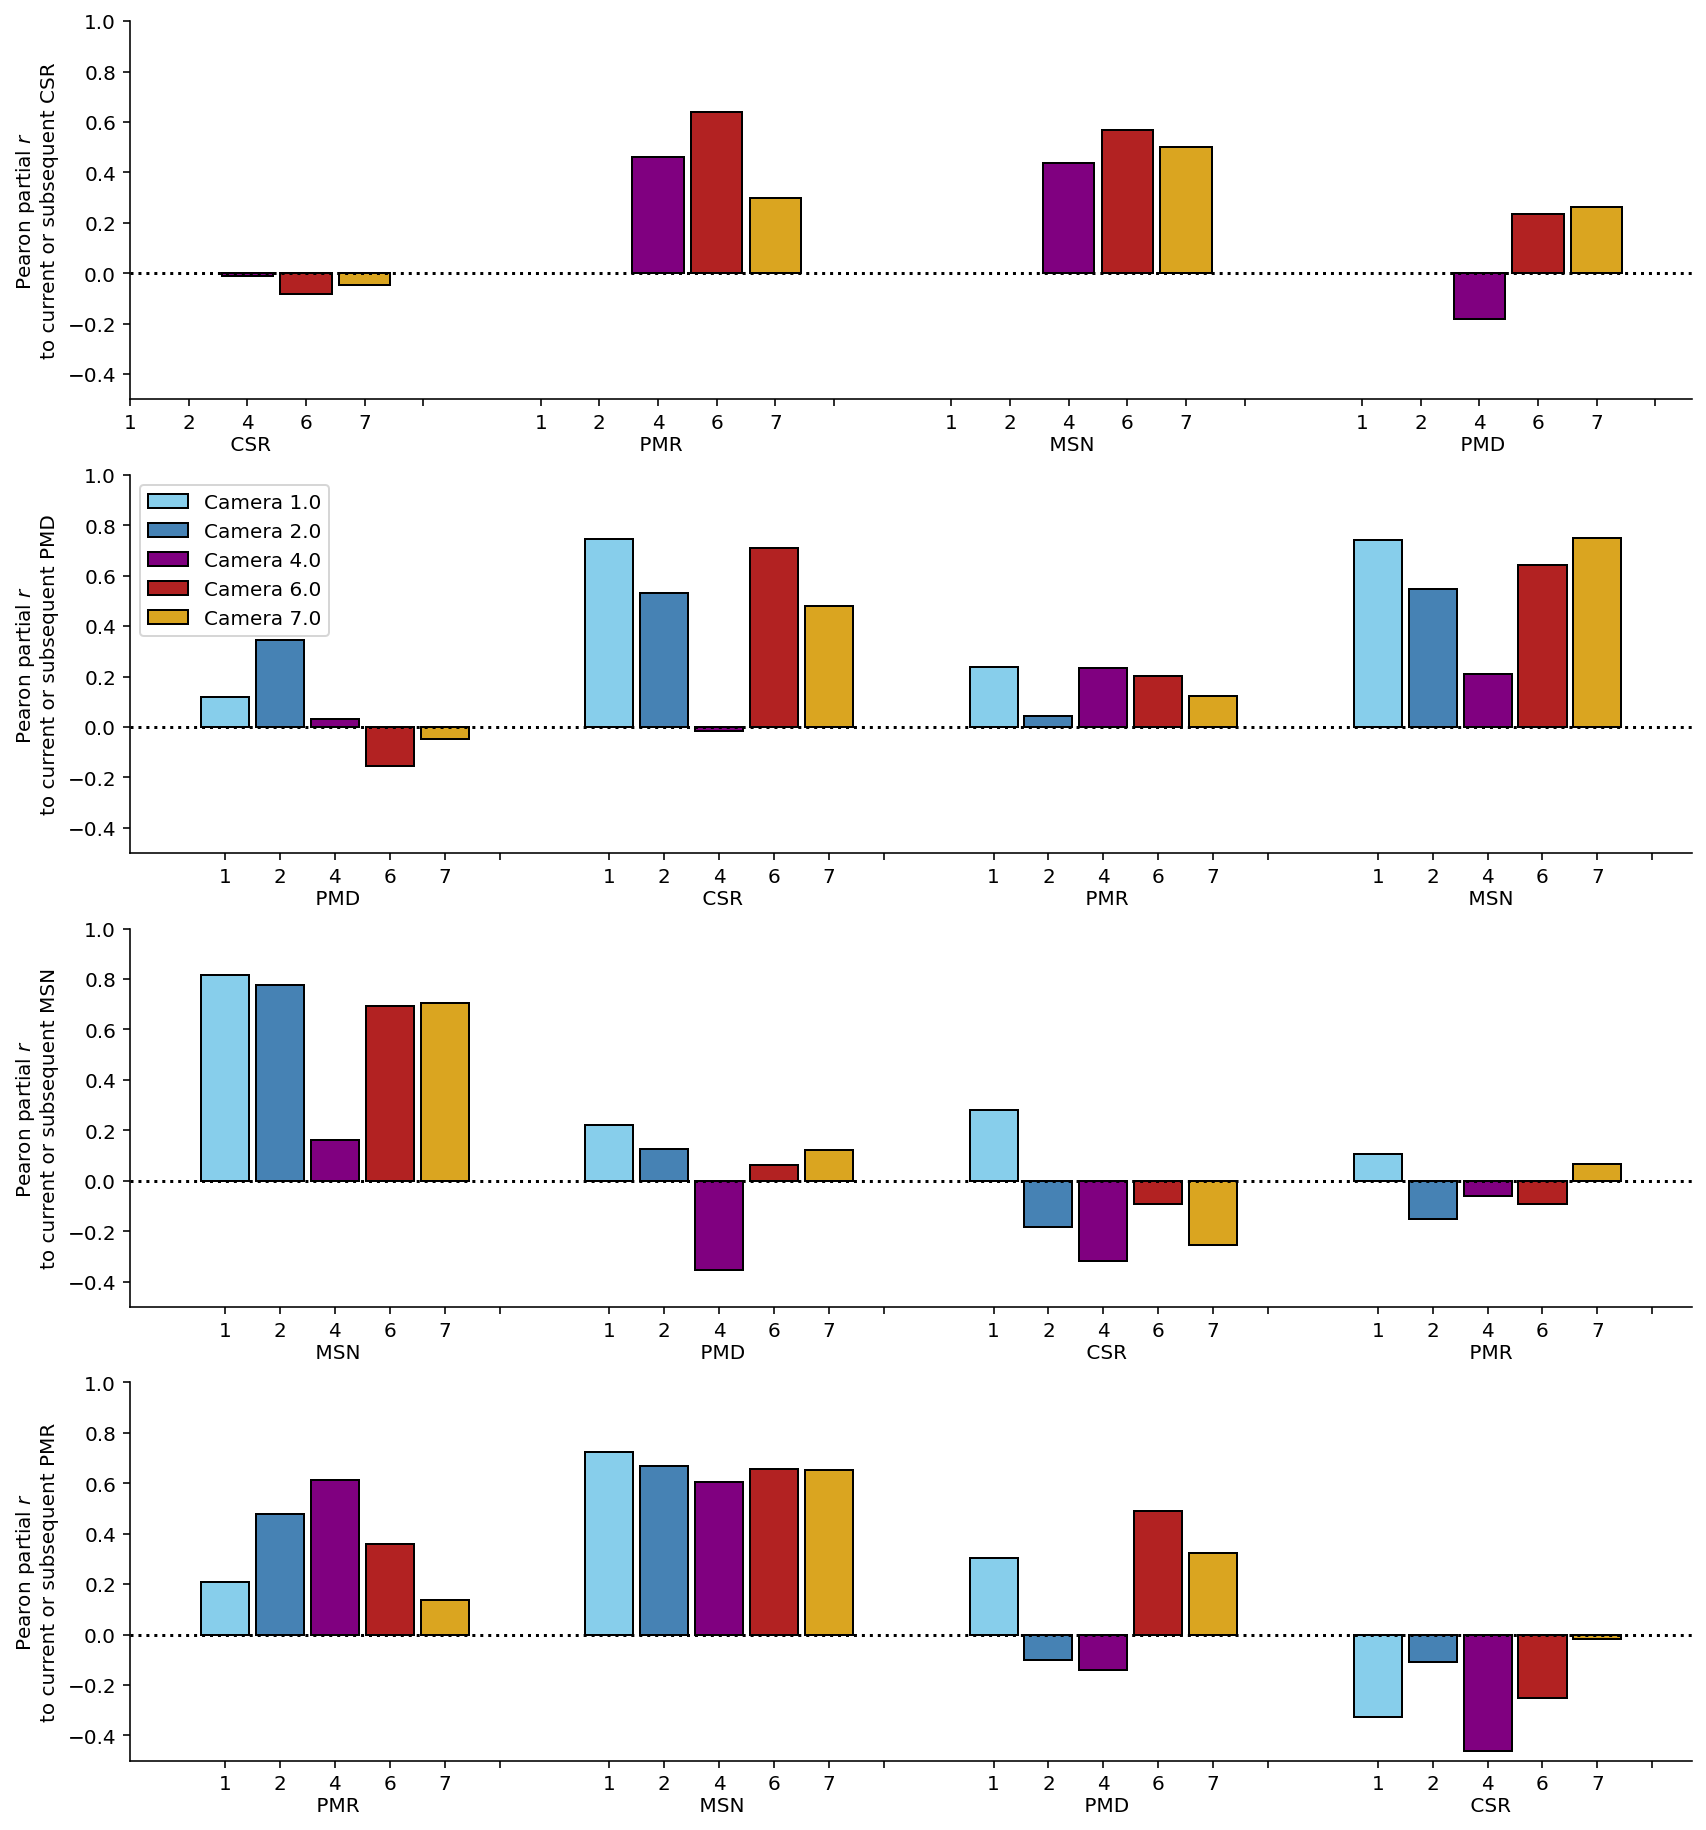

In [671]:
fig, axs = plt.subplots(4,figsize = (14,16),sharey=True)

xtickle = {'MSN':0, 'CSR':2,'MSN+CSR':4,'PMD':3,'PMR':1}

for i,season in enumerate(['CSR','PMD','MSN','PMR',]):
    ax = axs[i]
    
    camcolors = ['skyblue','steelblue','purple','firebrick','goldenrod','olivedrab']
    for p,camera in enumerate(partial.camera.unique()):

        lsub = partial[(partial.camera==camera)&
                     (partial.season==season)]
        if len(lsub)==0:
            continue
        for j in range(4):
            if j==0:
                lab = 'Camera '+str(camera)
            else:
                lab = None
            ax.bar([j+p/7],
                  [lsub.r.values[j]],width = 1/8,edgecolor = 'k',
                  facecolor = camcolors[p],label=lab)
        
    if i==1:
        ax.legend()
    
    ax.spines[['top','right']].set_visible(False)
#     ax.set_title(season)
    ax.axhline(0,c='k',ls=':')
    ax.set_xticks([0+p/7 for p in range(6)]+
                 [1+p/7 for p in range(6)]+
                 [2+p/7 for p in range(6)]+
                 [3+p/7 for p in range(6)])
    camlist = [1,2,4,6,7,'']
    camlist = [str(t) for t in camlist]
    ax.set_ylabel('Pearon partial $r$\nto current or subsequent '+season)
    sslist = ['PMR','CSR','PMD','MSN'][::-1]
    seasonlist_this = sslist.index(season)
    seasonlist_this = sslist[seasonlist_this:]+sslist[:seasonlist_this]
    camlabs = camlist[:2]+[str(camlist[2])+'\n '+seasonlist_this[0]]+camlist[3:]+camlist[:2]+[str(camlist[2])+'\n '+seasonlist_this[1]]
    camlabs = camlabs + camlist[3:]+camlist[:2]+[str(camlist[2])+'\n '+seasonlist_this[2]]
    camlabs = camlabs + camlist[3:]+camlist[:2]+[str(camlist[2])+'\n '+seasonlist_this[3]]+camlist[3:]
    ax.set_xticklabels(camlabs)
    ax.set_ylim(-.5,1)

In [672]:
testvars1 = [#'prcp','prcp_prev1','prcp_prev2','prcp_prev3','prcp_prev4',]
#            'et',
    'gw_first','et_prev1','et']#'gw_min_prev1']
partials = []
cameranum = []
testvar = []
season = []
for Camera in stcam.Camera.unique():
    if (Camera not in [3,5,8]):
        for ssn in stcam.season.unique():
            if ssn=='MSN':
                testvars = testvars1 + ['prcp']
            elif ssn=='PMD':
                testvars = testvars1 + ['prcp_prev1','prcp_prev3']
            elif ssn=='PMR':
                testvars = testvars1 + ['prcp','prcp_prev1']
            else:
                testvars = testvars1 + ['prcp_prev1','prcp_prev2']
            noET = False
            for i in range(len(testvars)):

                ssub = stcam[(stcam.Camera==Camera)&(stcam.season==ssn)]
                if i==0:
                    test = testvars[1:]
                elif i==len(testvars)-1:
                    test = testvars[:-1]
                else:
                    test = testvars[:i]+testvars[i+1:]
                if noET:
                    test = [t for t in test if t!='et']

                pgout = pg.partial_corr(data=ssub, x="fp_final", 
                                        y=testvars[i], covar=test,
                   method='spearman').round(3)
                if (testvars[i]=='et') & (pgout.r.values[0]>0):
                    noet = True
                    continue
                cameranum.append(Camera)
                testvar.append(testvars[i])
                season.append(ssn)
                partials.append(pgout.r.values[0])
partialET = pd.DataFrame.from_dict({'camera':cameranum,
                                 'season':season,
                                 'variable':testvar,
                                 'r':partials}).dropna()


In [673]:
partialET

,camera,season,variable,r
5,1.0,PMD,gw_first,0.123
6,1.0,PMD,et_prev1,-0.368
7,1.0,PMD,et,-0.533
8,1.0,PMD,prcp_prev1,0.554
9,1.0,PMD,prcp_prev3,0.373
...,...,...,...,...
81,7.0,PMR,gw_first,-0.071
82,7.0,PMR,et_prev1,-0.232
83,7.0,PMR,et,-0.395
84,7.0,PMR,prcp,-0.036


In [674]:
partialsub

,camera,season,variable,r


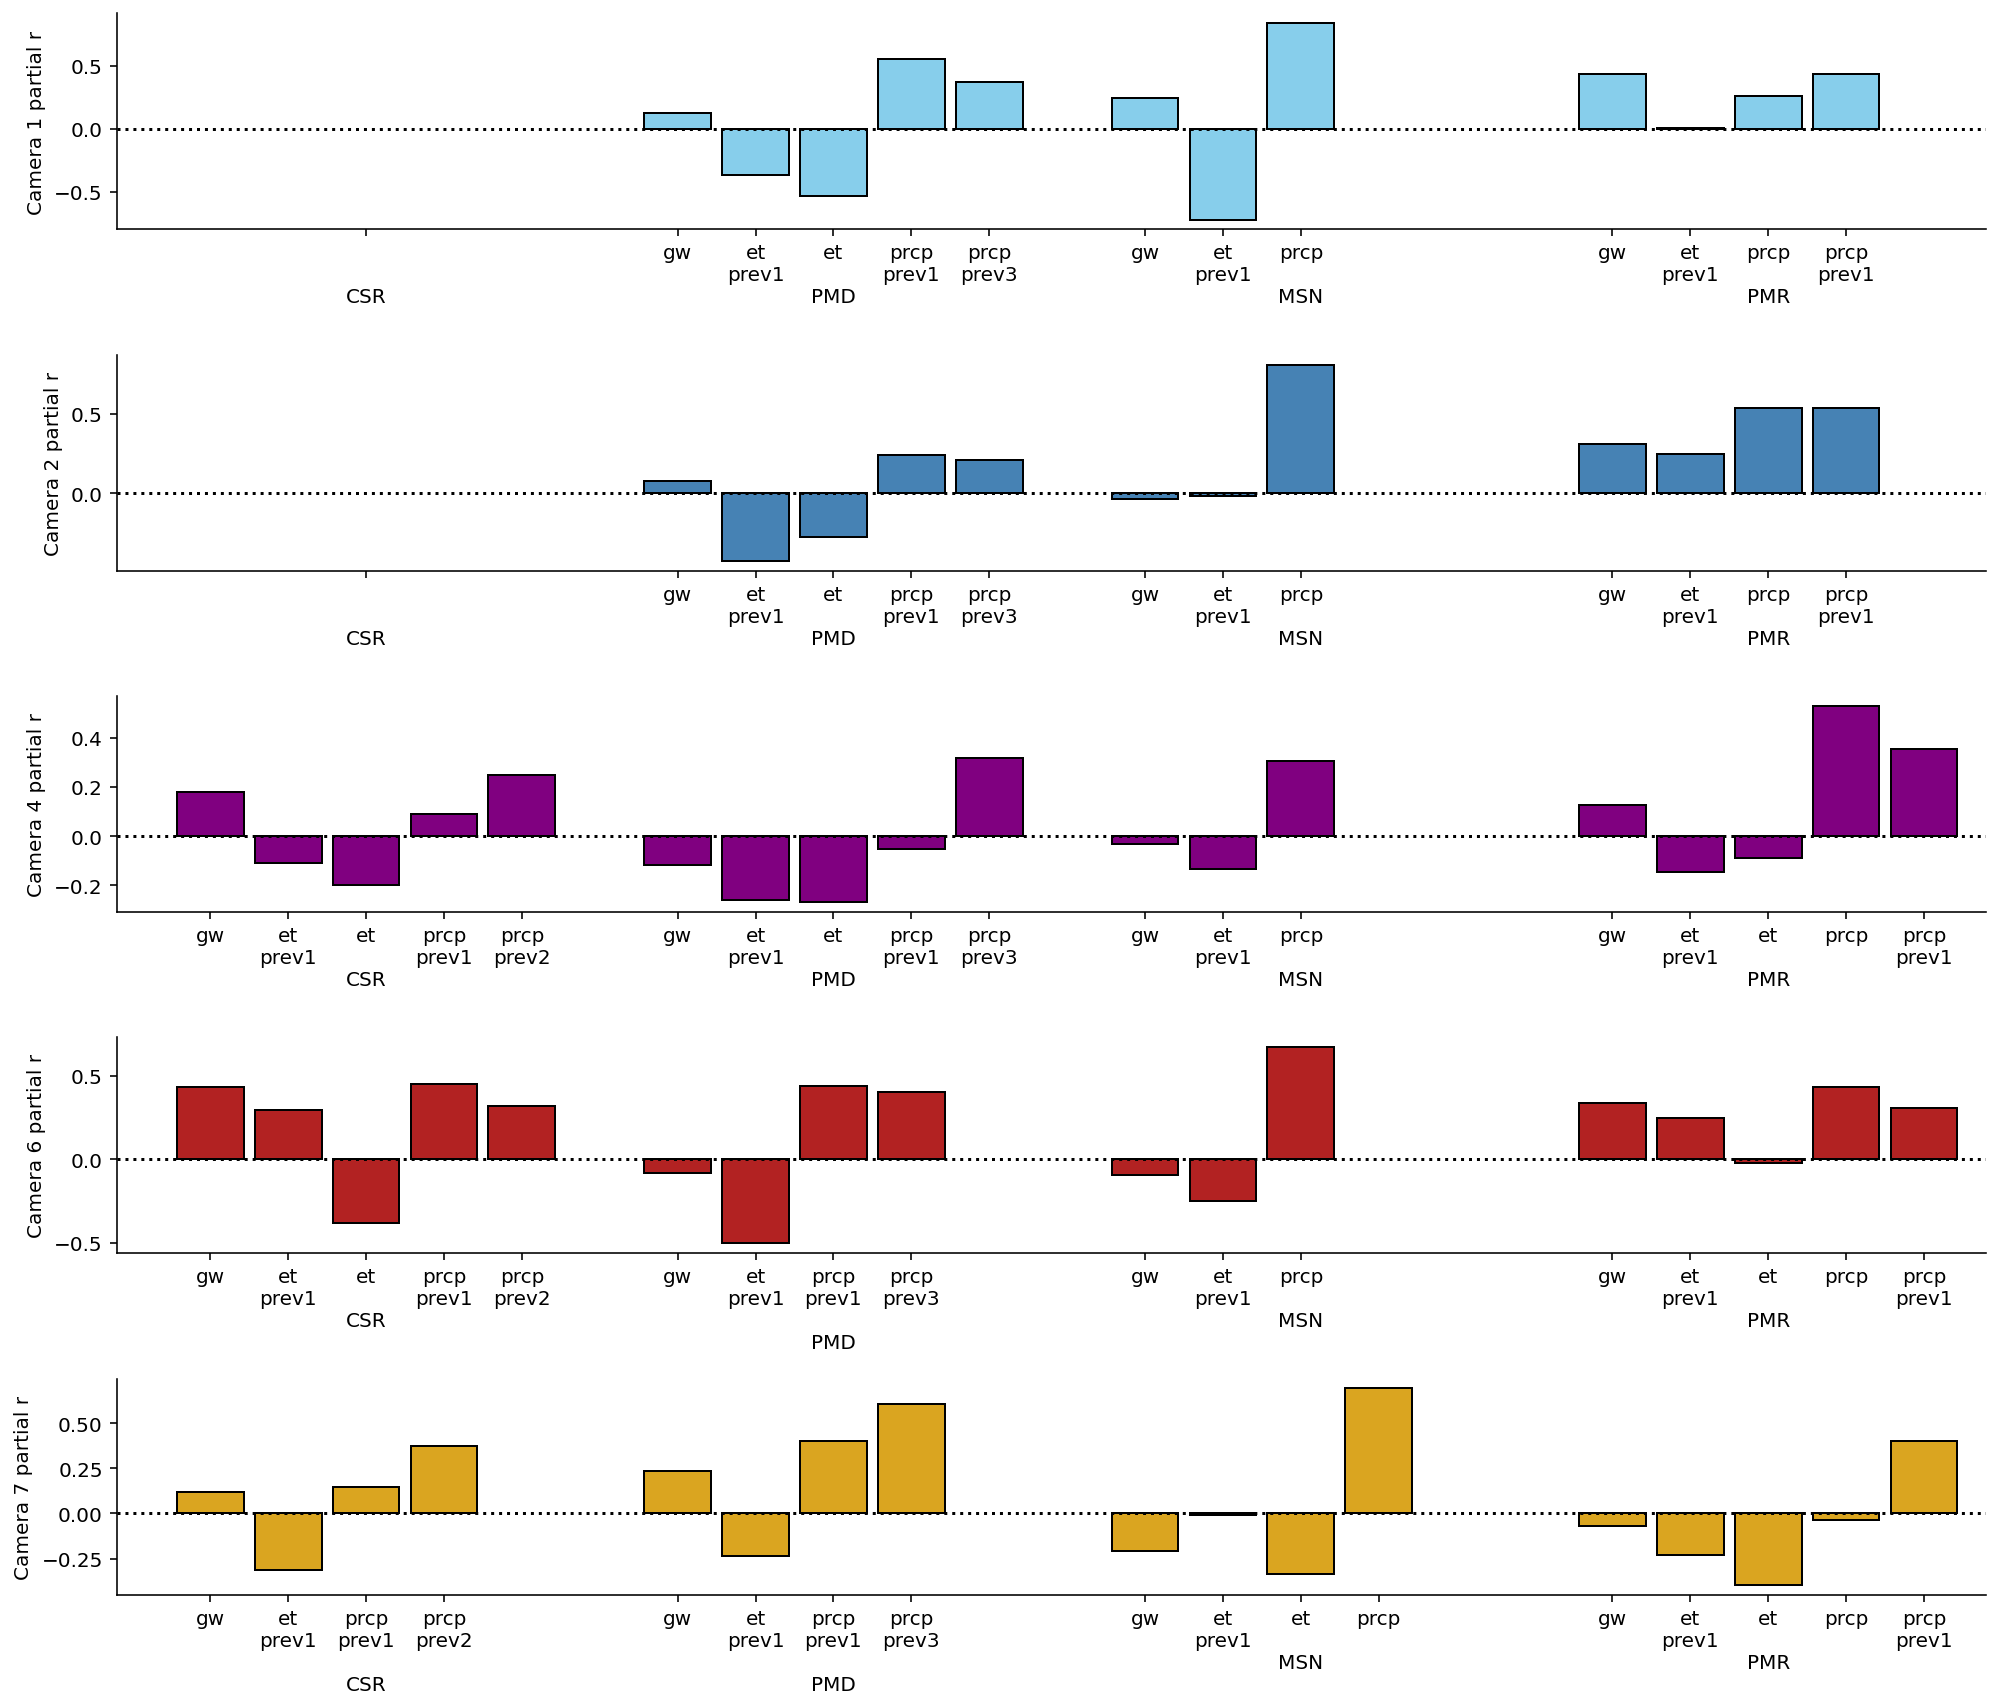

In [675]:
fig,axs = plt.subplots(5,figsize = (14,12),)
for i,Camera in enumerate([1,2,4,6,7]):
    ax = axs[i]
    
    xlabels = []
    xticks = []
    if (Camera not in [3,5,8]):
        for j,ssn in enumerate(['CSR','PMD','MSN','PMR']):
            partialsub = partialET[(partialET.camera==Camera)&
                                  (partialET.season==ssn)]
            if len(partialsub)==0:
                xlabels.append('\n\nCSR')
                xticks.append(1/3)
            else:
                for k in range(len(partialsub)):
                    ax.bar([j+k/6],partialsub.r.values[k],width = 1/7,
                          edgecolor = 'k',facecolor = camcolors[i])
                    if k==2:
                        lab = partialsub.variable.values[k]+'\n\n'+ssn

                    else:
                        lab = partialsub.variable.values[k]
                    lab = lab.replace('_first','').replace('_','\n')
                    xlabels.append(lab)
                    xticks.append(j+k/6)
    ax.set_xticks(xticks)
    ax.set_xticklabels(xlabels)
    ax.axhline(0,c='k',ls=':')
    ax.spines[['top','right']].set_visible(False)
    ax.set_xlim(-.2,3.8)
    ax.set_ylabel('Camera '+str(Camera)+' partial r')
fig.tight_layout()

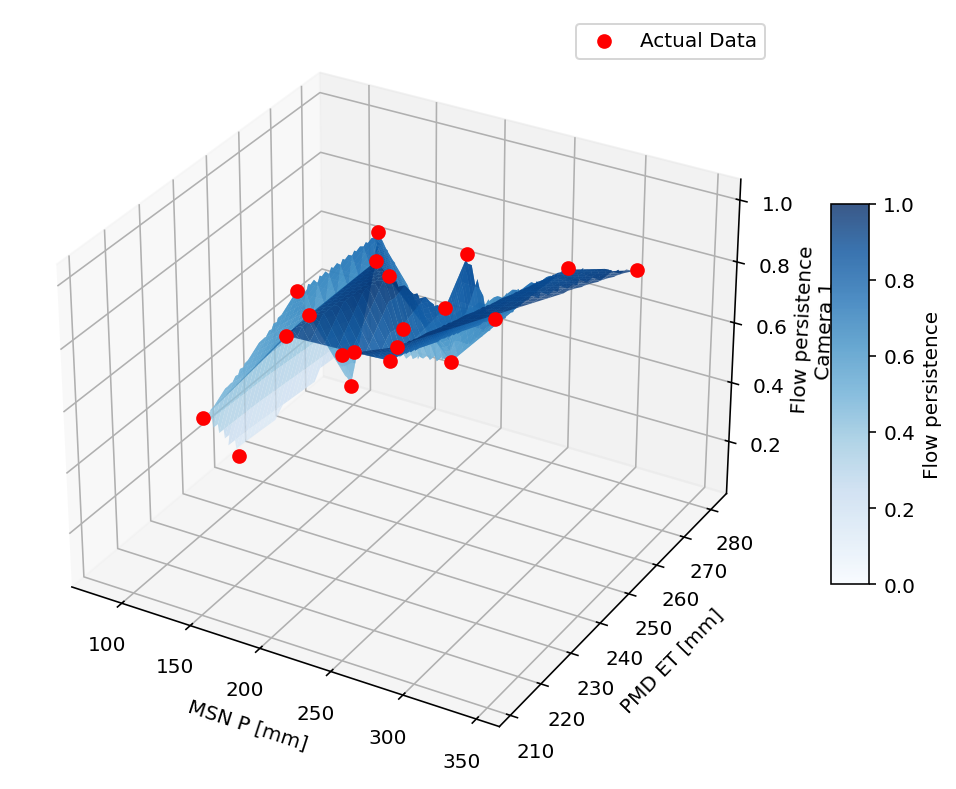

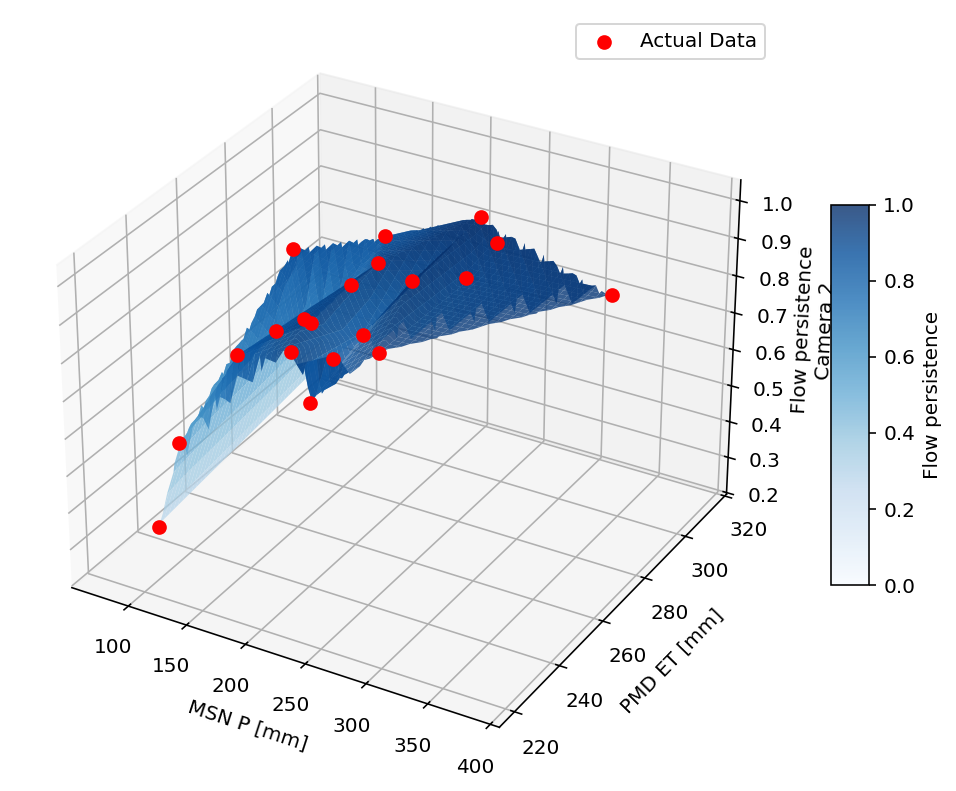

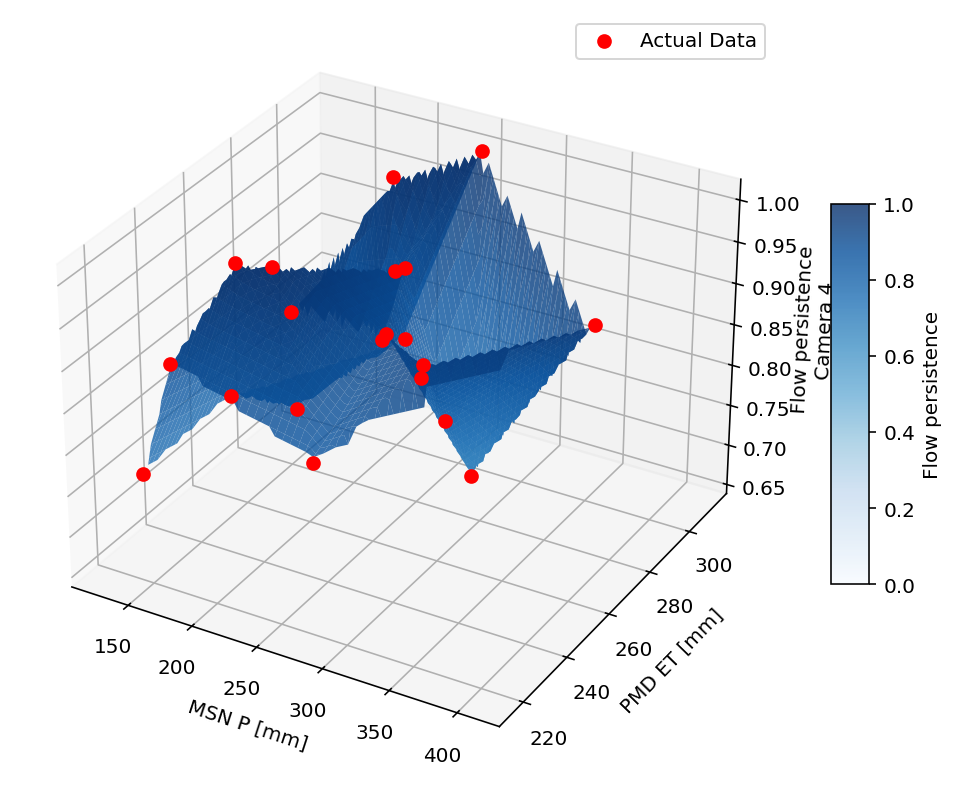

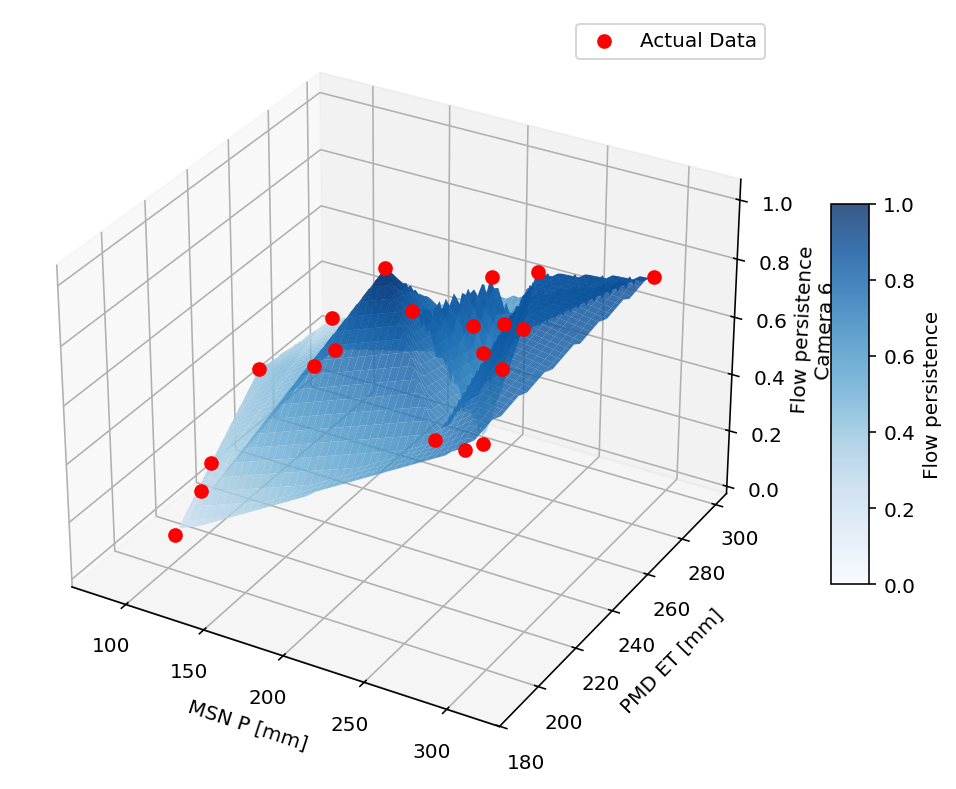

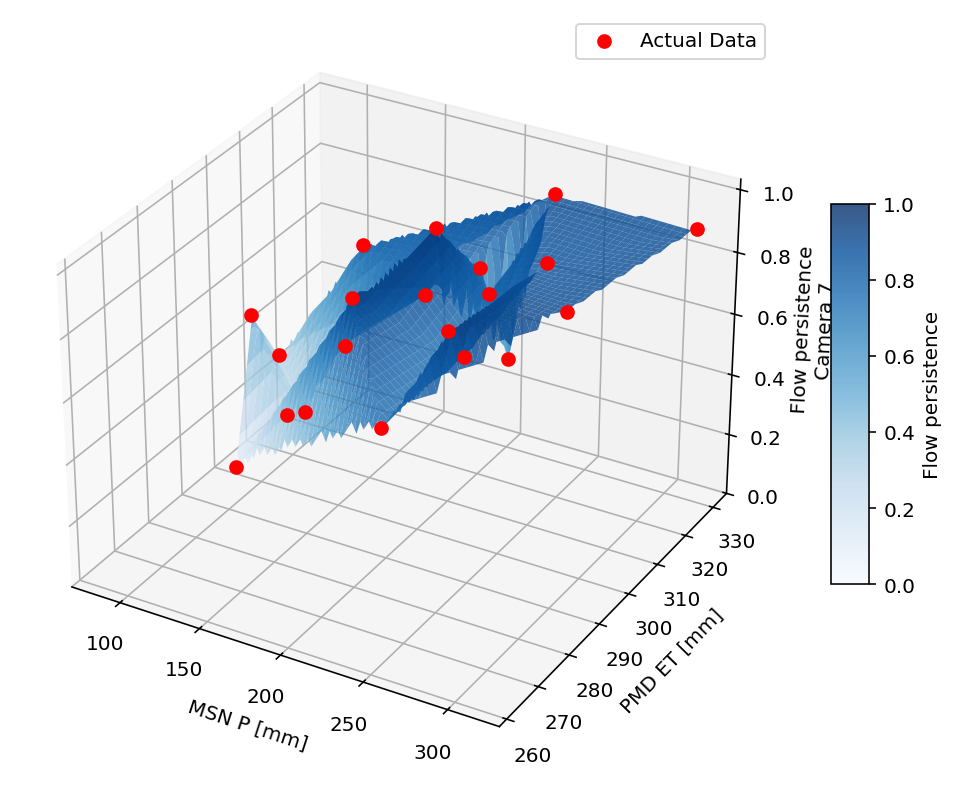

In [527]:
from mpl_toolkits.mplot3d import Axes3D
from scipy.interpolate import griddata

for camera in [1,2,4,6,7]:
    st1 = stcam[(stcam.Camera==camera)&(stcam.season=='MSN')]



    # 1. Replace these arrays with your actual 1D data columns
    x_raw = st1.prcp
    y_raw = st1.et_prev1
    z_raw = st1.fp_final

    # 2. Create a regular grid covering the range of your data
    grid_x, grid_y = np.mgrid[
        x_raw.min() : x_raw.max() : 100j, y_raw.min() : y_raw.max() : 100j
    ]

    # 3. Interpolate Z values onto the grid
    # Options for method: 'linear', 'cubic', or 'nearest'
    grid_z = griddata((x_raw, y_raw), z_raw, (grid_x, grid_y), method='linear')

    # 4. Plot the interpolated surface and raw data points
    fig = plt.figure(figsize=(10, 7))
    ax = fig.add_subplot(projection='3d')

    # Plot smooth surface
    surf = ax.plot_surface(
        grid_x, grid_y, grid_z, cmap='Blues', alpha=0.8, edgecolor='none',
        vmin = 0, vmax = 1
    )

    # Overlay actual measurements as red dots
    ax.scatter(
        x_raw, y_raw, z_raw, color='red', s=40, label='Actual Data', depthshade=False
    )

    ax.set_xlabel('MSN P [mm]')
    ax.set_ylabel('PMD ET [mm]')
    ax.set_zlabel('Flow persistence\nCamera '+str(int(camera)))
    fig.colorbar(surf, shrink=0.5, aspect=10, label='Flow persistence')
    ax.legend()

    plt.show()



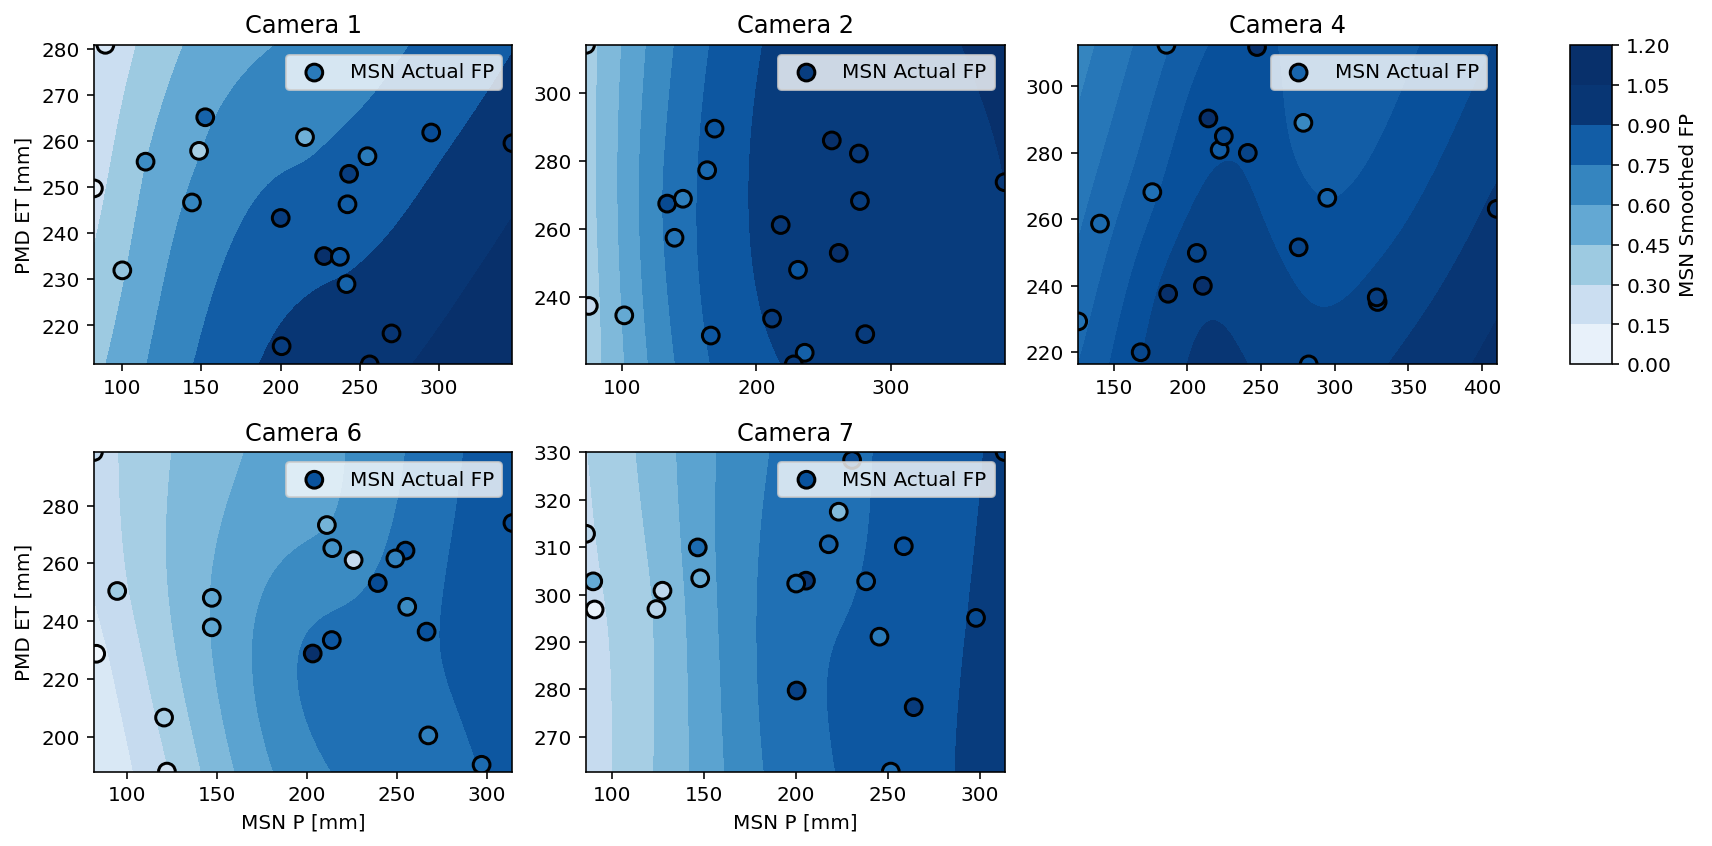

In [696]:
from scipy.interpolate import RBFInterpolator

fig,axs = plt.subplots(2,4,figsize = (12,6),gridspec_kw = {'width_ratios':[1,1,1,.1]})
for j,camera in enumerate([1,2,4,6,7]):
    st1 = stcam[(stcam.Camera==camera)&(stcam.season=='MSN')]



    # 1. Replace these arrays with your actual 1D data columns
    x_raw = st1.prcp
    y_raw = st1.et_prev1
    z_raw = st1.fp_final

    # Stack X and Y into a 2D coordinate array of shape (N, 2)
    xy_raw = np.column_stack([x_raw, y_raw])

    # 2. Fit the RBF Interpolator with smoothing
    rbf = RBFInterpolator(xy_raw, z_raw, smoothing=10000.0, kernel='thin_plate_spline')

    # 3. Create a regular grid to evaluate the smooth surface
    grid_x, grid_y = np.mgrid[
        x_raw.min() : x_raw.max() : 200j, y_raw.min() : y_raw.max() : 200j
    ]
    grid_points = np.column_stack([grid_x.ravel(), grid_y.ravel()])

    # Predict Z values across the grid and reshape back to 2D
    grid_z = rbf(grid_points).reshape(grid_x.shape)

    # 4. Plot the smooth 2D heatmap
    if j<3:
        ax = axs.flatten()[j]
    else:
        ax = axs.flatten()[j+1]
    heatmap = ax.contourf(grid_x, grid_y, grid_z, cmap='Blues', shading='auto',vmin = 0, vmax = 1)

    
    # Overlay raw data points (dots may differ slightly in color from the smoothed background)
    ax.scatter(
        x_raw,
        y_raw,
        c=z_raw,
        cmap='Blues',
        edgecolors='k',
        s=70,
        linewidth=1.5,
        label='MSN Actual FP',
        vmin=0,vmax=1
    )
    
    if j==0:
        plt.colorbar(heatmap, label='MSN Smoothed FP',cax = axs.flatten()[3])
    if j>2:
        ax.set_xlabel('MSN P [mm]')
    if j in [0,3]:
        ax.set_ylabel('PMD ET [mm]')
    ax.set_title('Camera '+str(int(camera)))
    ax.legend()

for ax in [axs[1,3],axs[1,2]]:
    ax.axis('off')
fig.tight_layout()


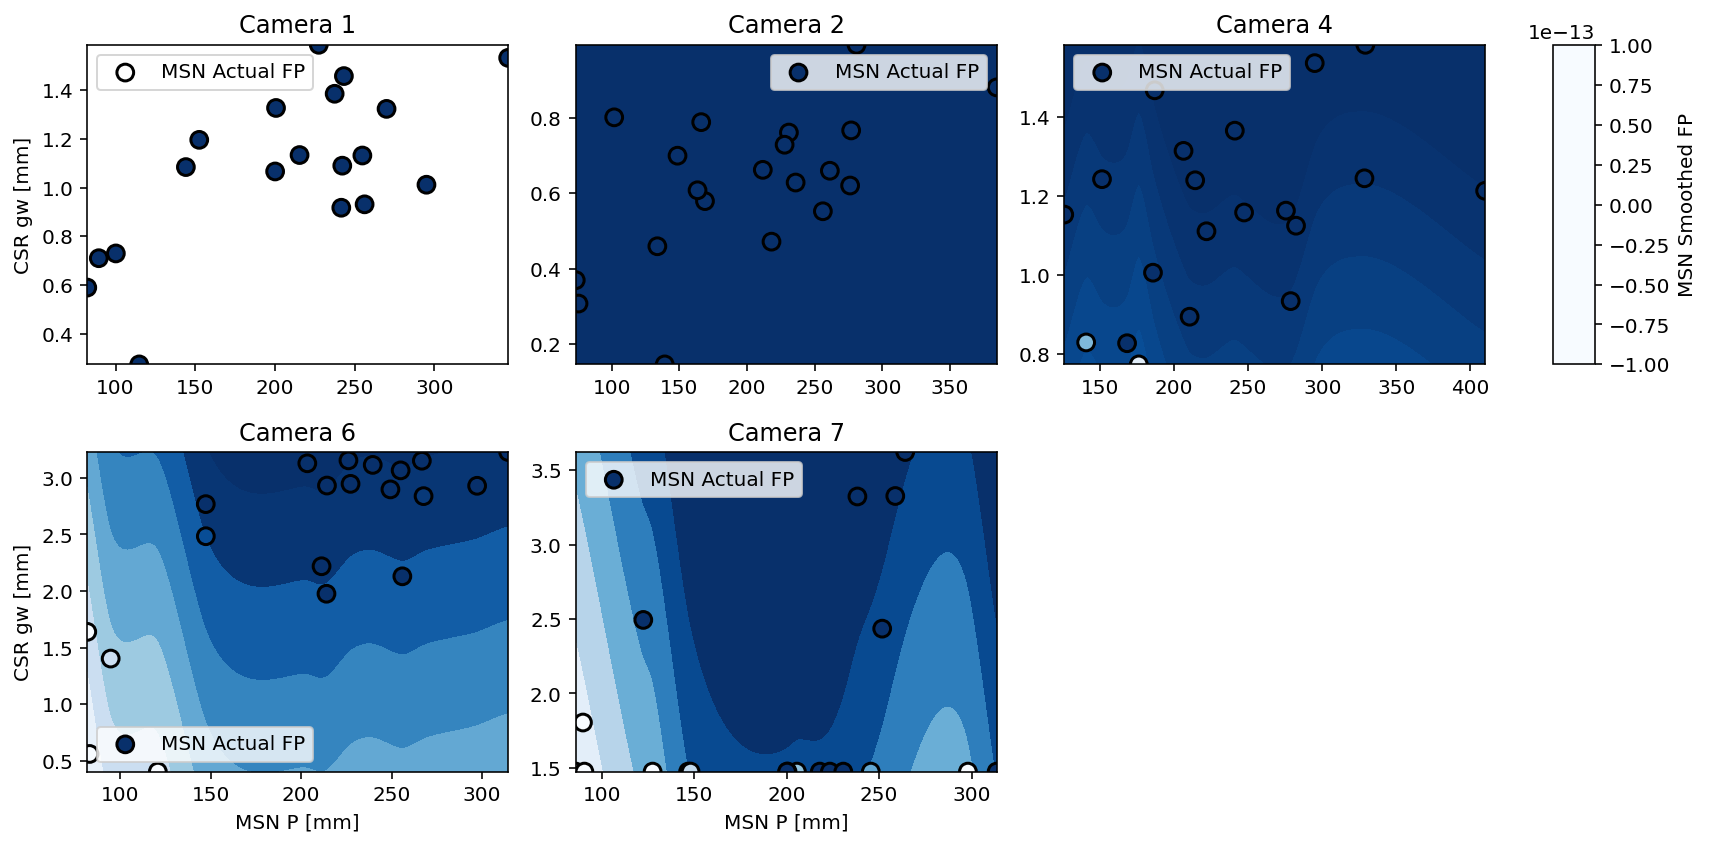

In [704]:
from scipy.interpolate import RBFInterpolator

fig,axs = plt.subplots(2,4,figsize = (12,6),gridspec_kw = {'width_ratios':[1,1,1,.1]})
for j,camera in enumerate([1,2,4,6,7]):
    st1 = stcam[(stcam.Camera==camera)&(stcam.season=='CSR')]



    # 1. Replace these arrays with your actual 1D data columns
    x_raw = st1.prcp_prev2
    y_raw = st1.gw
    z_raw = st1.fp_final

    # Stack X and Y into a 2D coordinate array of shape (N, 2)
    xy_raw = np.column_stack([x_raw, y_raw])

    # 2. Fit the RBF Interpolator with smoothing
    rbf = RBFInterpolator(xy_raw, z_raw, smoothing=1000.0, kernel='thin_plate_spline')

    # 3. Create a regular grid to evaluate the smooth surface
    grid_x, grid_y = np.mgrid[
        x_raw.min() : x_raw.max() : 200j, y_raw.min() : y_raw.max() : 200j
    ]
    grid_points = np.column_stack([grid_x.ravel(), grid_y.ravel()])

    # Predict Z values across the grid and reshape back to 2D
    grid_z = rbf(grid_points).reshape(grid_x.shape)

    # 4. Plot the smooth 2D heatmap
    if j<3:
        ax = axs.flatten()[j]
    else:
        ax = axs.flatten()[j+1]
    heatmap = ax.contourf(grid_x, grid_y, grid_z,cmap='Blues', shading='auto',vmin = 0, vmax = 1)

    
    # Overlay raw data points (dots may differ slightly in color from the smoothed background)
    ax.scatter(
        x_raw,
        y_raw,
        c=z_raw,
        cmap='Blues',
        edgecolors='k',
        s=70,
        linewidth=1.5,
        label='MSN Actual FP',
        vmin=0.7,vmax=1
    )
    
    if j==0:
        plt.colorbar(heatmap, label='MSN Smoothed FP',cax = axs.flatten()[3])
    if j>2:
        ax.set_xlabel('MSN P [mm]')
    if j in [0,3]:
        ax.set_ylabel('CSR gw [mm]')
    ax.set_title('Camera '+str(int(camera)))
    ax.legend()

for ax in [axs[1,3],axs[1,2]]:
    ax.axis('off')
fig.tight_layout()


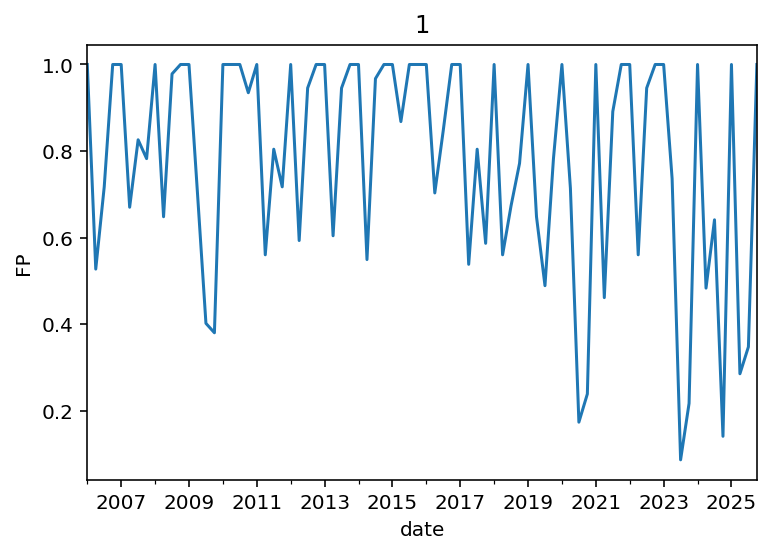

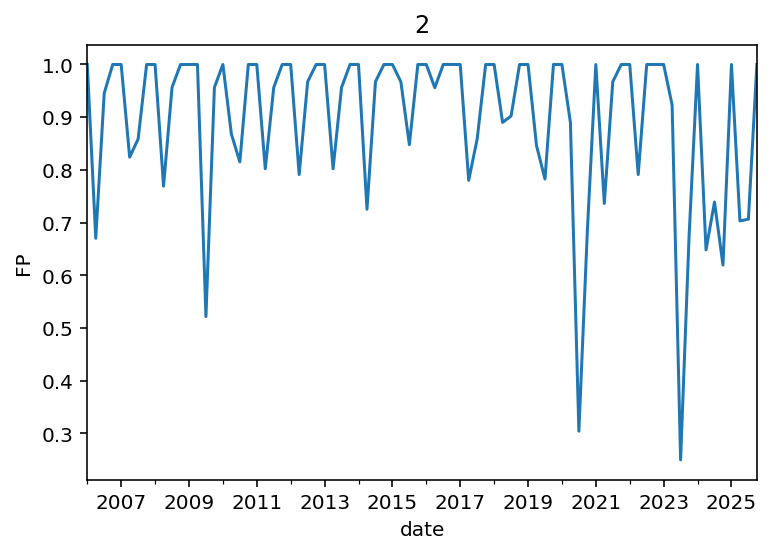

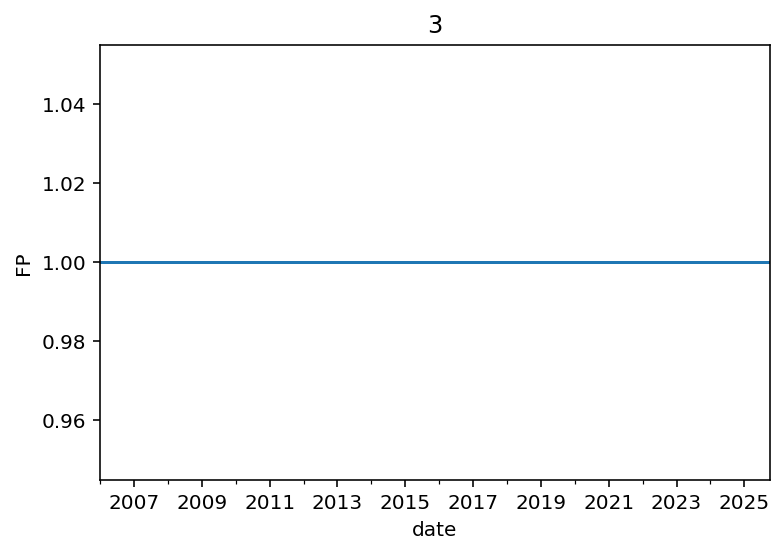

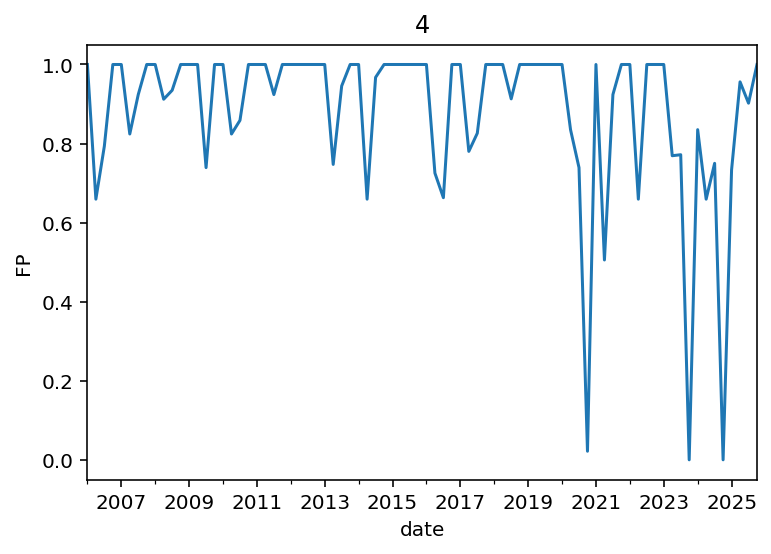

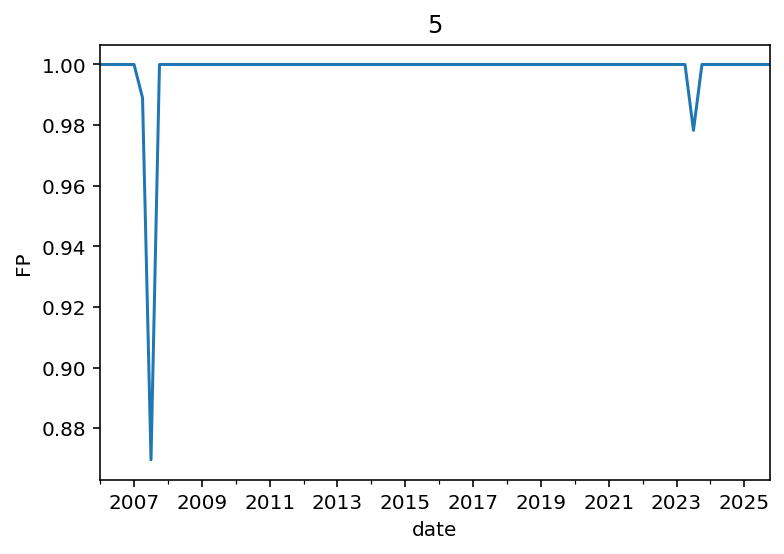

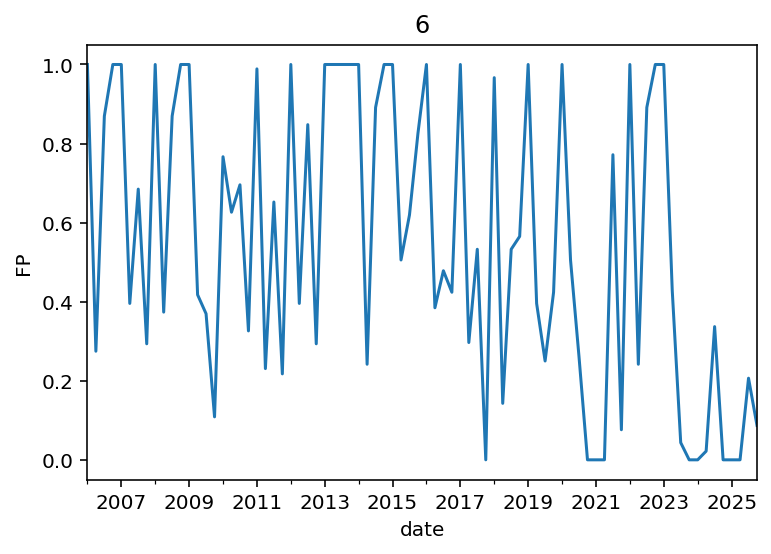

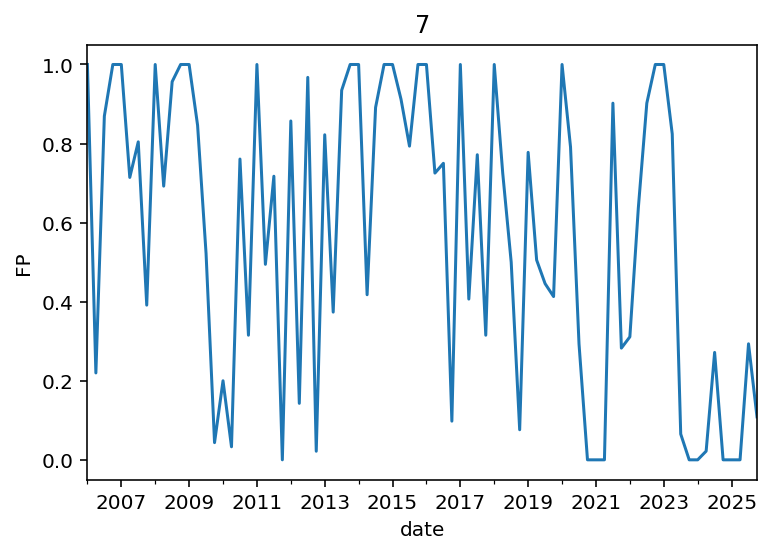

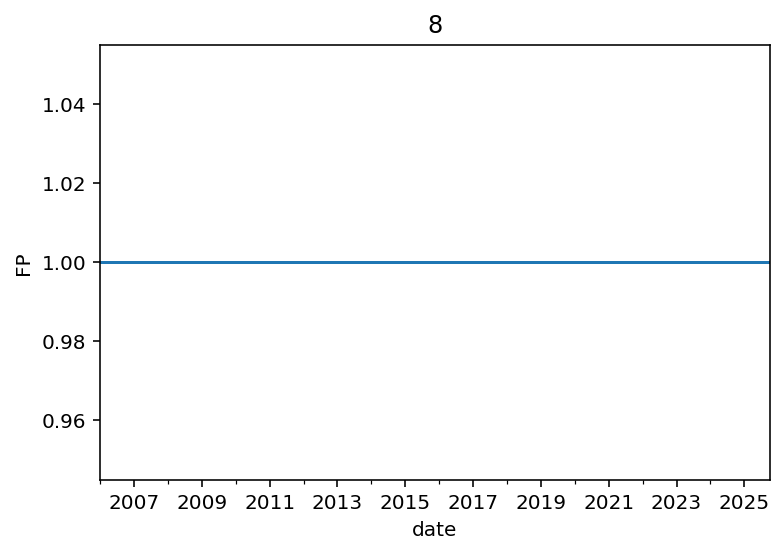

In [517]:
for camera in cameradata.Camera.unique():
    cameradata[cameradata.Camera.isin([camera,])].set_index('date').fp_final.resample('3MS').mean().plot()
    plt.title(camera)
    plt.ylabel('FP')
    plt.show()

In [604]:
pts1 = pd.read_csv('../../Jupyter/TNC_cameras_original/Data/Dana_CAsites.csv')

(np.float64(-127.74018625000001),
 np.float64(-62.24358475),
 np.float64(16.3082261),
 np.float64(50.9594119))

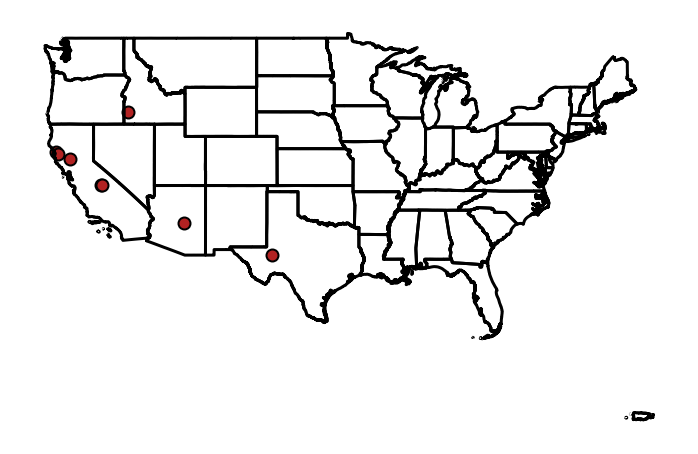

In [617]:
import geopandas as gpd
fig,ax = plt.subplots(1)
state_outline = gpd.read_file('../../Jupyter/metric_extension/Data/maps_and_boundaries/US_state_outline/cb_2018_us_state_500k.shp')
state_outline[~(state_outline.isin(['AK','HI','MP',
                                   'GU','NaN','VI','DC',
                                   'AS',]))].dropna().boundary.plot(edgecolor = 'k',ax=ax)
pts = list(pts1.Long)+[ -102.548261,-116.646582, -111.187261]
ptsy = list(pts1.Lat)+[31.362039,43.005339, 33.947756]
ax.scatter(pts,ptsy,edgecolor = 'k',c='firebrick')
ax.axis('off')

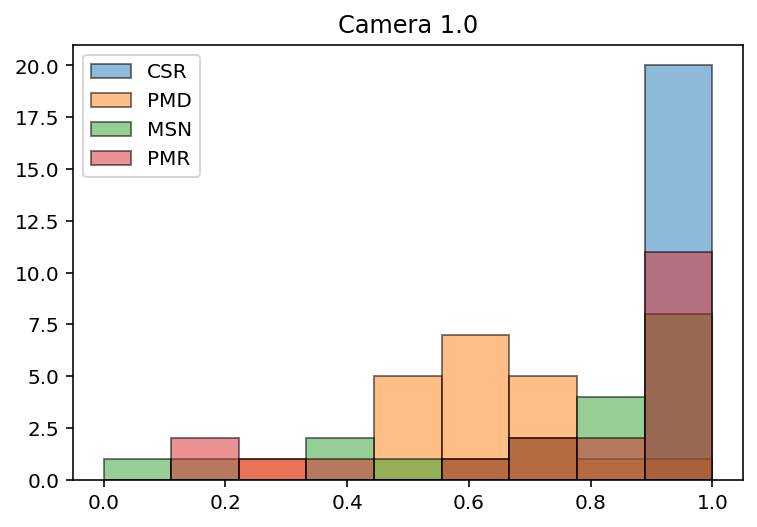

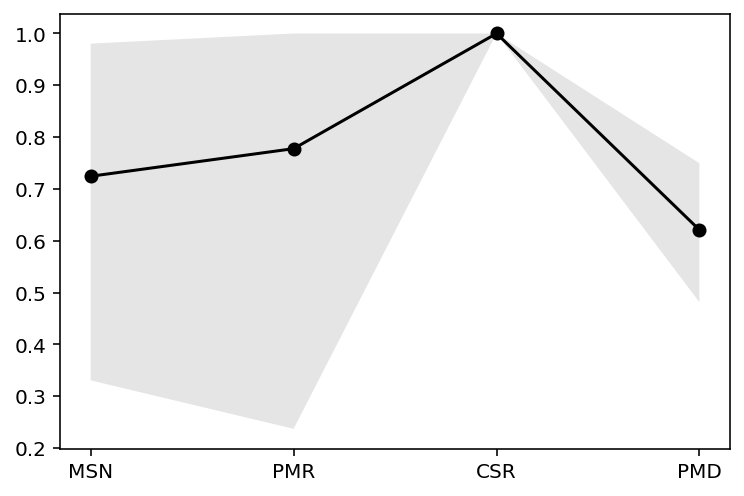

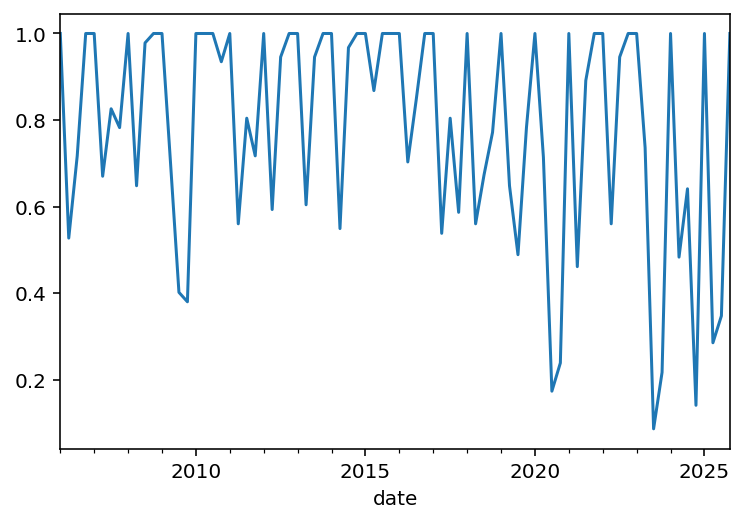

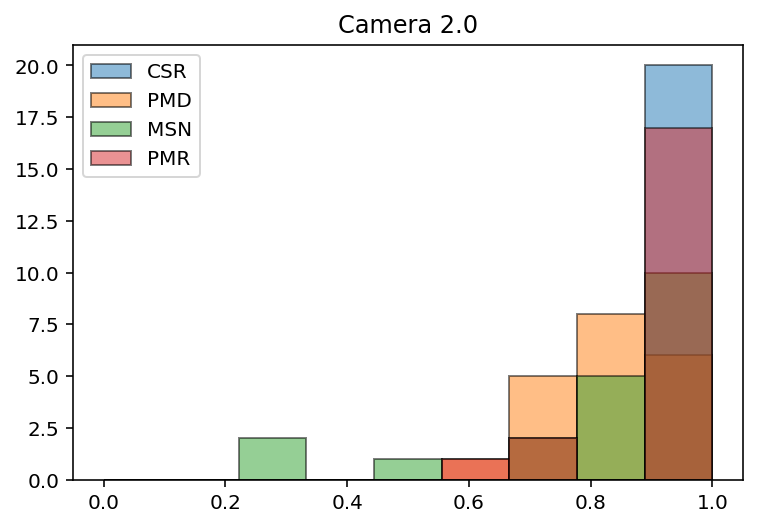

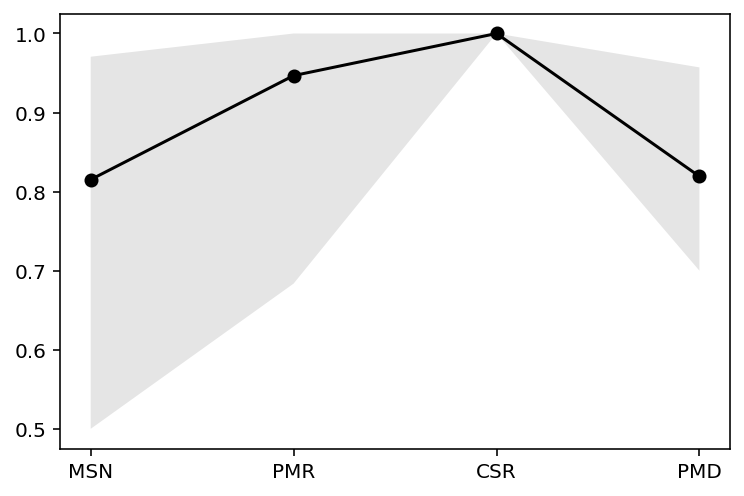

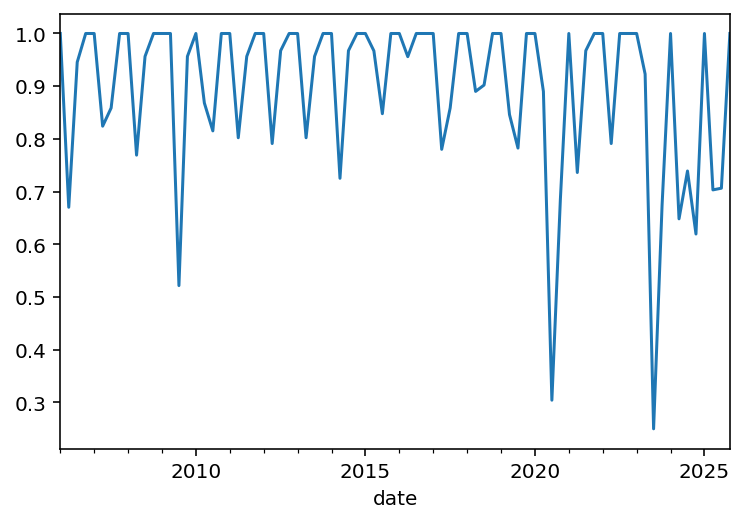

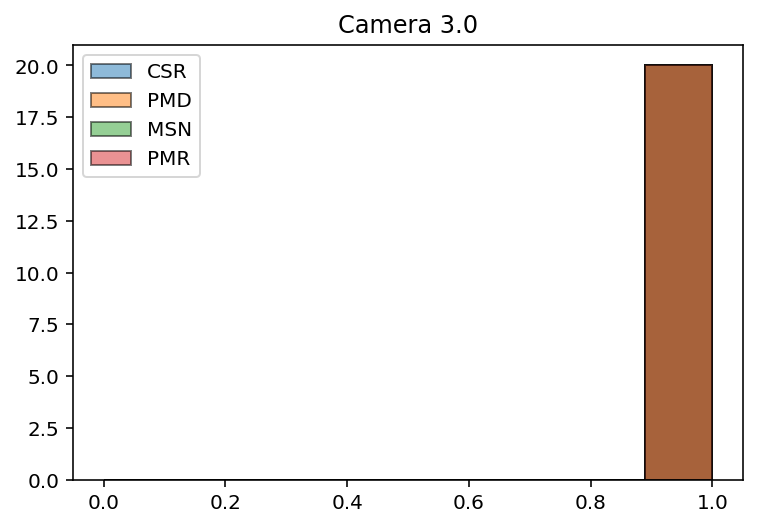

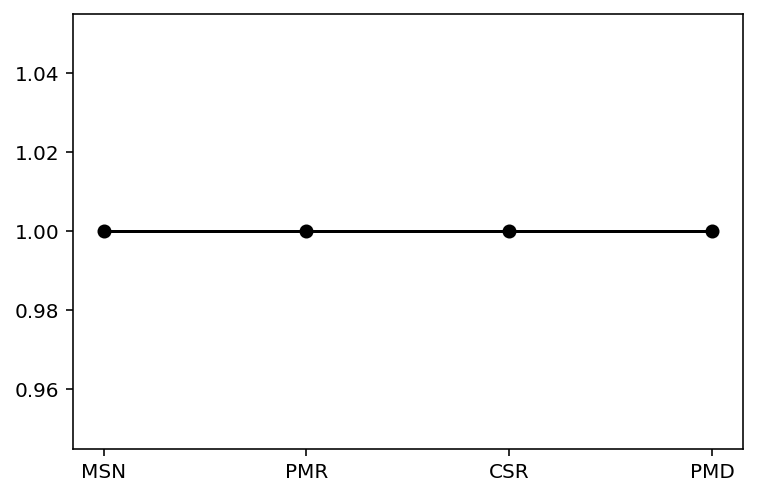

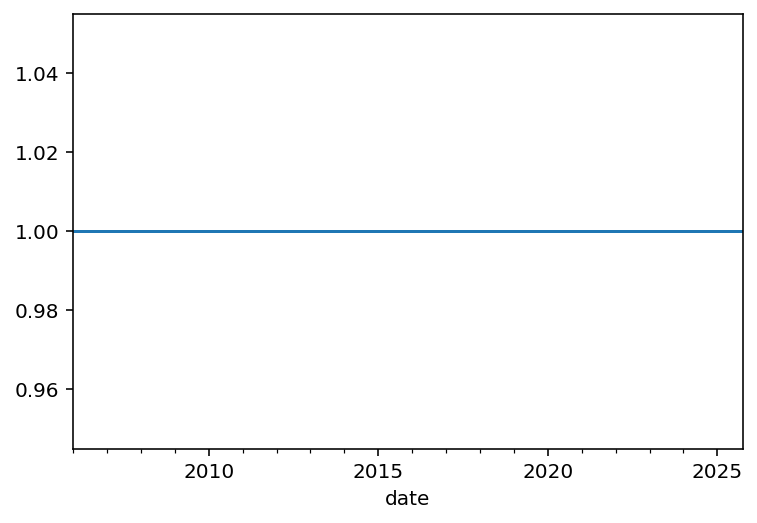

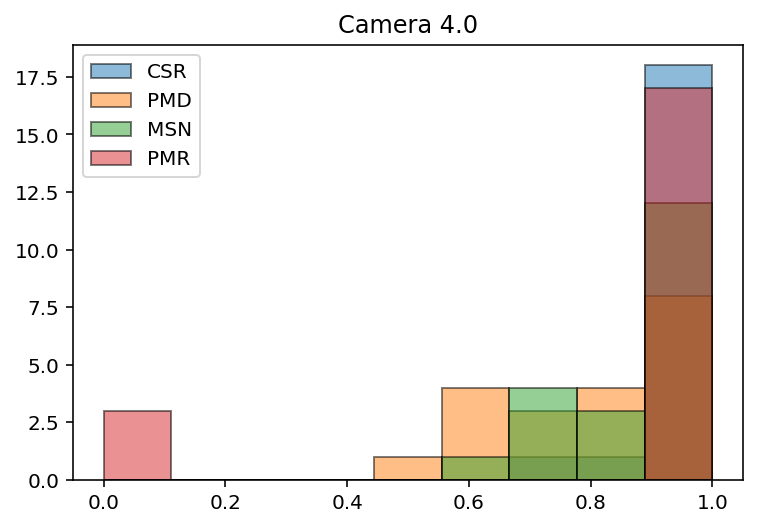

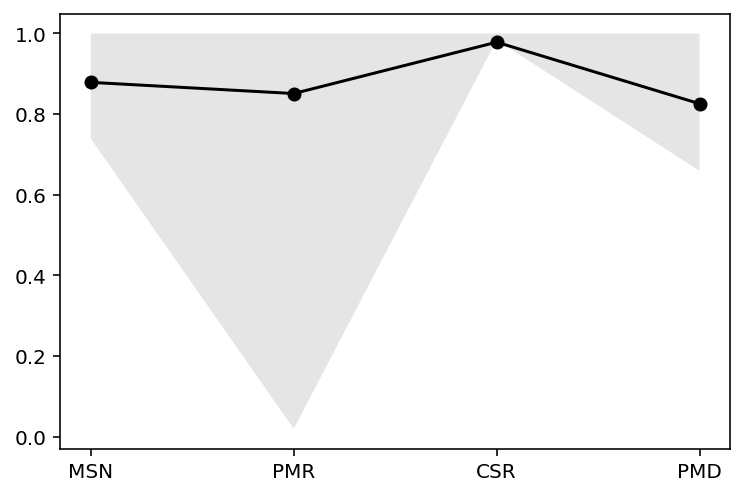

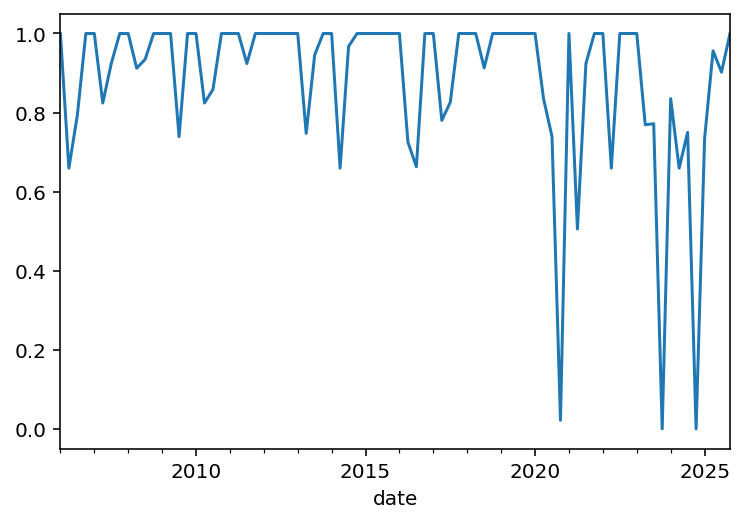

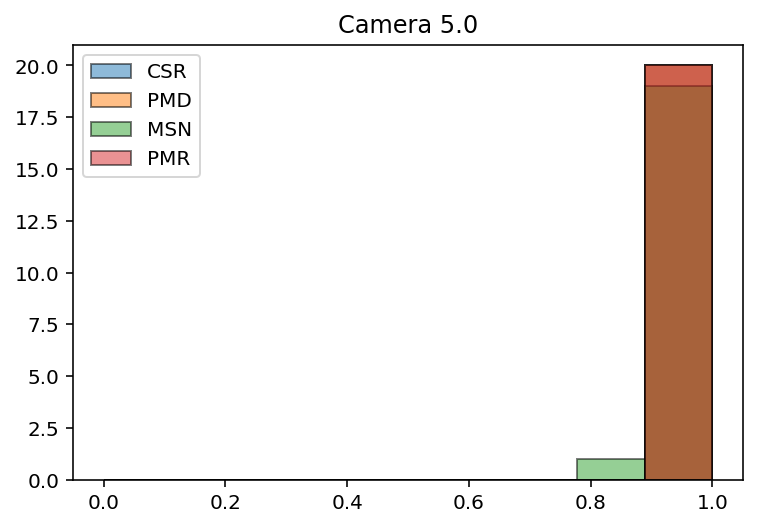

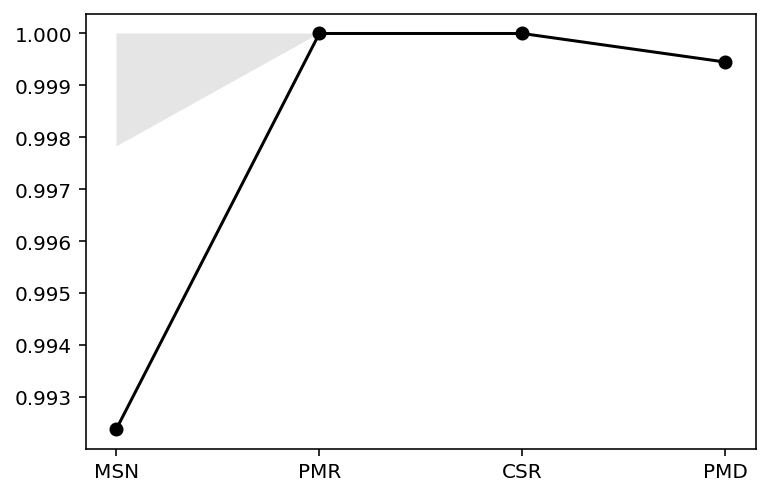

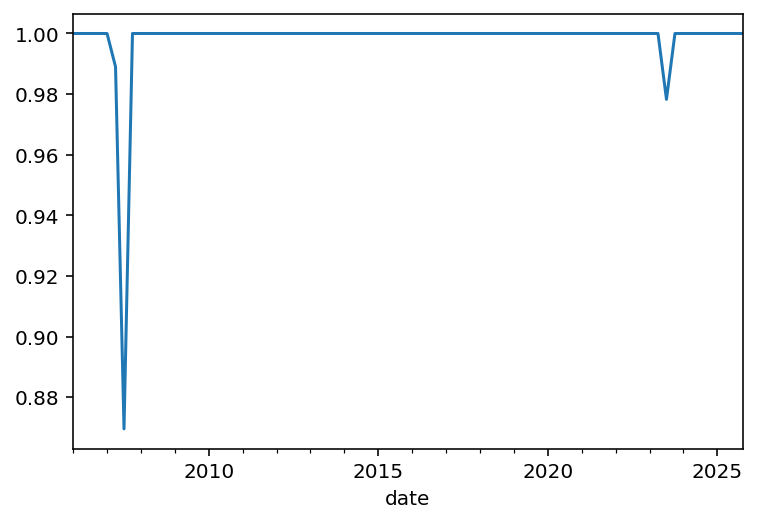

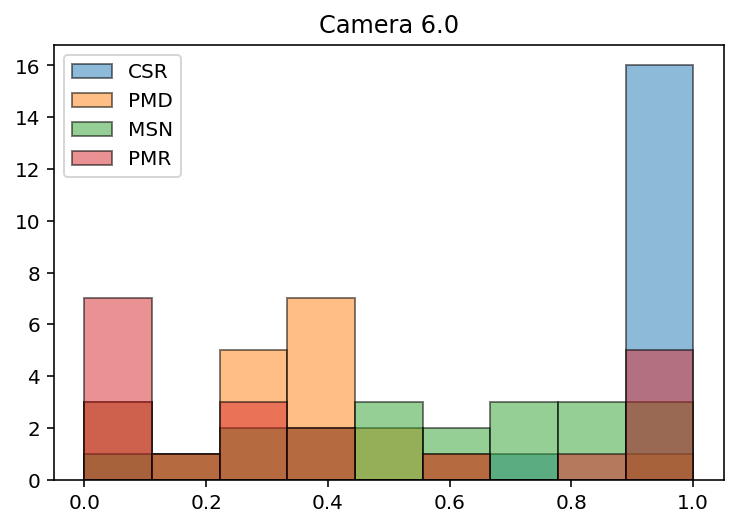

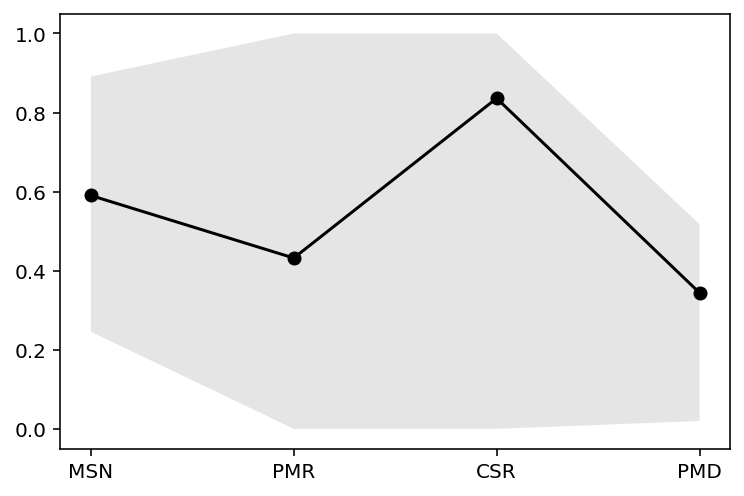

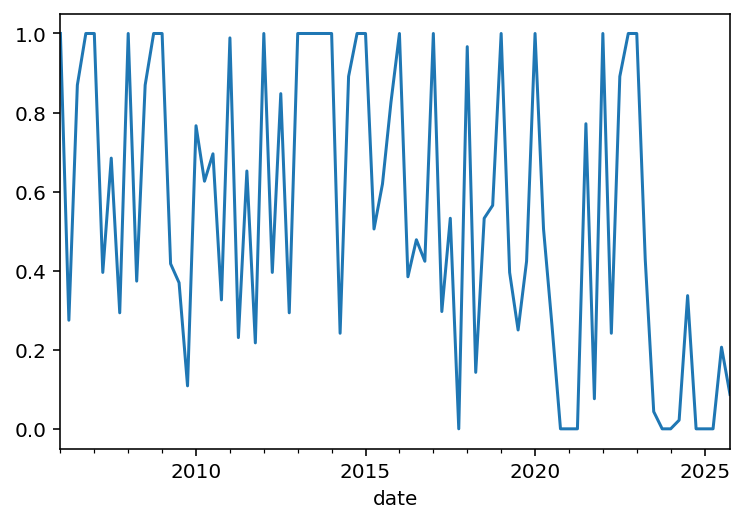

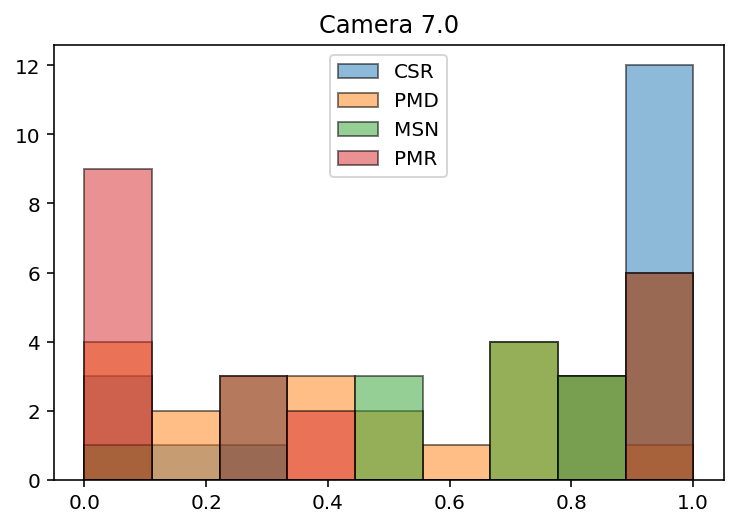

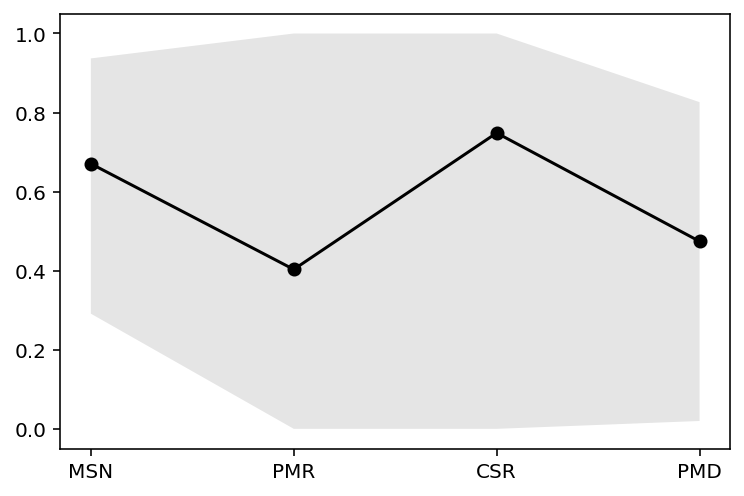

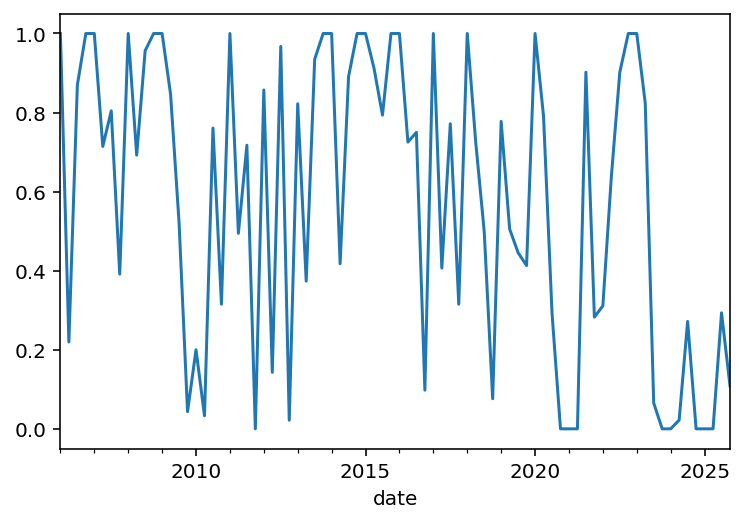

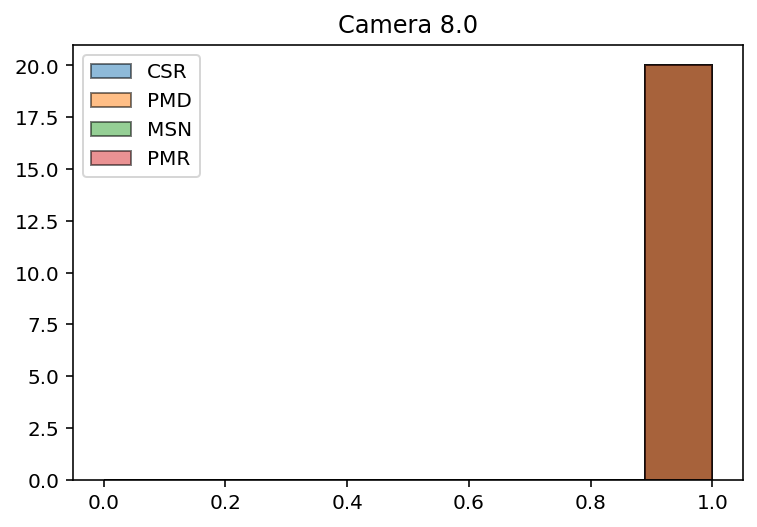

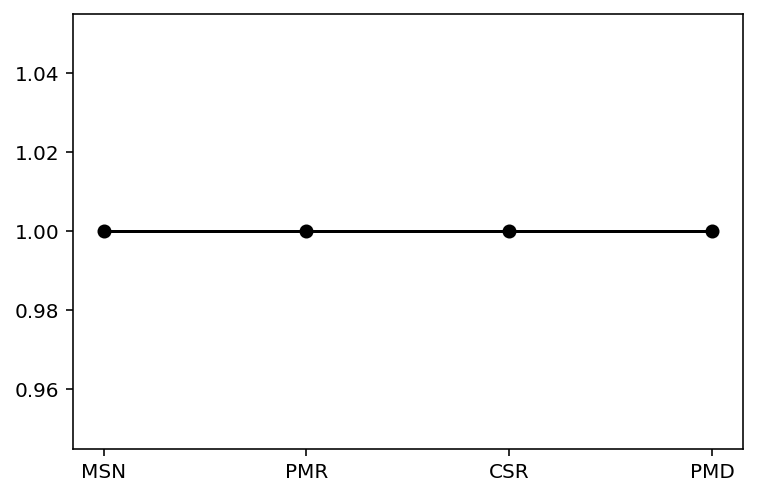

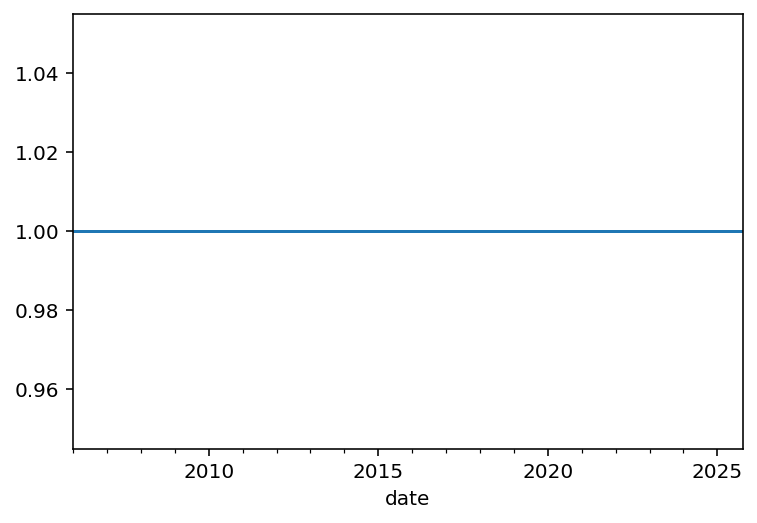

In [686]:
for c in stcam.Camera.unique():
    ssub = stcam[stcam.Camera==c]
    for ssn in ssub.season.unique():
        plt.hist(ssub[ssub.season==ssn].fp_final,bins = np.linspace(0,1,10),
                label = ssn,edgecolor = 'k',alpha=.5)
    plt.legend()
    plt.title('Camera '+str(c))
    plt.show()
    mm = ssub.groupby('season').mean().fp_final
    mm1 = ssub.groupby('season').quantile(.1).fp_final
    mm2 = ssub.groupby('season').quantile(.9).fp_final
    sss = ['MSN','PMR','CSR','PMD']
    plt.plot(sss,[mm.loc[s] for s in sss],marker='o',c='k')
    plt.fill_between(sss,[mm1.loc[s] for s in sss],
                     [mm2.loc[s] for s in sss],facecolor='k',alpha=.1)
    plt.show()
    ssub.fp_final.plot()
    plt.show()

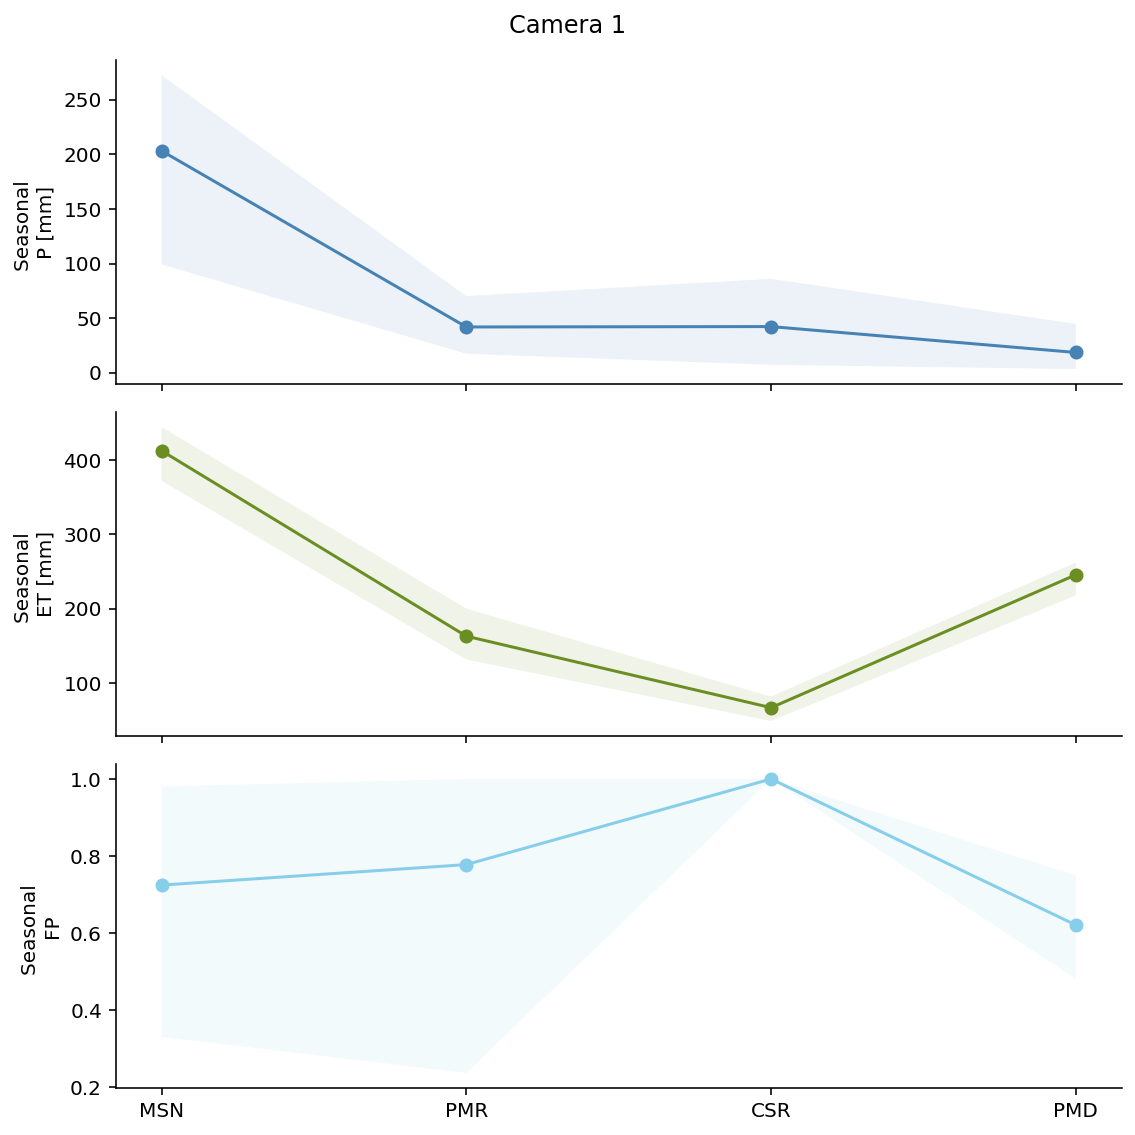

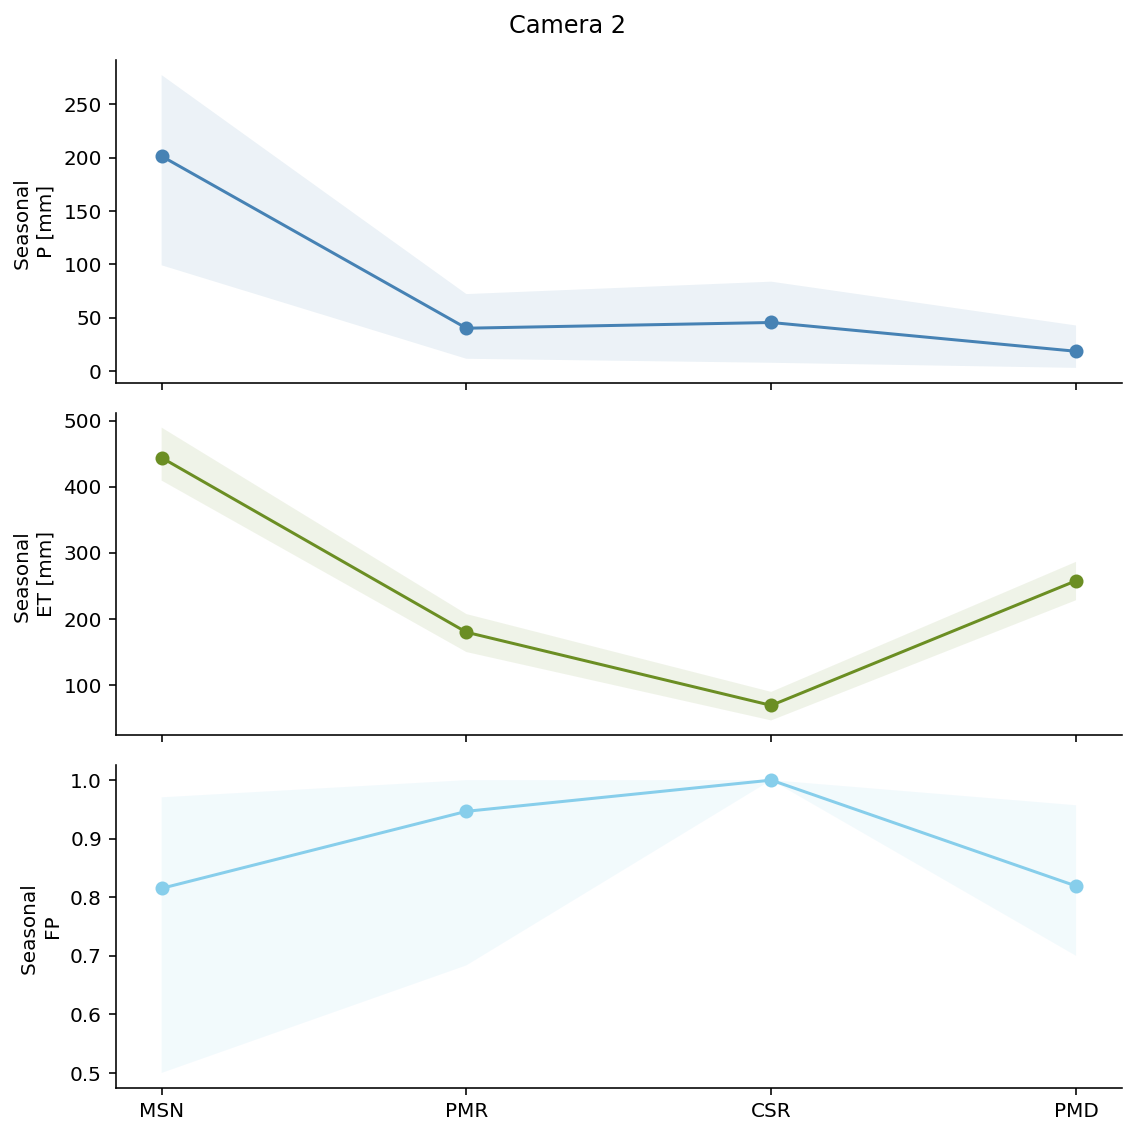

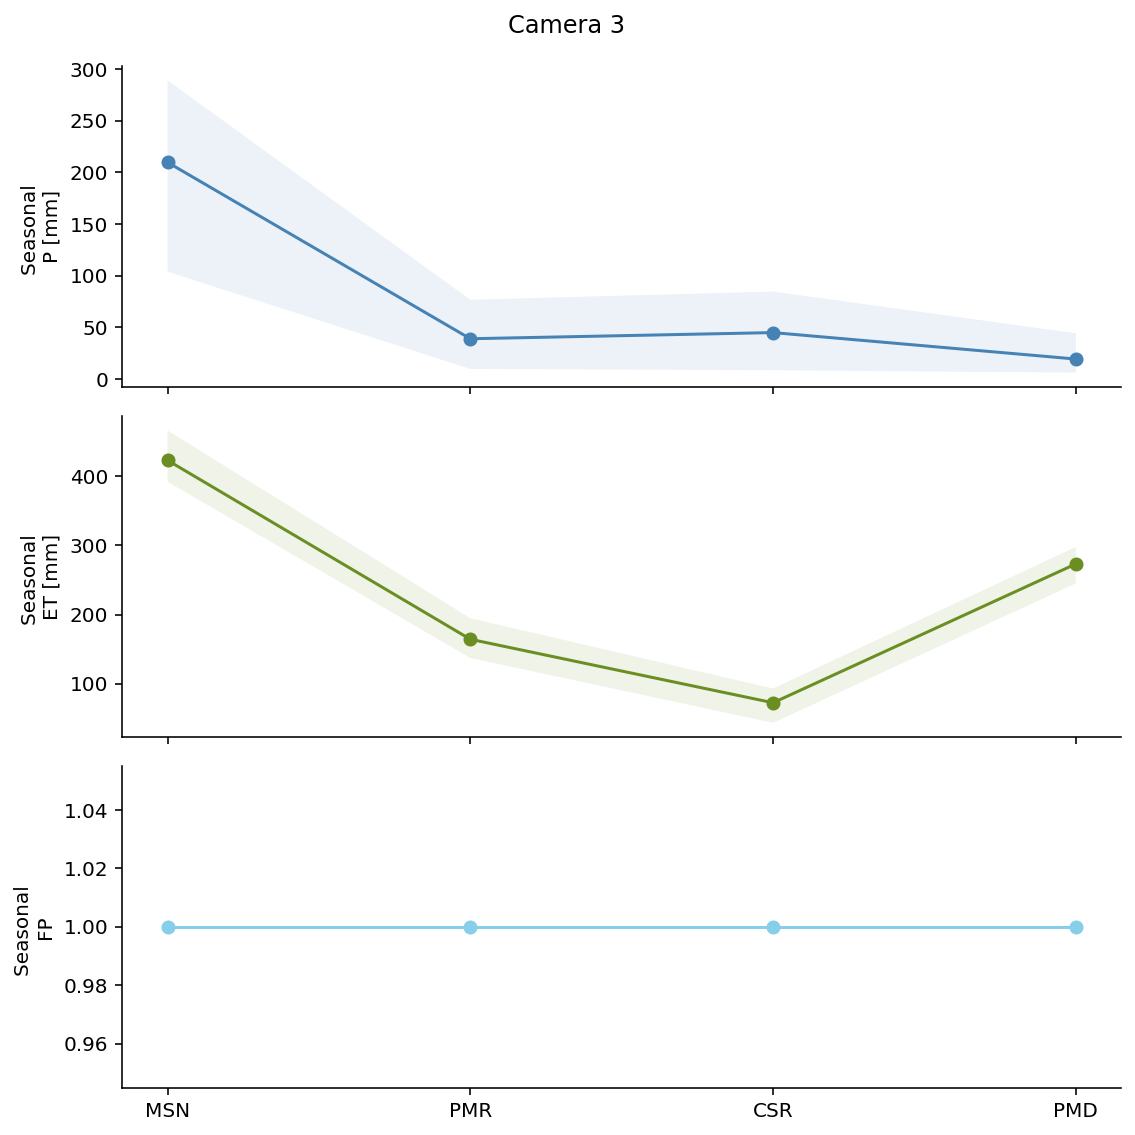

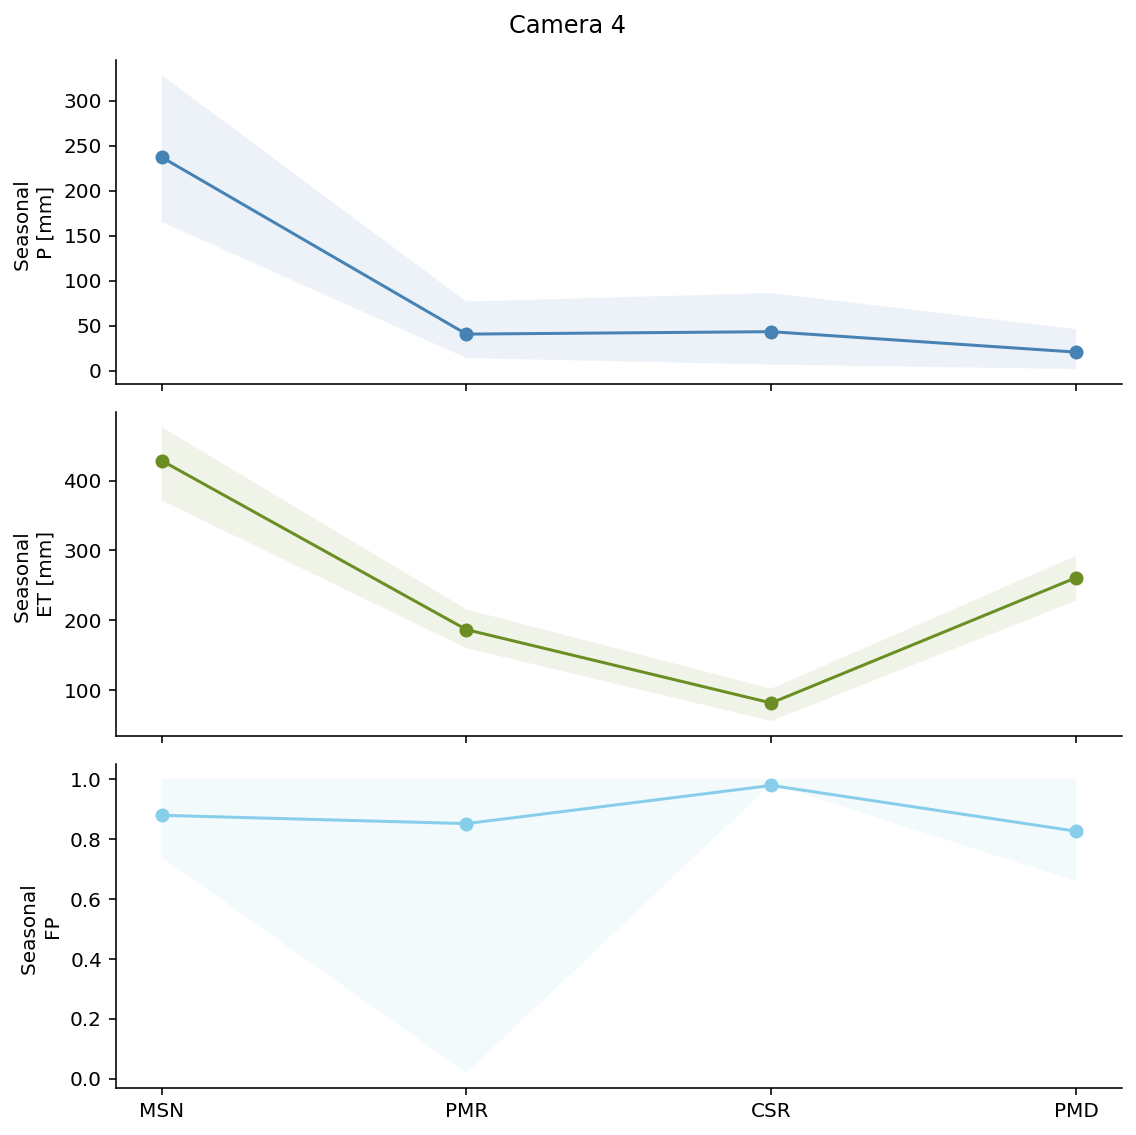

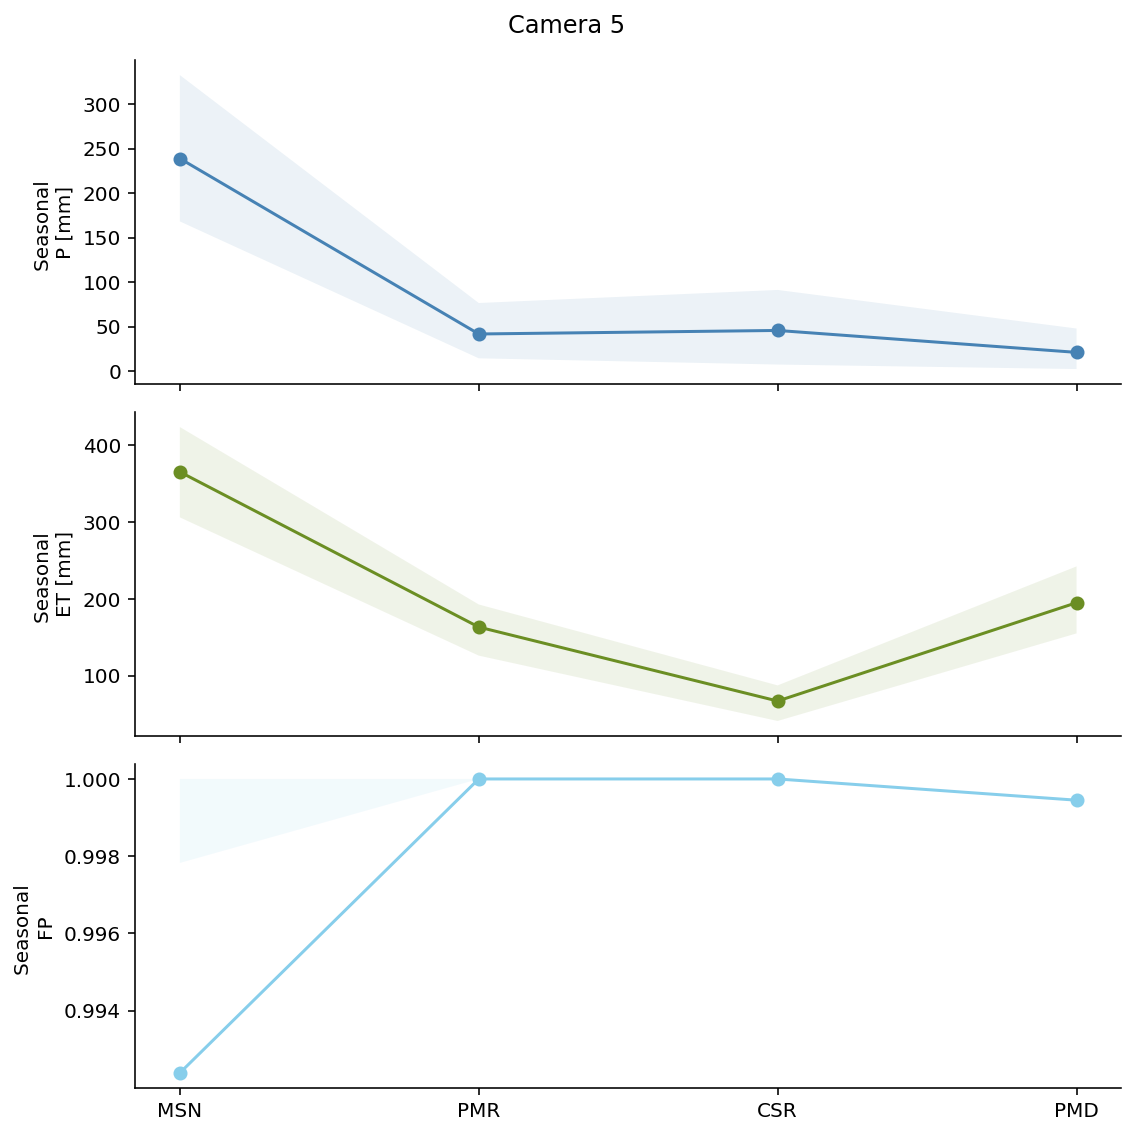

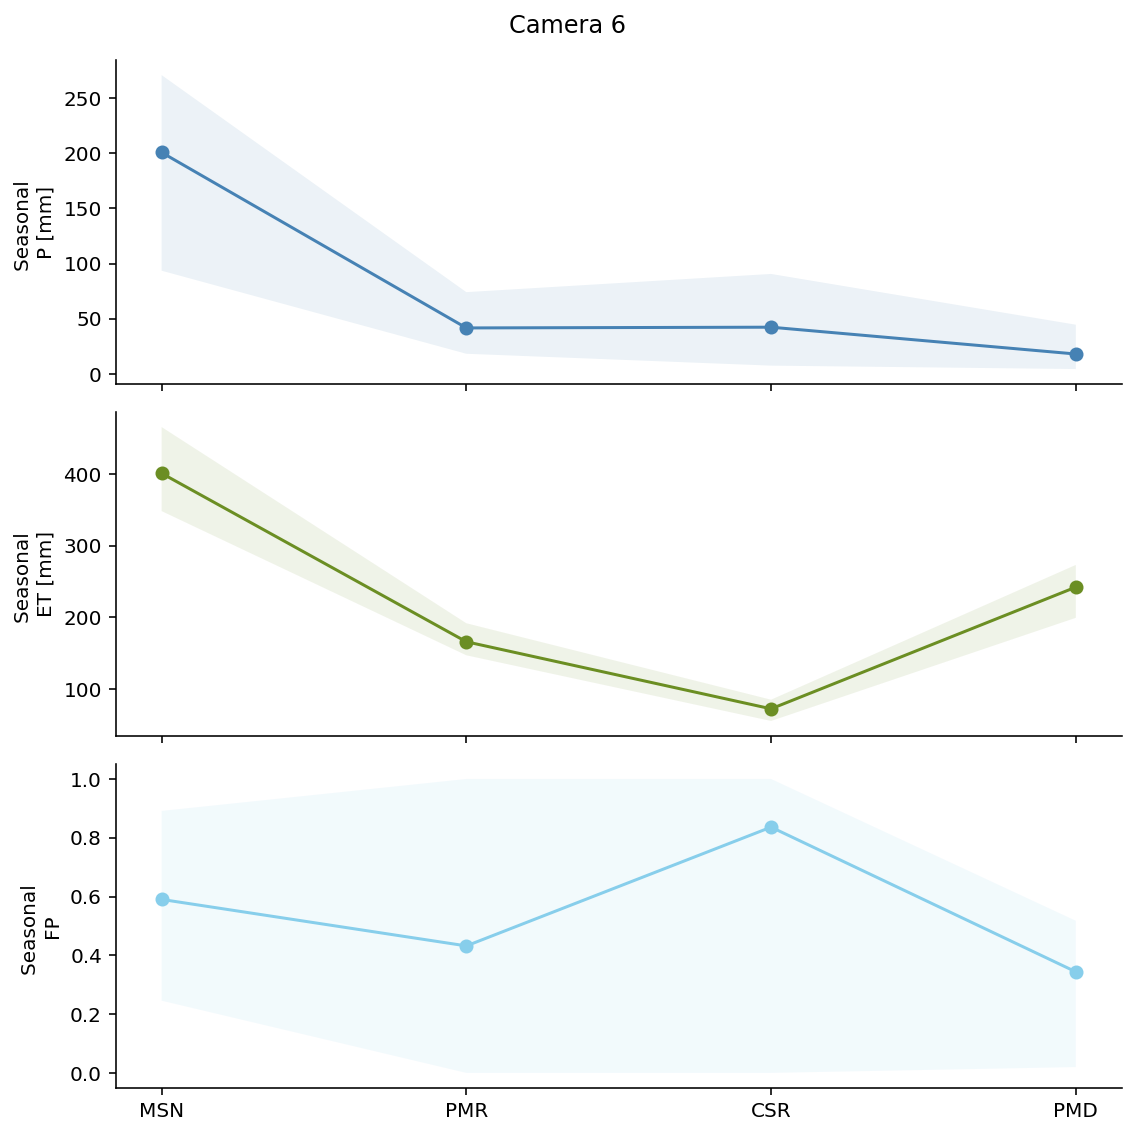

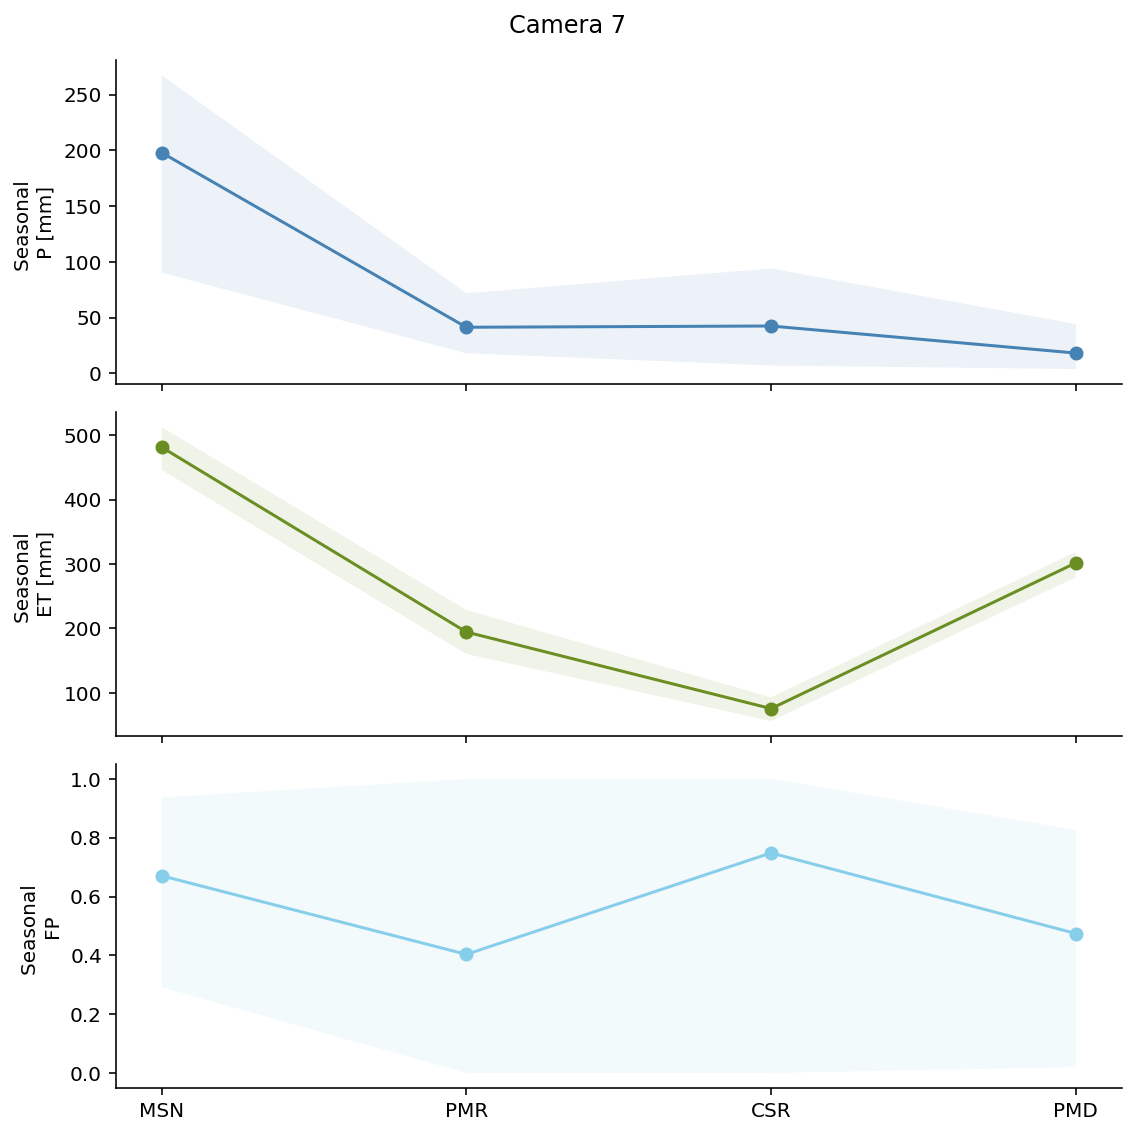

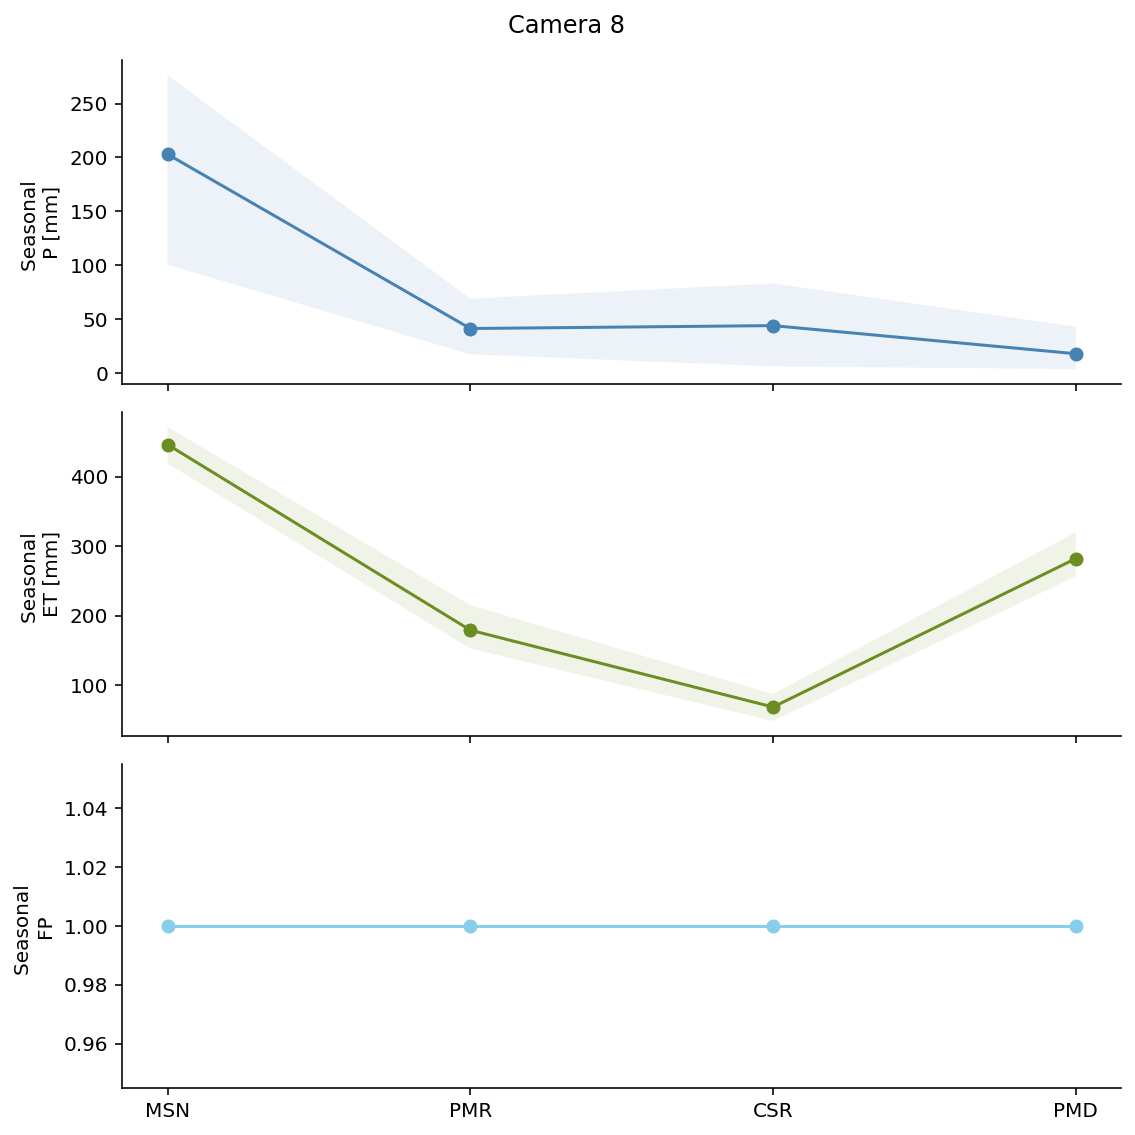

In [721]:
for c in stcam.Camera.unique():
    ssub = stcam[stcam.Camera==c]

    fig,axs = plt.subplots(3,figsize = (8,8),sharex=True)
    for i,col in enumerate(['prcp','et','fp_final']):
        ax = axs[i]
        mm = ssub.groupby('season').mean()[col]
        mm1 = ssub.groupby('season').quantile(.1)[col]
        mm2 = ssub.groupby('season').quantile(.9)[col]
        sss = ['MSN','PMR','CSR','PMD']
        labs = {'prcp':'P [mm]',
               'et': 'ET [mm]',
               'fp_final':'FP'}
        colors = {'prcp':'steelblue',
                 'et':'olivedrab',
                 'fp_final':'skyblue'}
    
        ax.plot(sss,[mm.loc[s] for s in sss],marker='o',c=colors[col])
        ax.fill_between(sss,[mm1.loc[s] for s in sss],
                         [mm2.loc[s] for s in sss],facecolor=colors[col]
                        ,alpha=.1)
        
        ax.set_ylabel('Seasonal \n'+labs[col])
        ax.spines[['top','right']].set_visible(False)
    fig.suptitle('Camera '+str(int(c)))
    fig.tight_layout()
    plt.show()


In [731]:
cameradata

,Site,date,wy,split,prcp,tmax,tmin,vpd,et,gw,q,fp,prob,prob_all,fp_final,source,Camera,season
0,Fairbank,2006-01-01,2006,train,0.00,21.11,2.28,1.358093,0.899288,0.633634,7.79,NaN,0.999770,0.999586,1.0,predicted,1,CSR
1,Fairbank,2006-01-02,2006,train,0.00,24.55,3.11,1.653308,0.896554,0.633207,7.68,NaN,0.999791,0.999612,1.0,predicted,1,CSR
2,Fairbank,2006-01-03,2006,train,0.00,21.02,3.85,1.361449,0.893819,0.632780,7.87,NaN,0.999788,0.999623,1.0,predicted,1,CSR
3,Fairbank,2006-01-04,2006,train,0.00,22.20,-1.89,1.420307,0.891085,0.632354,7.78,NaN,0.999742,0.999523,1.0,predicted,1,CSR
4,Fairbank,2006-01-05,2006,train,0.00,21.24,0.44,1.356812,0.888350,0.631927,7.65,NaN,0.999754,0.999557,1.0,predicted,1,CSR
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
58435,Boquillas,2025-12-27,2026,train,0.98,19.74,8.38,0.734451,1.434197,0.140208,0.00,NaN,0.999562,0.999891,1.0,predicted,8,PMR
58436,Boquillas,2025-12-28,2026,train,0.00,18.97,3.24,0.882057,1.399607,0.140208,0.00,NaN,0.999461,0.999872,1.0,predicted,8,PMR
58437,Boquillas,2025-12-29,2026,train,0.00,16.39,4.48,0.610774,1.365017,0.140208,0.00,NaN,0.999427,0.999871,1.0,predicted,8,PMR
58438,Boquillas,2025-12-30,2026,train,0.00,15.56,3.28,0.594854,1.330427,0.140208,0.00,NaN,0.999357,0.999859,1.0,predicted,8,PMR


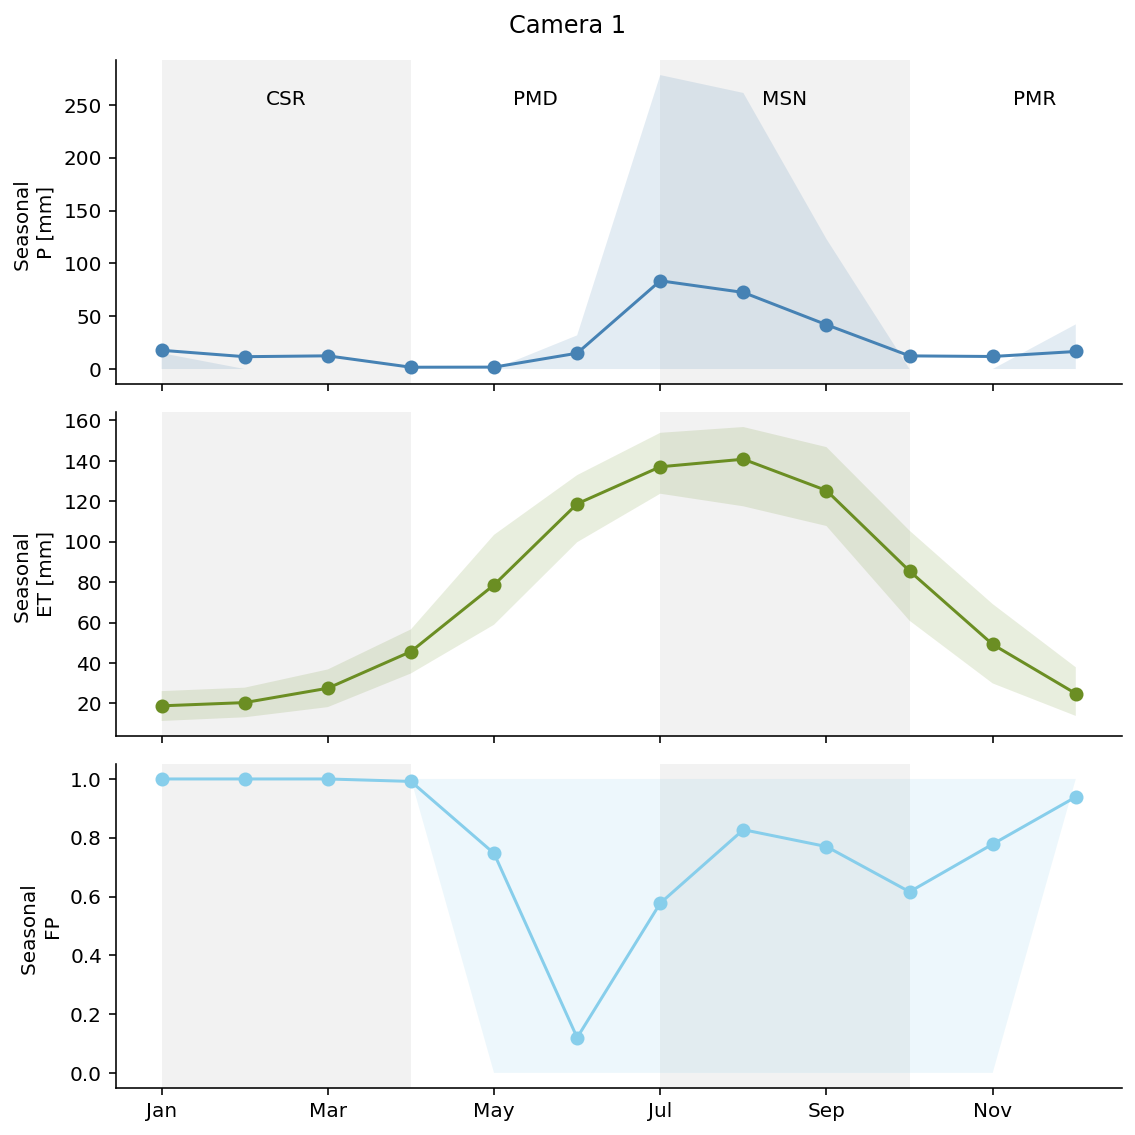

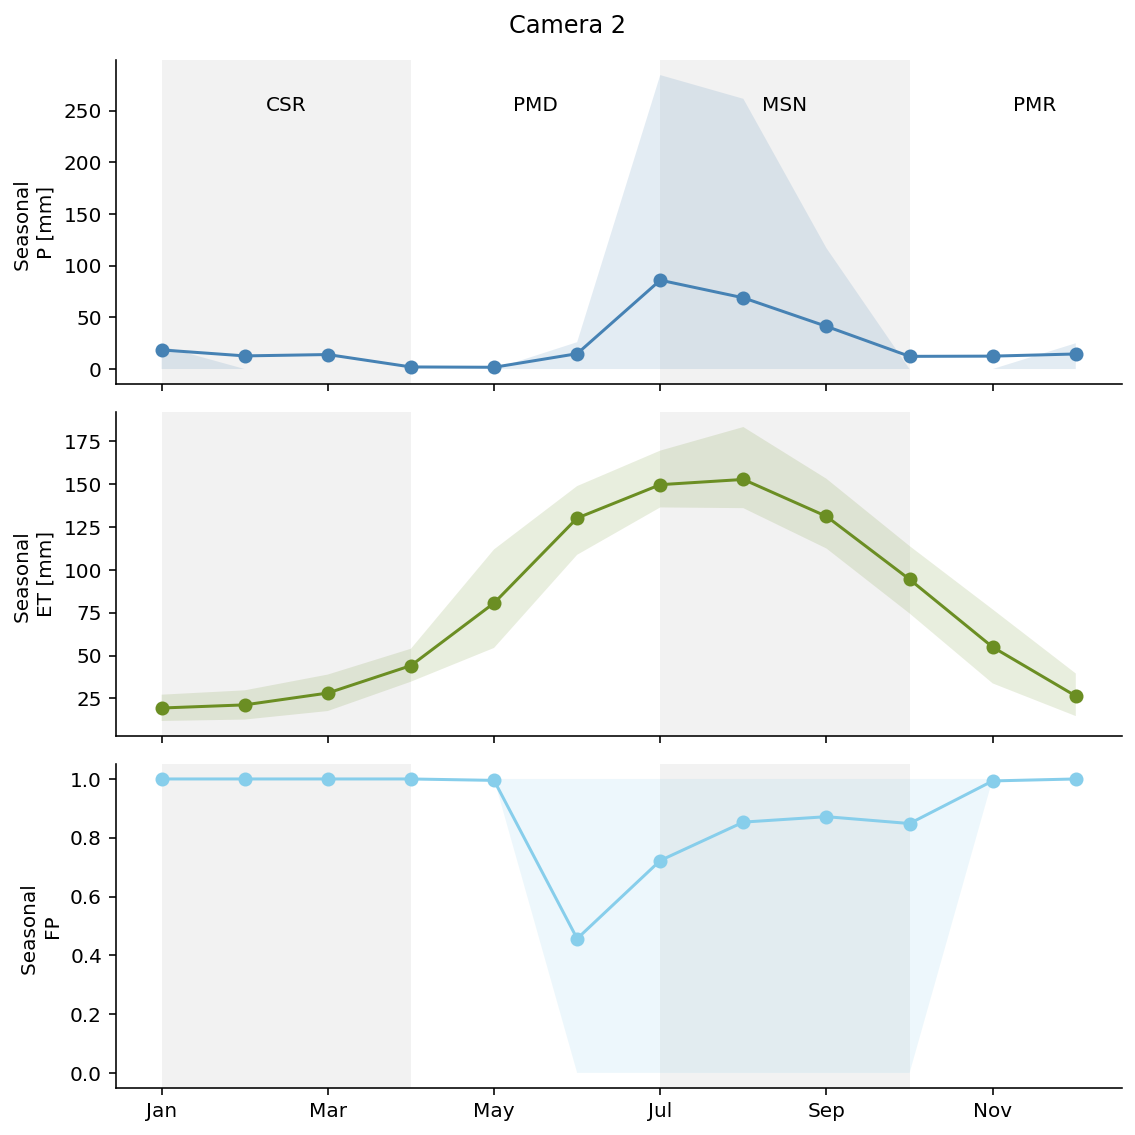

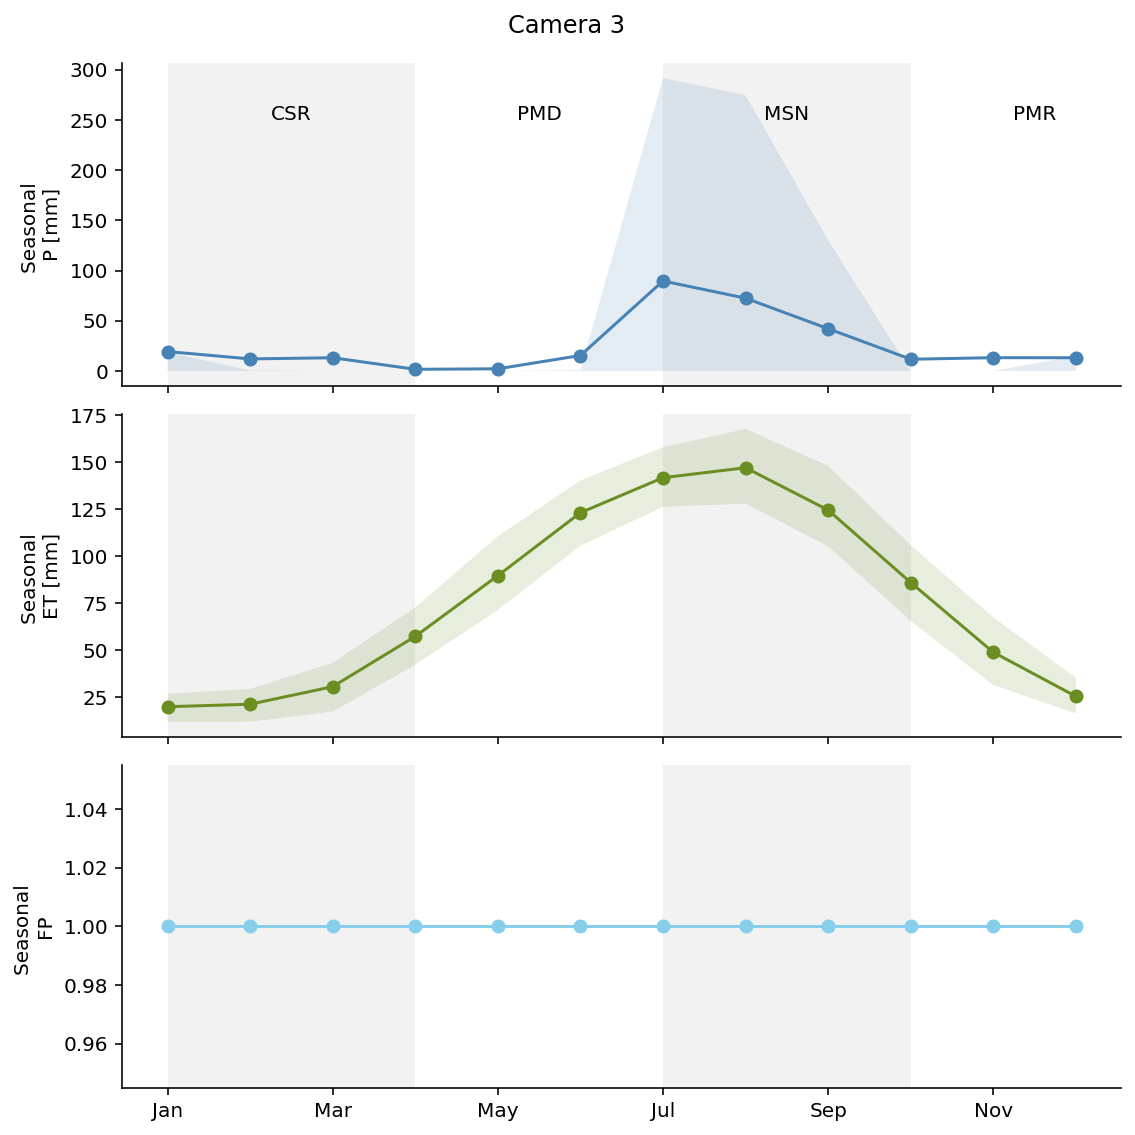

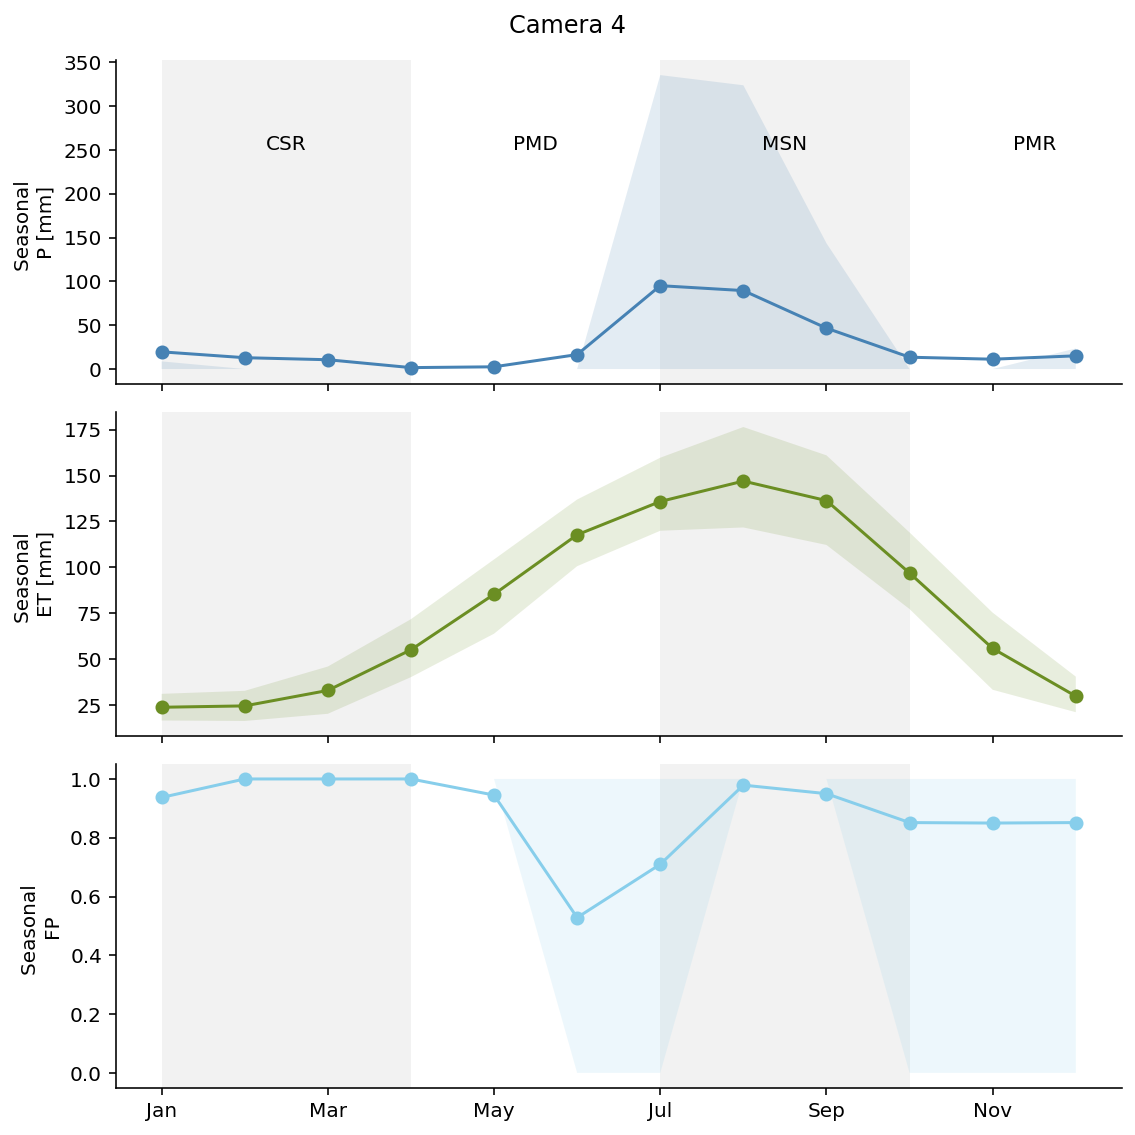

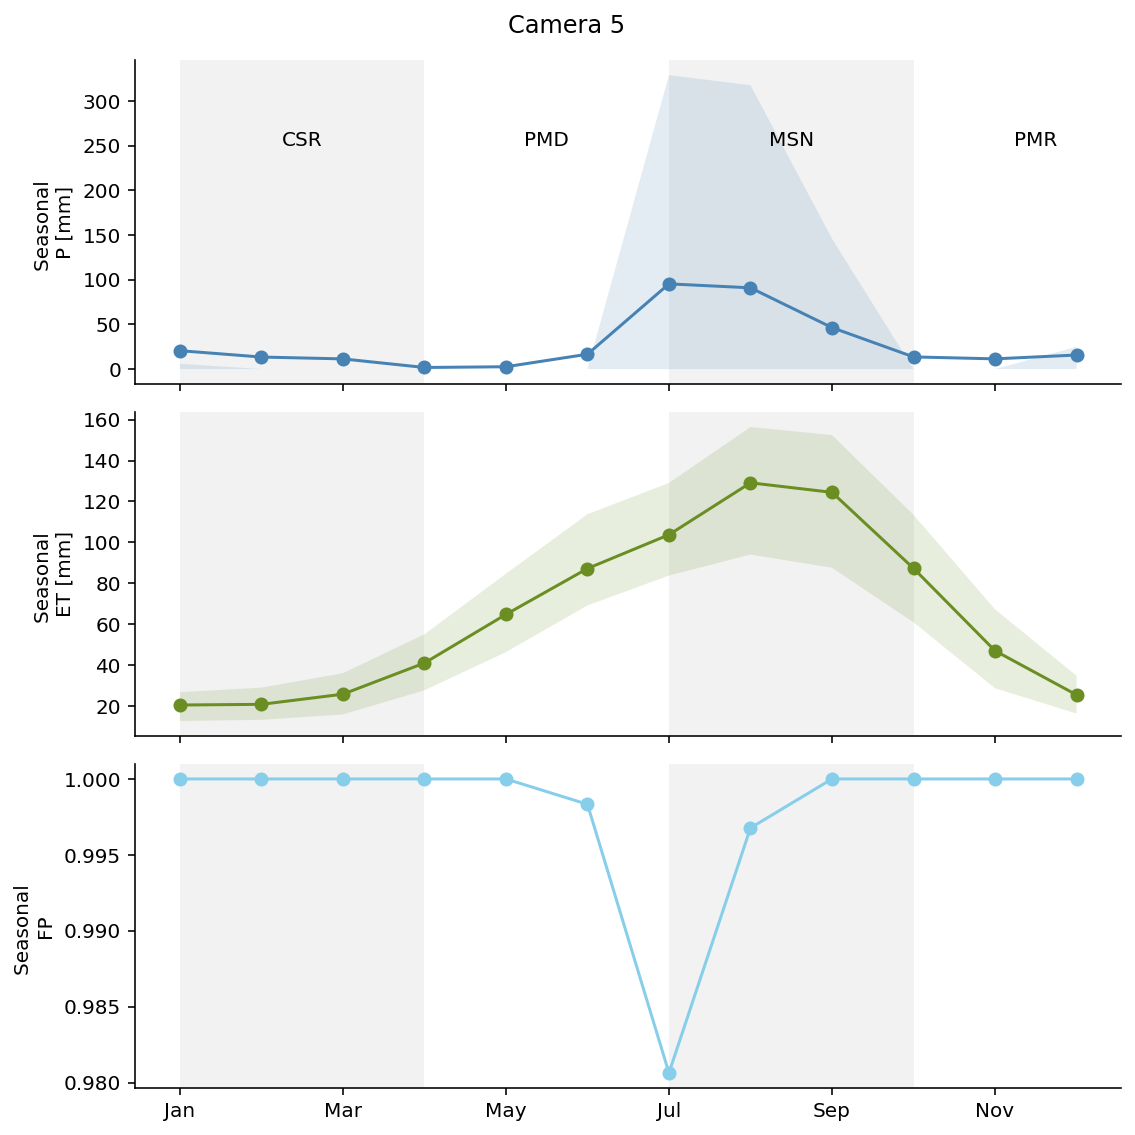

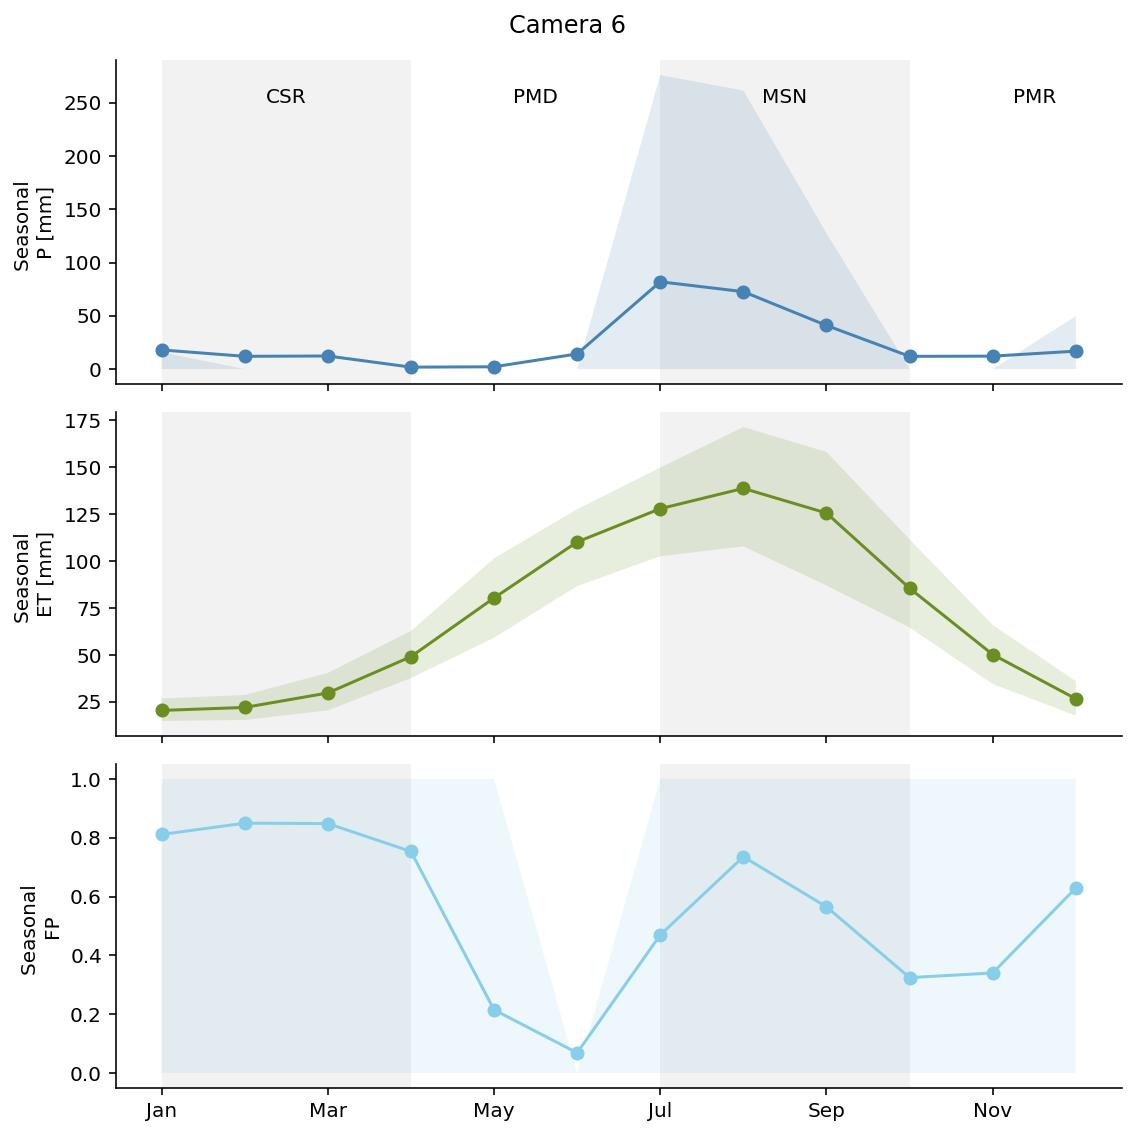

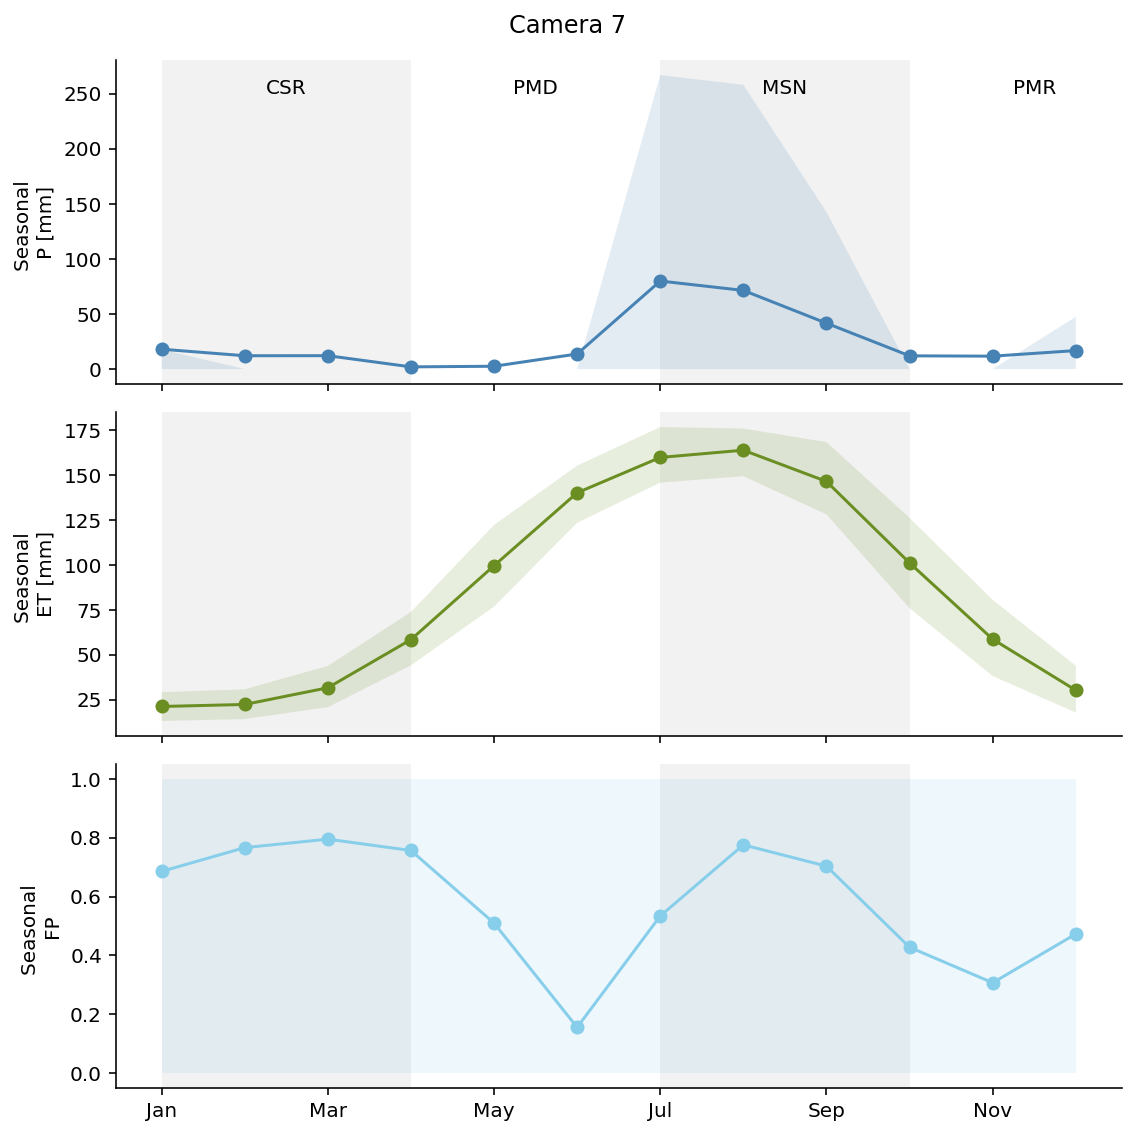

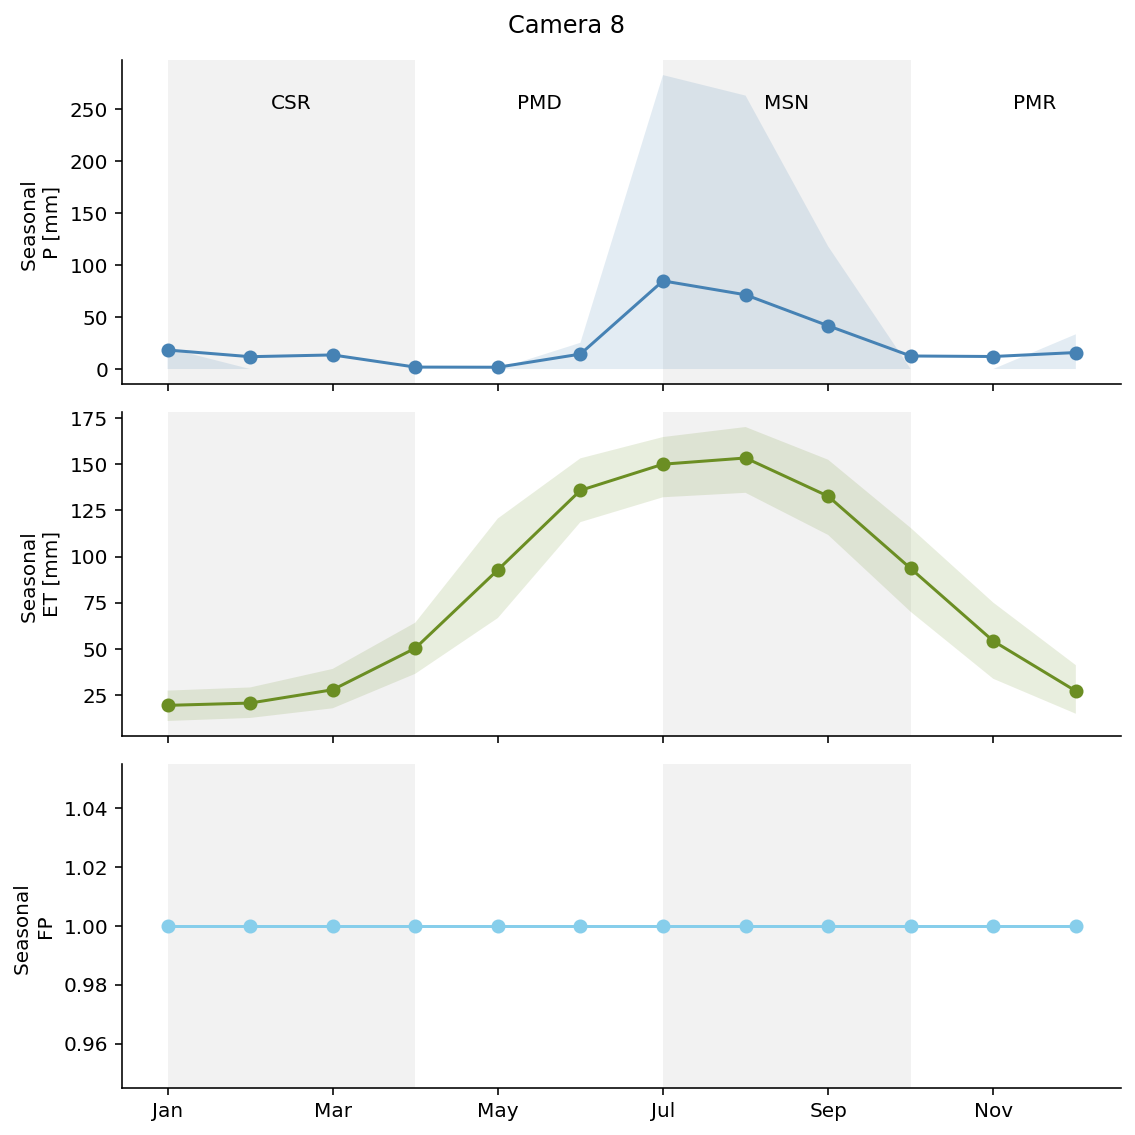

In [743]:
for c in stcam.Camera.unique():
    ssub = cameradata[cameradata.Camera==c].set_index('date').drop(columns=['source','Site','season'])

    fig,axs = plt.subplots(3,figsize = (8,8),sharex=True)
    for i,col in enumerate(['prcp','et','fp_final']):
        ax = axs[i]
        mm = ssub.groupby(ssub.index.month)[col].mean()
        
        mm1 = ssub.groupby(ssub.index.month)[col].quantile(.1)
        mm2 = ssub.groupby(ssub.index.month)[col].quantile(.9)
        if col in ['prcp','et']:
            mm = mm*30
            mm1 = mm1*30
            mm2 = mm2*30
        labs = {'prcp':'P [mm]',
               'et': 'ET [mm]',
               'fp_final':'FP'}
        colors = {'prcp':'steelblue',
                 'et':'olivedrab',
                 'fp_final':'skyblue'}
    
        ax.plot(mm,marker='o',c=colors[col])
        ax.fill_between(mm.index,mm1,mm2,facecolor=colors[col]
                        ,alpha=.15)
        
        ax.set_ylabel('Seasonal \n'+labs[col])
        ax.spines[['top','right']].set_visible(False)
        ax.set_xticks(list(range(1,13,2)))
        
        ax.axvspan(1,4,facecolor = 'k',alpha=.05,zorder = -1)
        ax.axvspan(7,10,facecolor = 'k',alpha=.05,zorder = -1)
        if i==0:
            ax.text(2.5,250,'CSR',ha='center')
            ax.text(5.5,250,'PMD',ha='center')
            ax.text(8.5,250,'MSN',ha='center')
            ax.text(11.5,250,'PMR',ha='center')
    fig.suptitle('Camera '+str(int(c)))
    ax.set_xticklabels(['Jan','Mar','May','Jul','Sep','Nov'])
    fig.tight_layout()
    plt.show()


In [724]:
ssub

,wy,prcp,tmax,tmin,vpd,et,gw,q,prob,prob_all,...,et_prev1,vpd_prev1,prcp_prev1,gw_prev1,gw_min_prev1,gw_max_prev1,prcp_prev2,prcp_prev3,prcp_prev4,season
date,,,,,,,,,,,,,,,,,,,,,
2006-01-01,2006.0,6.11,20.722000,1.251889,1.347442,80.003580,0.614642,9.417333,0.999783,0.999619,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,CSR
2006-04-01,2006.0,8.03,32.473736,12.470989,2.694566,256.730886,0.576018,1.430220,0.570983,0.582326,...,80.003580,1.347442,6.11,0.614642,0.595650,0.633634,NaN,NaN,NaN,PMD
2006-07-01,2006.0,254.84,31.876196,17.513152,1.902486,373.834732,0.707125,306.939130,0.754364,0.772387,...,256.730886,2.694566,8.03,0.576018,0.556813,0.595223,6.11,NaN,NaN,MSN
2006-10-01,2007.0,18.10,22.309130,3.738587,1.087553,165.696739,0.946658,13.397826,0.999838,0.999627,...,373.834732,1.902486,254.84,0.707125,0.527304,1.374648,8.03,6.11,NaN,PMR
2007-01-01,2007.0,60.35,18.707889,0.943111,1.008678,72.808798,1.130902,11.945222,0.999855,0.999682,...,165.696739,1.087553,18.10,0.946658,0.658368,1.200912,254.84,8.03,6.11,CSR
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2024-10-01,2025.0,10.92,25.478533,4.787609,1.622109,194.317446,0.066048,0.000000,0.283617,0.193350,...,431.515214,2.598112,114.85,0.202857,0.084697,0.366862,39.55,84.93,37.18,PMR
2025-01-01,2025.0,2.34,21.195333,1.272111,1.351691,94.550457,0.276173,0.000000,0.996221,0.986528,...,194.317446,1.622109,10.92,0.066048,0.006096,0.145985,114.85,39.55,84.93,CSR
2025-04-01,2025.0,14.91,31.740879,12.275824,2.640731,257.890387,0.427339,0.000000,0.712329,0.424884,...,94.550457,1.351691,2.34,0.276173,0.148278,0.451358,10.92,114.85,39.55,PMD


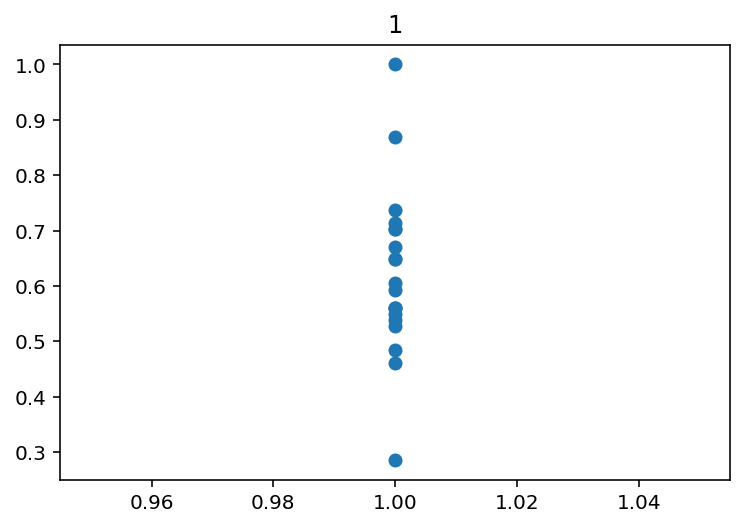

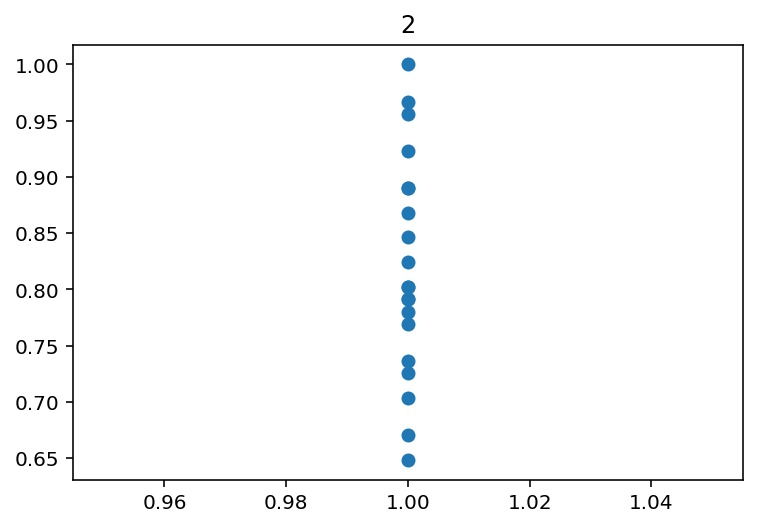

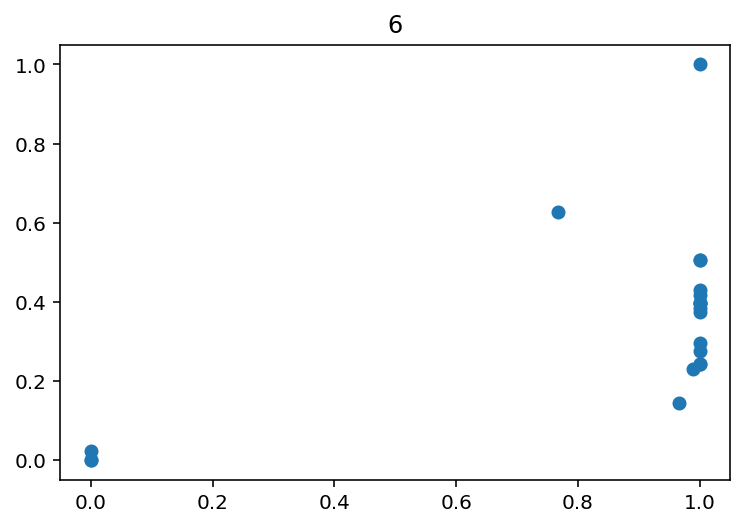

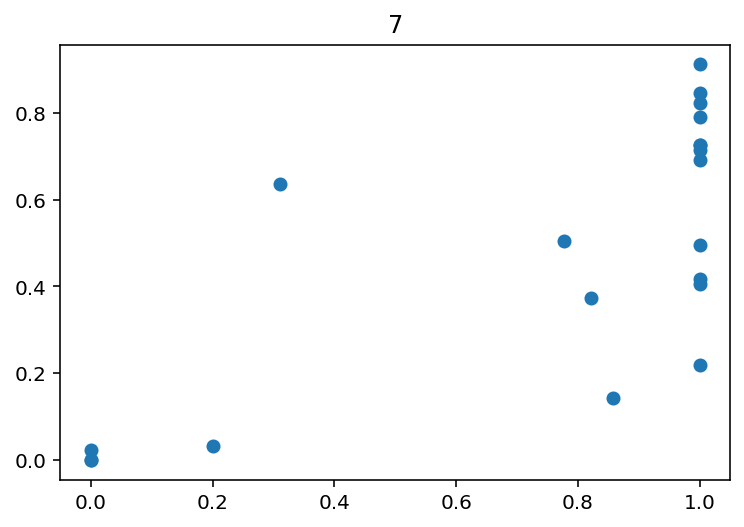

In [710]:
for c in [1,2,6,7]:
    ss = stcam[(stcam.Camera==c)]
    plt.scatter(ss[ss.season=='CSR'].fp_final,
               ss[ss.season=='PMD'].fp_final)
    plt.title(c)
    plt.show()